<a href="https://colab.research.google.com/github/Gaborgalo/szakdoga/blob/main/Gabor_Galovics_Thesis_work_3_FIXED(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting airfare prices

*by Gábor Galovics, supervised by Evelin Berekméri*

The objective of this project is to predict flight ticket prices of an extensive dataset containing American domestic flights between 5 airports. The dataset consists of web-scraped flight information collected between 2022-04-16 and 2022-10-05 (source: https://www.kaggle.com/datasets/dilwong/flightprices). The project follows a structured machine learning workflow, outlined as follows:

1. Data Understanding and Preparation
- Initial exploration of the dataset, including data cleaning, exploratory data analysis (EDA), feature engineering, and transformation of variables.
Key patterns and relationships will be visualized to gain insights into factors influencing flight prices.

2. Price prediction
- Comparing the tabular XGBoost model with time series deep-learning models (GRU, LSTM and 1D CNN). The goal of this section is to predict the price of a specific flight with given parameters.

3. Optimal buy time prediction
- This section aims to predict the price trajectory for a given itinerary. A recursive XGBoost modeling framework, and sequential GRU, LSTM and 1D CNN models are compared.

4. Model Selection and Interpretation
- Comparison of model performance using appropriate evaluation metrics to select the best-performing model. Model interpretability will be emphasized to identify the most influential factors affecting ticket prices.

## Revision notes (corrections applied to the previous version)

1. **Target.** The previous version fed differenced lags to the models but still predicted the log-fare *level*, and removed every level from the inputs (including `lagged_fare_1`). Differences carry no level information, so the models had to guess the price level from route/airline features. The target is now the one-day change in log fare (`fareChange`), and the price forecast is `lagged_fare_1 + predicted change`.
2. **Evaluation.** All models are scored on the change and on a skill score against persistence on the same rows. R^2 of the price level is no longer used as the headline metric.
3. **Leak-prone / non-stationary columns removed.** `rollingTrend` (contains today's fare) and `rollingMean3` (a level) are gone; `rollingStd3` is now the std of the previous three *changes*; the pre-log duplicate feature cell was removed.
4. **DL pipeline.** Targets are standardised with train statistics; the loader no longer reorders batches (so predictions stay aligned with their anchors), GRU/LSTM pack with `enforce_sorted=False`.
5. **CNN.** Padding is now explicitly zeroed before each convolution and after each activation. The stored CNN output (validation loss about 2.0 against a training loss of 0.34, only two epochs) did not come from a finished run of the current code and was cleared; re-run it with the standardised change target.
6. **Transformer.** Pre-LN, positions measured as distance to the target, target-token + masked-mean pooling, linear warm-up.
7. **Stationarity.** Random itinerary sample instead of the 100 longest, KPSS added next to ADF, a panel test, an over-differencing check and a pooled weekly drift check.
8. **Stale outputs** of the buy-time cells were cleared; they came from an older run and have to be recomputed (re-run from the sequence-building cell onwards).


## Installing and loading libraries

## Reuse prepared datasets instead of rebuilding them

Run the next **cache startup** cell first. It loads model-ready train/validation/test inputs, the separate calibration inputs, one-day DL histories, stacking data, buy-time episodes and sequential/Q-learning states from `datasets/prepared` in this GitHub checkout when present. It also checks a persistent Drive cache. On a cache hit, original Spark/preparation cells below skip their work; the existing model cells train directly on the restored inputs. No trained weights or credentials are included.

For the **first export**, run cache startup, the original dependency-install cell if needed, then **Build/export all prepared datasets once**. If all prepared globals already exist in your Colab session, export reuses them (stacking inputs may be assembled once). Otherwise it executes only the necessary preparation cells, not EDA plots, model training, Optuna or Q fitting. The exported cache is saved to mounted Drive when available, so it survives a Colab reset. Publishing to GitHub is an explicit option in the export cell; it uses existing Git authentication and never asks for a token in the notebook/chat.

The cache is one logical compressed dataset archive, split into **40 MiB files** plus a checksummed manifest to stay below GitHub's per-file limit. GitHub publication refuses caches above 500 MiB; use Drive/local persistent storage for larger data. The actual compressed size is printed, not guessed. Changing saved feature/split/window code invalidates the cache, while changing model hyperparameters does not. Change `DATASET_CACHE_SOURCE_ID` when replacing the raw dataset. If you edit preparation cells in the Colab editor without saving those changes to the repository checkout, set `DATASET_CACHE_FORCE_REBUILD=True` and save/update the checkout before trusting fingerprints.

The raw parquet and prepared arrays are **not currently available in the cloud checkout**, so this code change cannot manufacture or publish the first real dataset archive. Create it once in the prepared Colab session. Spark-specific EDA, CV and old Spark-derived feature-name plots intentionally require a rebuild; cached training/evaluation for all model families, including stacking and Q replay, does not require Spark. The startup cell imports helpers from the checked-out notebook, so keep that checkout updated when opening a newer notebook version.


In [ ]:
# Dataset cache startup: safe to run without Spark or the raw parquet.
import os
from pathlib import Path
import subprocess
import sys

DATASET_CACHE_FORCE_REBUILD = False
DATASET_CACHE_SOURCE_ID = 'airfare-top5-v1'
DATASET_CACHE_LOADED = False
candidates = [Path.cwd(), Path('/workspace/szakdoga'), Path('/content/szakdoga')]
DATASET_REPO_DIR = next((p for p in candidates if (p/'dataset_cache.py').is_file()), None)
if DATASET_REPO_DIR is None:
    DATASET_REPO_DIR = Path('/content/szakdoga') if Path('/content').is_dir() else Path.cwd()/'szakdoga-cache-checkout'
    if DATASET_REPO_DIR.exists():
        raise RuntimeError('Set DATASET_REPO_DIR to an up-to-date checkout containing dataset_cache.py; existing files were preserved.')
    result = subprocess.run(['git','clone','--depth','1','https://github.com/Gaborgalo/szakdoga.git',str(DATASET_REPO_DIR)],
                            env=dict(os.environ,GIT_TERMINAL_PROMPT='0'),capture_output=True,text=True)
    if result.returncode:
        raise RuntimeError('Cannot obtain the repository checkout. Clone it with your existing Git access and set DATASET_REPO_DIR; no token is needed in chat.')
sys.path.insert(0,str(DATASET_REPO_DIR))
import dataset_cache as model_cache
DATASET_NOTEBOOK_PATH = DATASET_REPO_DIR/model_cache.NOTEBOOK_NAME
DATASET_CACHE_REGISTRY = model_cache.bootstrap_definitions(globals(), DATASET_NOTEBOOK_PATH)
DATASET_CACHE_FINGERPRINT = model_cache.preparation_fingerprint(DATASET_NOTEBOOK_PATH,DATASET_CACHE_SOURCE_ID)
DATASET_CACHE_BUILD_IDS = ['35cd6355', '4hdRvBf8eQn7', 'WMLb5o3tZe5D', 'tq5Q2C_VG9Qh', '6w-Rx8h_WQQ3', 'CaYKEmaCVkgv', '4uiZw7k7s4_0', '4CBntgUEKZnu', 'Ih1rlefwbua0', '0f1PugSYyE06', '810jqa5ur0HN', 'r1nWr79-sbbQ', '1_saZgBSr0HO', 'SGd0z2VVr0HP', 'YAkOmH9MarQQ', 'K8RoQ9aGtbJ-', 'cde782f4', 'HWpa7YkIr0He', 'uO6BL8LJr0Hf', 'd7dbdb5e0b7d', 'efa6586699d3']
DATASET_CACHE_DRIVE_DIR = Path('/content/drive/MyDrive/szakdoga_prepared_cache')
DATASET_CACHE_DIR = Path(os.environ.get('FLIGHT_CACHE_DIR',str(DATASET_REPO_DIR/'datasets'/'prepared')))
# A large cache may live only on Drive. Mount it before falling back to Spark rebuilding.
if not (DATASET_CACHE_DIR/'manifest.json').is_file() and Path('/content').is_dir() and not DATASET_CACHE_DRIVE_DIR.parent.is_dir():
    try:
        from google.colab import drive as cache_drive
        cache_drive.mount('/content/drive')
    except ImportError:
        pass
cache_candidates = [DATASET_CACHE_DIR,DATASET_CACHE_DRIVE_DIR]
if not DATASET_CACHE_FORCE_REBUILD:
    for cache_path in cache_candidates:
        if not (cache_path/'manifest.json').is_file():
            continue
        try:
            cached_state = model_cache.load_cache(cache_path,DATASET_CACHE_FINGERPRINT,DATASET_CACHE_REGISTRY)
            model_cache.restore_model_data(cached_state,globals())
            del cached_state
            DATASET_CACHE_DIR = cache_path
            print(f'Loaded every prepared model dataset from {cache_path}; Spark preparation will be skipped.')
            break
        except model_cache.CacheMismatch as error:
            print(f'Cache not used: {error}')
if not DATASET_CACHE_LOADED:
    print('No matching prepared cache loaded. If the cache is on Drive, mount Drive and rerun this cell; otherwise run the build/export cell once.')


In [1]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Dependencies are installed by the cloud setup script.
    # In Colab, uncomment the following command if needed:
    %pip install pyspark xgboost pyarrow optuna statsmodels shap
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 31.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 26.5 MB/s eta 0:00:00


## Build/export all prepared datasets once

Run this only for the first cache or an intentional rebuild. `PUBLISH_DATASET_CACHE=True` publishes verified cache files to GitHub **if** the cache is within the size budget and this checkout has Git identity/push access configured. No force push is used; unrelated staged files block publication. A failed push never deletes the persistent cache. On later sessions, startup loads that archive and this cell does no rebuilding.


In [ ]:
# Build/export datasets only; no model is fitted by this cell.
PUBLISH_DATASET_CACHE = False  # set True for the first GitHub upload after checking size/counts
if DATASET_CACHE_LOADED:
    print(f'Datasets already restored from {DATASET_CACHE_DIR}; no preparation/export needed.')
else:
    ready_names = ('X_train_np','xgb_train_pd_no_ts','X_train_list_dl','buytime_bundles',
                   'tabular_q_data','df_processed_dl_all','stack_target_keys')
    if all(name in globals() for name in ready_names):
        model_dataset_state = model_cache.snapshot_model_data(globals())
    else:
        model_dataset_state = model_cache.build_model_data(globals(),DATASET_NOTEBOOK_PATH)
    export_path = DATASET_CACHE_DRIVE_DIR if DATASET_CACHE_DRIVE_DIR.parent.is_dir() else DATASET_CACHE_DIR
    manifest = model_cache.save_cache(export_path,model_dataset_state,DATASET_CACHE_FINGERPRINT,
                                     overwrite=(export_path/'manifest.json').exists())
    model_cache.restore_model_data(model_dataset_state,globals())
    del model_dataset_state
    DATASET_CACHE_DIR = export_path
    print(f'All model datasets saved: {manifest["compressed_bytes"]/1024**2:.1f} MiB in {len(manifest["parts"])} parts at {export_path}')
if PUBLISH_DATASET_CACHE:
    try:
        commit = model_cache.publish_cache(export_path,DATASET_REPO_DIR)
        print(f'Prepared datasets pushed to GitHub main: {commit}')
    except (ValueError,FileExistsError,subprocess.CalledProcessError) as error:
        print(f'Cache remains saved at {export_path}. GitHub publication did not complete: {type(error).__name__}. '
              'Check size, Git identity/authentication, staged files and remote updates; never paste credentials into chat.')


In [2]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    import math
    import collections
    from functools import reduce
    from operator import add
    import matplotlib.pyplot as plt
    import pandas as pd
    import seaborn as sns
    import optuna
    import xgboost as xgb
    import numpy as np
    from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, log_loss
    from sklearn.model_selection import TimeSeriesSplit
    from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
    from pyspark.ml import Pipeline
    from pyspark.sql.functions import col, dayofweek, dayofmonth, weekofyear, sin, cos, pi, hour, minute, to_timestamp, log, split, element_at, size, sum, expr, try_to_timestamp, lit, coalesce, regexp_extract, unix_timestamp, from_unixtime, countDistinct, min, avg, datediff, ntile, count, lag, to_date, when, udf, collect_list, percent_rank, stddev, percentile_approx, array, struct, explode
    import pyspark.sql.functions as F
    from pyspark.sql.types import IntegerType, FloatType, DoubleType, BooleanType, StringType, ArrayType, StructType, StructField
    from pyspark.sql import Window, SparkSession
    from pyspark.ml.linalg import Vectors, VectorUDT
    from builtins import min as builtin_min
    import torch
    import torch.nn as nn
    import torch.optim as optim
    import os
    try:
        from google.colab import drive
    except ImportError:
        drive = None
    from torch.nn.utils.rnn import (
        pad_sequence,
        pack_padded_sequence,
        pad_packed_sequence
    )
    from torch.utils.data import DataLoader, Dataset
    from sklearn.metrics import (
        mean_squared_error,
        mean_absolute_error,
        r2_score
    )
    import gc
    import shap
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


In [3]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    if drive is not None:
        drive.mount('/content/drive')
    else:
        print('Cloud/local runtime: set FLIGHT_DATA_PATH to the prepared parquet dataset.')
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


Mounted at /content/drive


In [4]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    from pyspark.sql import SparkSession
    
    spark = (
        SparkSession.builder
        .master(os.environ.get("SPARK_MASTER", "local[4]"))
        .appName("price_prediction")
        .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "12g"))
        .config("spark.executor.memory", os.environ.get("SPARK_DRIVER_MEMORY", "12g"))
        .config("spark.driver.maxResultSize", "4g")
        .config("spark.sql.shuffle.partitions", "32")
        .getOrCreate()
    )
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


# EDA & preprocessing the dataset

In [5]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    DATA_PATH = os.environ.get('FLIGHT_DATA_PATH', '/content/drive/MyDrive/df_top5_mod.parquet')
    if not os.path.exists(DATA_PATH):
        raise FileNotFoundError(
            f'Prepared airfare parquet dataset not found: {DATA_PATH}. '
            'Mount Google Drive in Colab, or set FLIGHT_DATA_PATH in the cloud environment.'
        )
    df_top5_mod = spark.read.parquet(DATA_PATH)
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


In [6]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    df_top5_mod.printSchema()
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


root
 |-- legId: string (nullable = true)
 |-- flightDate: date (nullable = true)
 |-- searchDate: date (nullable = true)
 |-- startingAirport: string (nullable = true)
 |-- destinationAirport: string (nullable = true)
 |-- elapsedDays: integer (nullable = true)
 |-- isBasicEconomy: boolean (nullable = true)
 |-- isRefundable: boolean (nullable = true)
 |-- isNonStop: boolean (nullable = true)
 |-- baseFare: float (nullable = true)
 |-- totalFare: float (nullable = true)
 |-- seatsRemaining: integer (nullable = true)
 |-- totalTravelDistance: float (nullable = true)
 |-- segmentsDepartureTimeRaw: string (nullable = true)
 |-- segmentsArrivalTimeRaw: string (nullable = true)
 |-- segmentsDepartureAirportCode: string (nullable = true)
 |-- segmentsAirlineCode: string (nullable = true)
 |-- segmentsDurationInSeconds: string (nullable = true)
 |-- segmentsDistance: string (nullable = true)
 |-- departureDateDistance: integer (nullable = true)
 |-- segmentsDepartureTimeRaw_array: array (nul

Columns that have unusable/duplicated information are dropped here.

In [7]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    columns_to_drop = [
        'segmentsDepartureTimeRaw',
        'segmentsArrivalTimeRaw',
        'segmentsDepartureAirportCode',
        'segmentsAirlineCode',
        'segmentsDurationInSeconds',
        'segmentsDistance',
        'segmentsDepartureTimeRaw_array',
        'segmentsArrivalTimeRaw_array',
        'segmentsDurationInSeconds_array',
        'segmentsDistance_array',
        'firstDepartureTime_raw_segment',
        'firstDepartureTime_utc',
        'timezone_offset_hours_dep',
        'finalArrivalTime_raw_segment',
        'finalArrivalTime_utc',
        'timezone_offset_hours_arr'
    ]
    
    df_top5_mod = df_top5_mod.drop(*columns_to_drop)
    
    print("Remaining schema after dropping segment and helping variables:")
    df_top5_mod.printSchema()
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


Remaining schema after dropping segment and helping variables:
root
 |-- legId: string (nullable = true)
 |-- flightDate: date (nullable = true)
 |-- searchDate: date (nullable = true)
 |-- startingAirport: string (nullable = true)
 |-- destinationAirport: string (nullable = true)
 |-- elapsedDays: integer (nullable = true)
 |-- isBasicEconomy: boolean (nullable = true)
 |-- isRefundable: boolean (nullable = true)
 |-- isNonStop: boolean (nullable = true)
 |-- baseFare: float (nullable = true)
 |-- totalFare: float (nullable = true)
 |-- seatsRemaining: integer (nullable = true)
 |-- totalTravelDistance: float (nullable = true)
 |-- departureDateDistance: integer (nullable = true)
 |-- firstDepartureTime: string (nullable = true)
 |-- finalArrivalTime: string (nullable = true)
 |-- totalTravelTime: integer (nullable = true)
 |-- totalDistance: double (nullable = true)
 |-- airline_UA_count: integer (nullable = true)
 |-- airline_NK_count: integer (nullable = true)
 |-- airline_AA_count

Searching for duplicate observations, of which none are found.

In [8]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Cast 'searchDate' and 'flightDate' to DateType for consistent comparison
    df_top5_mod = df_top5_mod \
        .withColumn('searchDate', to_date(col('searchDate'), 'yyyy-MM-dd')) \
        .withColumn('flightDate', to_date(col('flightDate'), 'yyyy-MM-dd'))
    
    # Get the number of rows before deduplication
    rows_before = df_top5_mod.count()
    
    # Drop duplicates based on 'legId', 'flightDate', and 'searchDate', keeping the first occurrence
    df_top5_mod = df_top5_mod.dropDuplicates(['legId', 'flightDate', 'searchDate'])
    
    # Get the number of rows after deduplication
    rows_after = df_top5_mod.count()
    
    print(f"Number of rows before deduplication: {rows_before}")
    print(f"Number of rows after deduplication: {rows_after}")
    print(f"Number of duplicate combinations removed: {rows_before - rows_after}")
    
    print("DataFrame after removing duplicate (legId, flightDate, searchDate) combinations:")
    df_top5_mod.show(5, truncate=False)
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


Number of rows before deduplication: 7799968
Number of rows after deduplication: 7799968
Number of duplicate combinations removed: 0
DataFrame after removing duplicate (legId, flightDate, searchDate) combinations:
+--------------------------------+----------+----------+---------------+------------------+-----------+--------------+------------+---------+--------+---------+--------------+-------------------+---------------------+-------------------+-------------------+---------------+-------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+-------------+
|legId                           |flightDate|searchDate|startingAirport|destinationAirport|elapsedDays|isBasicEconomy|isRefundable|isNonStop|baseFare|totalFare|seatsRemaining|totalTravelDistance|departureDateDistance|firstDepartureTime |finalArrivalTime   |totalTravelTime|totalDi

As total travel time and total travel distance exhibit significant correlation, and total travel distance has some missing values, only the total travel time is used for modeling.

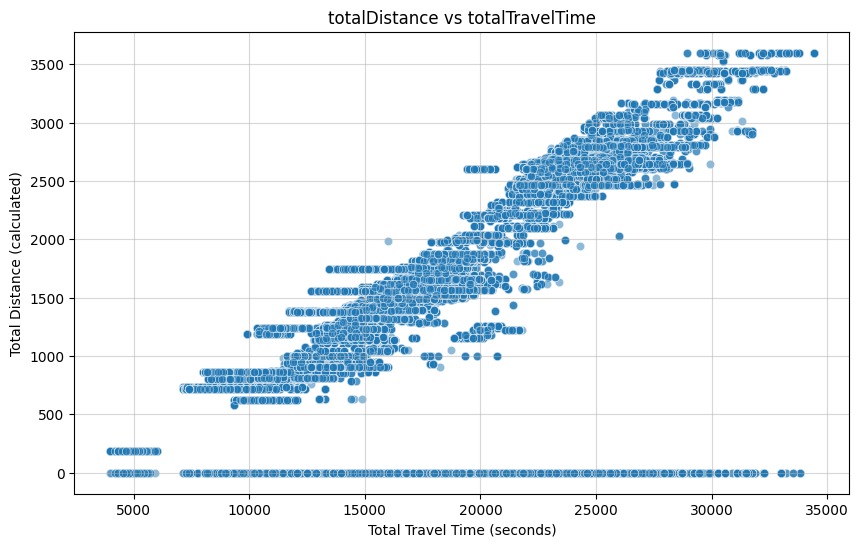

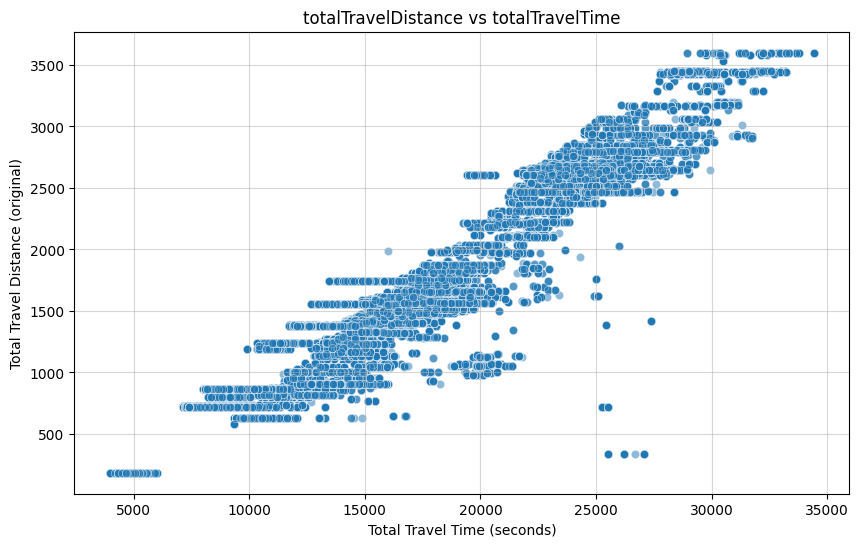

In [ ]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Take a sample of the DataFrame and convert to Pandas for plotting
    # Adjust the sample fraction as needed based on data size and memory constraints
    sample_fraction = 0.1
    df_sample_pd = df_top5_mod.sample(fraction=sample_fraction, seed=42).toPandas()
    
    # Plot 1: totalDistance vs totalTravelTime
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='totalTravelTime', y='totalDistance', data=df_sample_pd, alpha=0.5)
    plt.title('totalDistance vs totalTravelTime')
    plt.xlabel('Total Travel Time (seconds)')
    plt.ylabel('Total Distance (calculated)')
    plt.grid(True, alpha=0.5)
    plt.show()
    
    # Plot 2: totalTravelDistance vs totalTravelTime
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='totalTravelTime', y='totalTravelDistance', data=df_sample_pd, alpha=0.5)
    plt.title('totalTravelDistance vs totalTravelTime')
    plt.xlabel('Total Travel Time (seconds)')
    plt.ylabel('Total Travel Distance (original)')
    plt.grid(True, alpha=0.5)
    plt.show()
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


### Underlining the importance of optimal buy time prediction

As we can see on the following plot, the minimum price occurs various days before the flight itself, so the common strategy to buy as early as possible is not always the best choice. This, and the complex structure of airfare pricing underlines the choice to mathematically model the optimal buy time of a given itinerary.

Number of unique itineraries with a minimum price found: 1137380


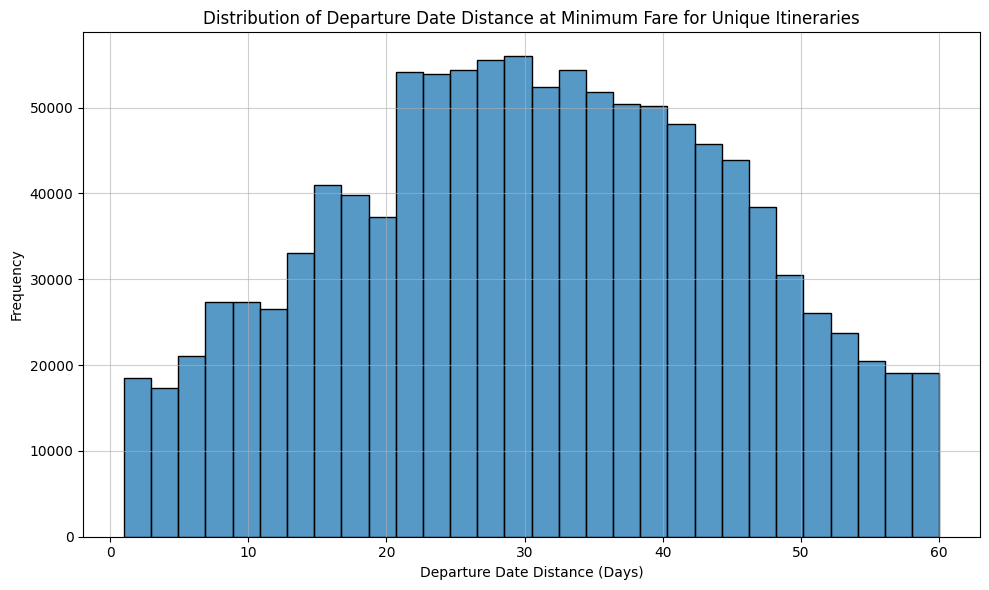

In [ ]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Define a window partitioned by legId and flightDate, ordered by totalFare ascending
    window_spec = Window.partitionBy("legId", "flightDate").orderBy(F.col("totalFare").asc())
    
    # Add a rank column to identify the row with the minimum totalFare for each itinerary
    # If multiple rows have the same minimum fare, they will all get rank 1.
    df_ranked_by_min_fare = df_top5_mod.withColumn("rank_min_fare", F.rank().over(window_spec))
    df_min_price_itinerary = df_ranked_by_min_fare.filter(F.col("rank_min_fare") == 1)
    
    # Select the departureDateDistance from these filtered rows and convert to Pandas for plotting
    departure_distances_at_min_price = df_min_price_itinerary.select("departureDateDistance").toPandas()['departureDateDistance']
    
    print(f"Number of unique itineraries with a minimum price found: {len(departure_distances_at_min_price)}")
    
    # Plot the histogram
    plt.figure(figsize=(10, 6))
    sns.histplot(departure_distances_at_min_price, bins=30, kde=False)
    plt.title('Distribution of Departure Date Distance at Minimum Fare for Unique Itineraries')
    plt.xlabel('Departure Date Distance (Days)')
    plt.ylabel('Frequency')
    plt.grid(True, alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


Additionally, by plotting average price trajectories for different airlines, we can see that the prices are generally higher the closer we are to the flight date, but drops occur for specific itineraries at different times.

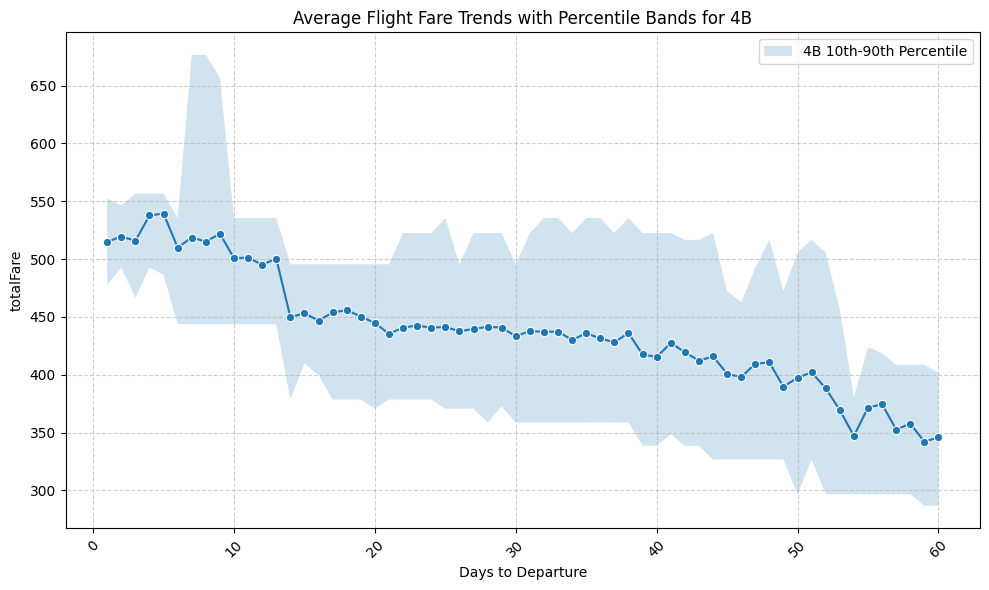

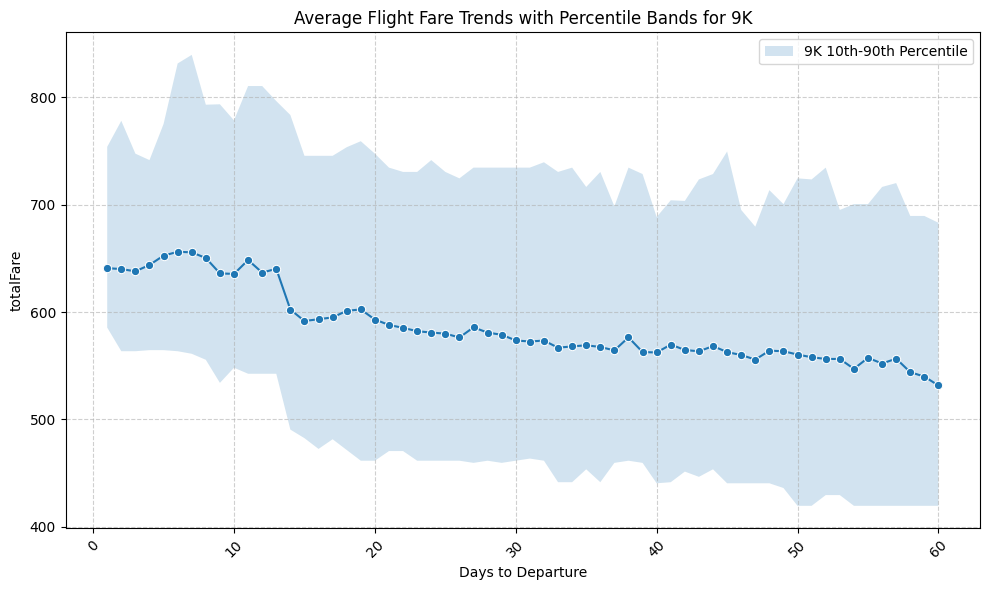

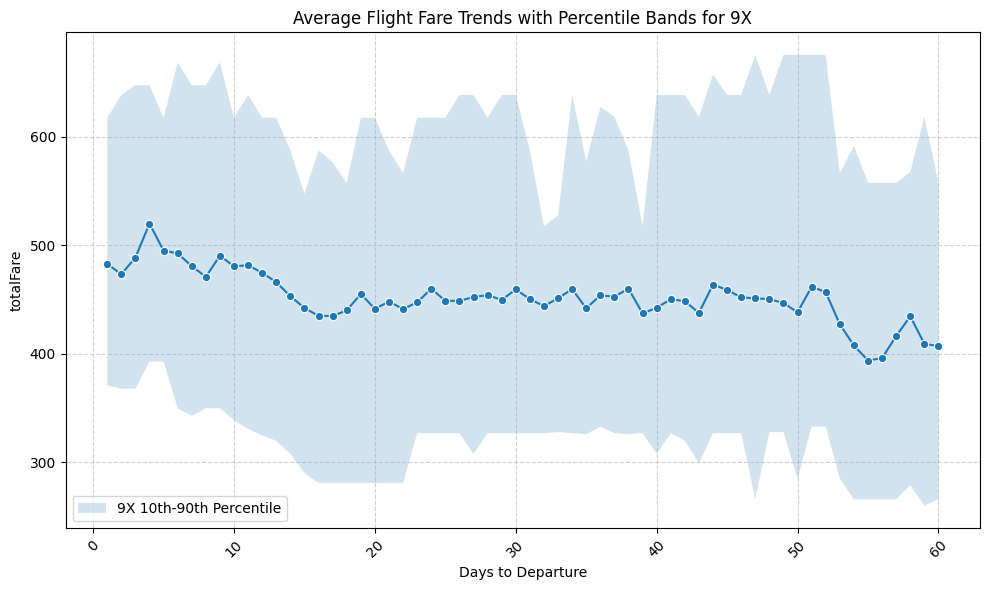

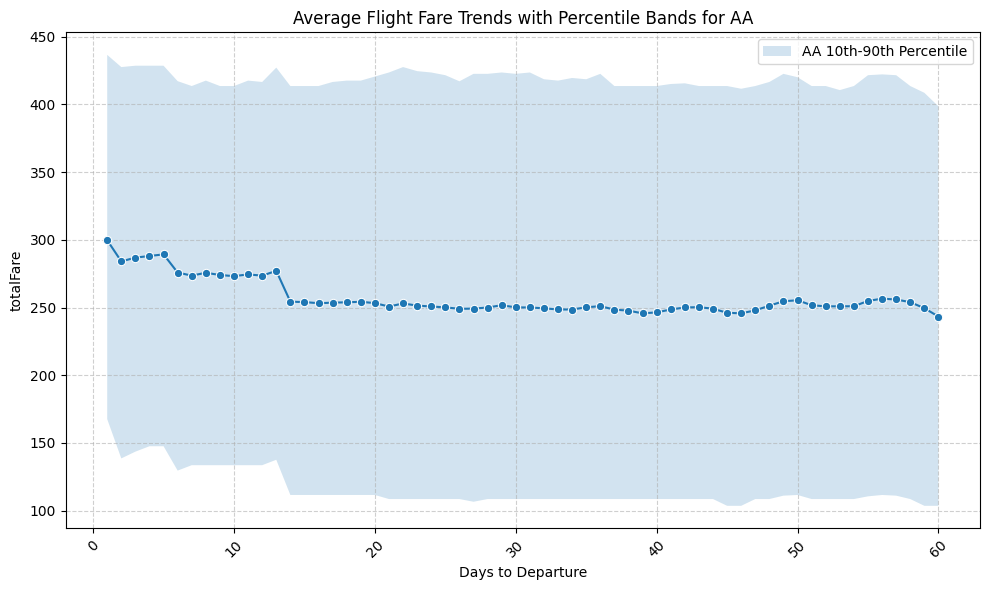

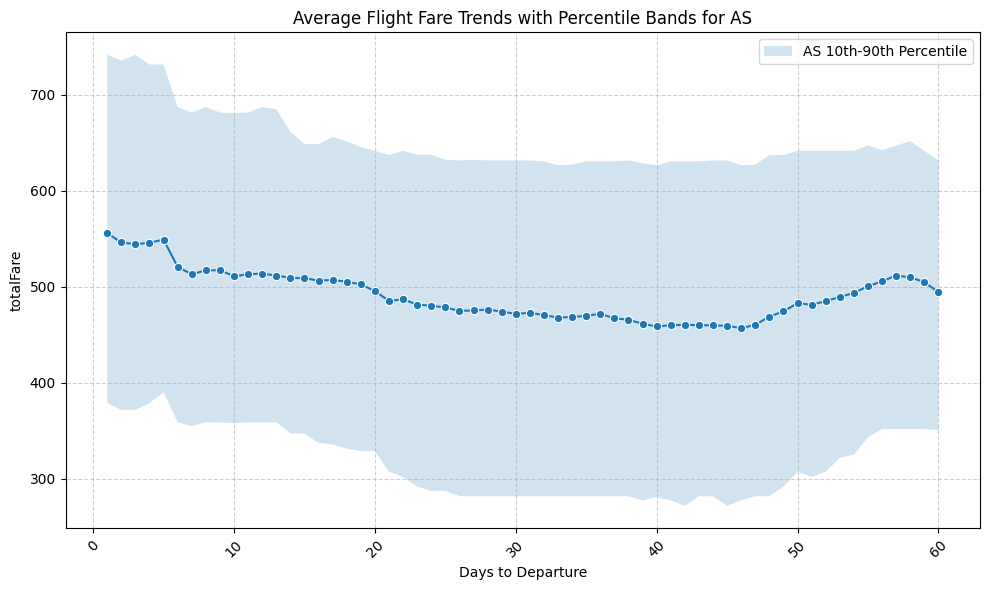

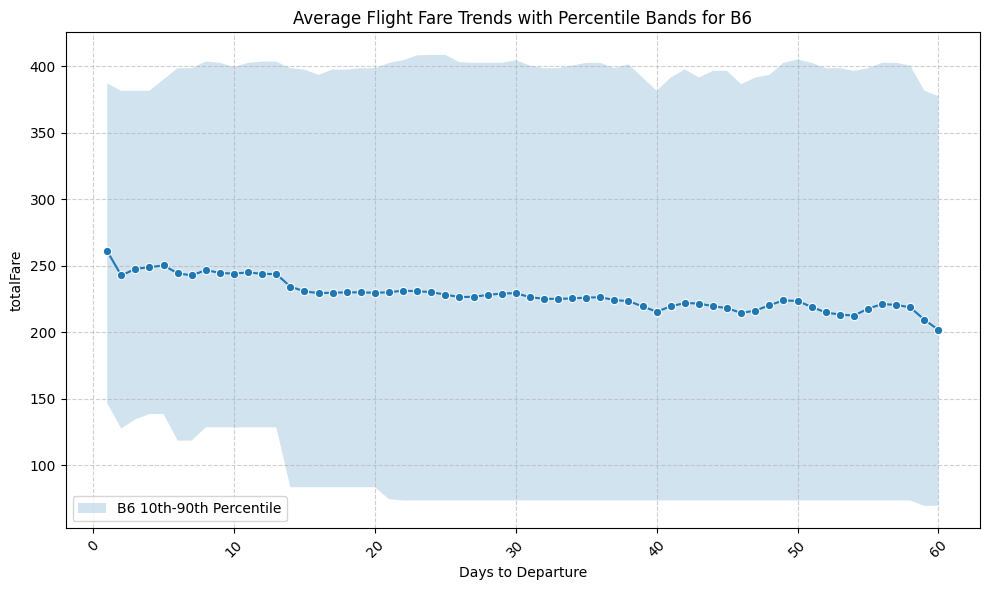

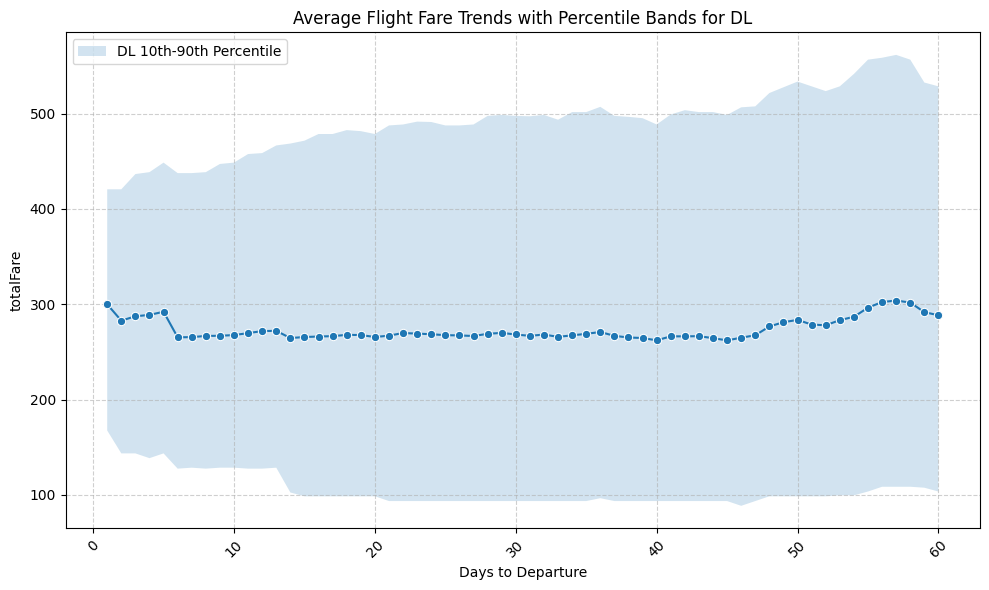

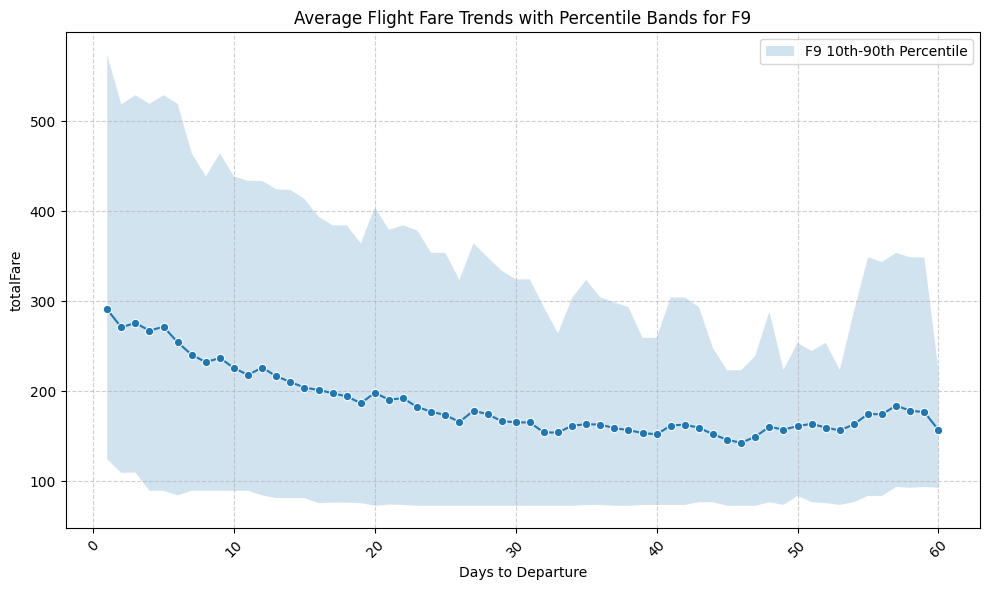

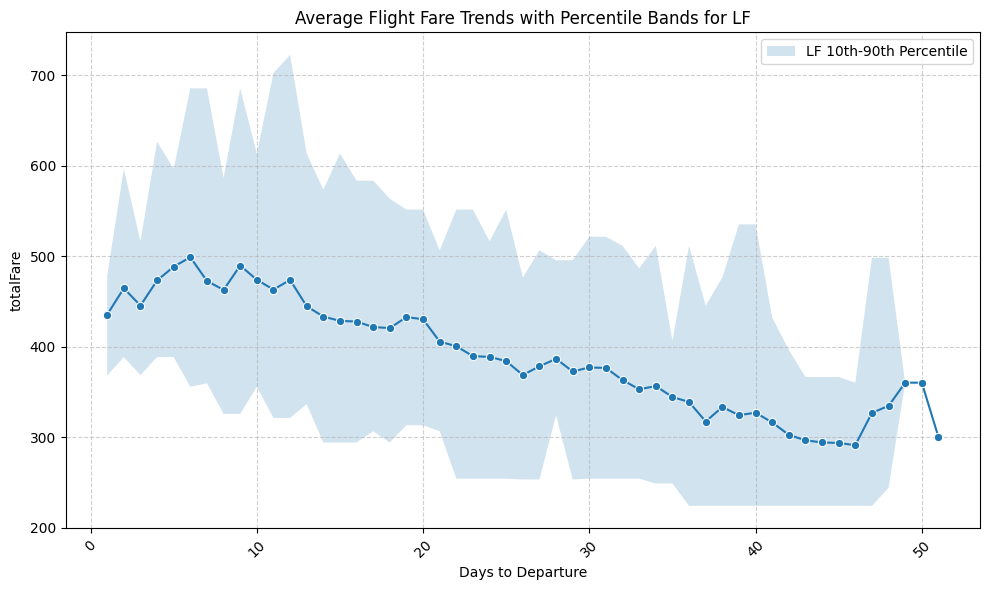

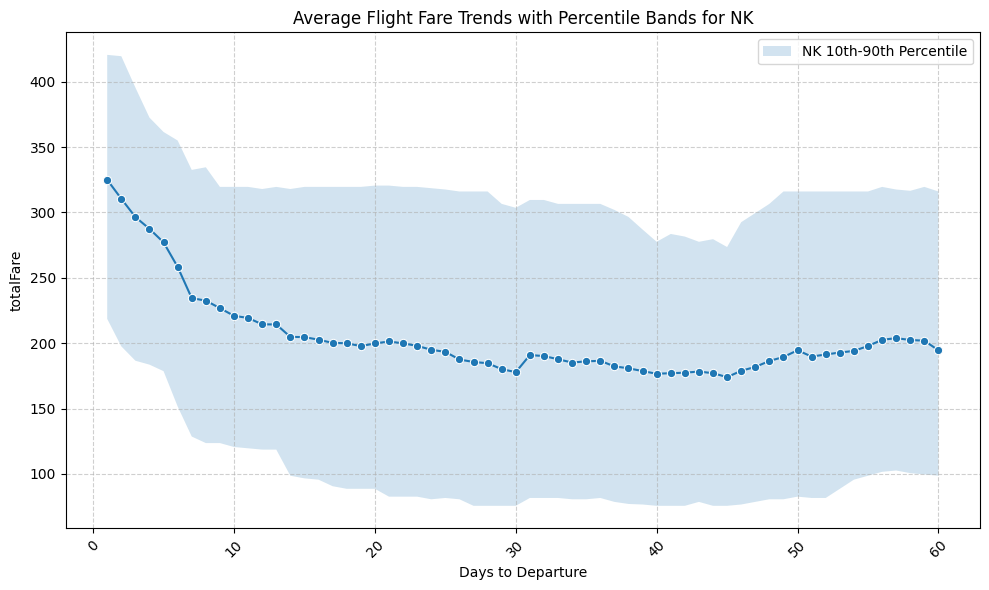

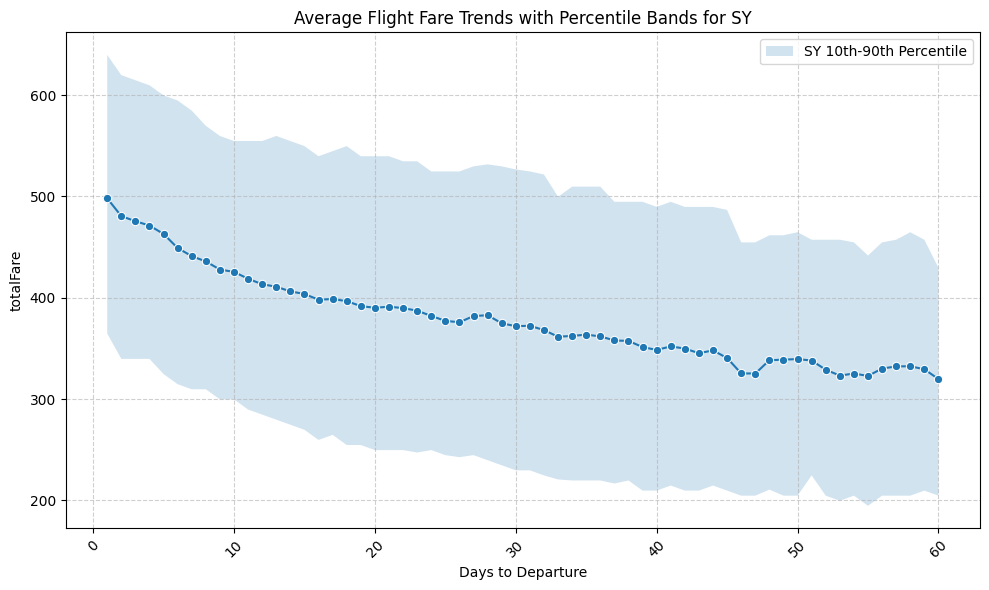

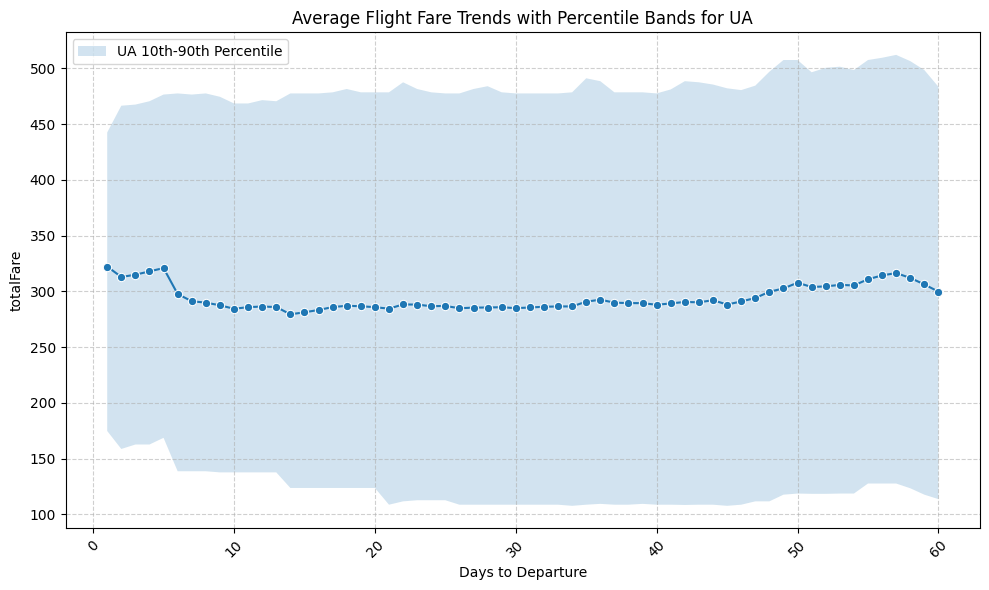

In [ ]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    from pyspark.sql.functions import col, sum as spark_sum, lit, array, struct, explode
    from functools import reduce
    from operator import add
    
    # Dynamically extract unique_airlines from the schema of df_top5_mod
    unique_airlines = [col_name.replace('airline_', '').replace('_count', '') for col_name in df_top5_mod.columns if col_name.startswith('airline_') and col_name.endswith('_count')]
    
    # Create an array of structs, where each struct contains (airline_code, is_present)
    alt_airline_structs = []
    for airline_code in unique_airlines:
        alt_airline_structs.append(struct(lit(airline_code).alias("airline_name"), (col(f"airline_{airline_code}_count") > 0).alias("is_present")))
    
    # Explode the airline_info to create a new row for each airline a flight involves
    df_exploded_airlines = df_top5_mod.withColumn("airline_info", array(*alt_airline_structs)) \
        .withColumn("exploded_airline", explode(col("airline_info"))) \
        .filter(col("exploded_airline.is_present") == True) \
        .withColumn("representedAirlineCode", col("exploded_airline.airline_name")) \
        .drop("airline_info", "exploded_airline")
    
    # Define the window specification for calculating percentiles per airline and departureDateDistance
    # Now using the newly created 'representedAirlineCode'
    window_spec_airline_distance = Window.partitionBy("representedAirlineCode", "departureDateDistance").orderBy("departureDateDistance")
    
    # Calculate average, 10th percentile, and 90th percentile of original fare
    df_airline_stats = df_exploded_airlines.withColumn("originalFare", col("totalFare"))
    df_airline_stats = df_airline_stats.groupBy("representedAirlineCode", "departureDateDistance").agg(
        avg("originalFare").alias("average_fare"),
        percentile_approx("originalFare", 0.1, lit(100)).alias("percentile_10"),
        percentile_approx("originalFare", 0.9, lit(100)).alias("percentile_90")
    ).orderBy("representedAirlineCode", "departureDateDistance")
    
    # Collect and convert to Pandas for plotting
    print("Collecting airline fare statistics for plotting...")
    df_airline_stats_pd = df_airline_stats.toPandas()
    
    # Plotting separate plots for each airline
    for airline_code in df_airline_stats_pd['representedAirlineCode'].unique():
        subset = df_airline_stats_pd[df_airline_stats_pd['representedAirlineCode'] == airline_code]
    
        plt.figure(figsize=(10, 6))
        sns.lineplot(
            data=subset,
            x="departureDateDistance",
            y="average_fare",
            marker='o',
            errorbar=None
        )
    
        # Add percentile bands for the current airline
        plt.fill_between(
            subset['departureDateDistance'],
            subset['percentile_10'],
            subset['percentile_90'],
            alpha=0.2,
            label=f'{airline_code} 10th-90th Percentile'
        )
    
        plt.title(f'Average Flight Fare Trends with Percentile Bands for {airline_code}')
        plt.xlabel('Days to Departure')
        plt.ylabel('totalFare')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


The lowest price is observed in less than 4% of itineraries at the first observation day, which further supports the modeling approach to find the day with the lowest price.

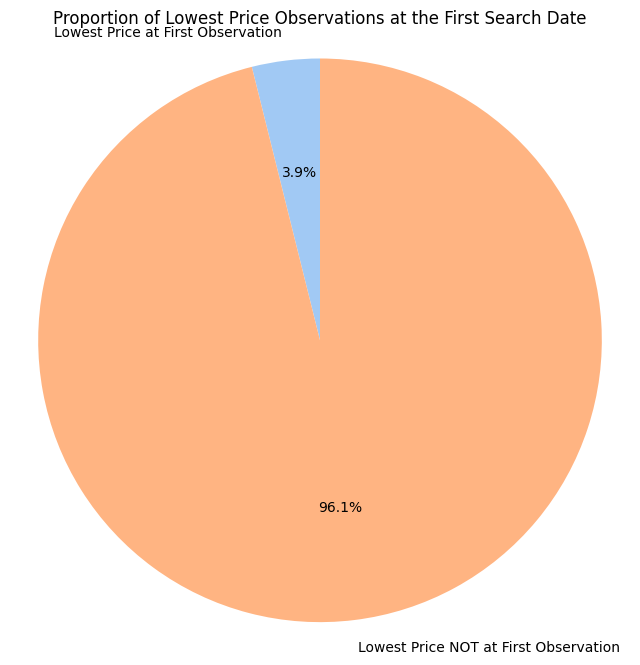

Counts for lowest price observation:
              minPriceAtFirstObservation    count
0      Lowest Price at First Observation    44248
1  Lowest Price NOT at First Observation  1093132


In [ ]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Find the earliest searchDate for each (legId, flightDate) pair from the full dataset (df_top5_mod)
    # df_top5_mod contains all search dates for each itinerary.
    window_spec_earliest_search = Window.partitionBy("legId", "flightDate")
    
    df_earliest_search_date = df_top5_mod.groupBy("legId", "flightDate").agg(
        min("searchDate").alias("earliestSearchDate")
    )
    
    # Join df_min_price_itinerary with df_earliest_search_date
    # to compare the searchDate at minimum fare with the earliest possible searchDate.
    df_comparison = df_min_price_itinerary.join(
        df_earliest_search_date,
        on=["legId", "flightDate"],
        how="inner"
    )
    
    # Create a column indicating if the lowest price was found on the first observation
    df_comparison = df_comparison.withColumn(
        "minPriceAtFirstObservation",
        (col("searchDate") == col("earliestSearchDate"))
    )
    
    # Count how many times the lowest price was observed at the first search date vs. not
    min_price_observation_counts = df_comparison.groupBy("minPriceAtFirstObservation").count().toPandas()
    min_price_observation_counts['minPriceAtFirstObservation'] = min_price_observation_counts['minPriceAtFirstObservation'].map({
        True: 'Lowest Price at First Observation',
        False: 'Lowest Price NOT at First Observation'
    })
    
    # Plot as a pie chart
    plt.figure(figsize=(8, 8))
    plt.pie(
        min_price_observation_counts['count'],
        labels=min_price_observation_counts['minPriceAtFirstObservation'],
        autopct='%1.1f%%',
        startangle=90,
        colors=sns.color_palette('pastel')[0:2]
    )
    plt.title('Proportion of Lowest Price Observations at the First Search Date')
    plt.axis('equal')
    plt.show()
    
    print("Counts for lowest price observation:")
    print(min_price_observation_counts)
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


### Feature engineering

Alongside calendar and itinerary attributes, historical log fares are represented as first differences. For example, `lagged_fare_diff_1 = logFare_(t-1) - logFare_(t-2)`. The levels are retained only to construct these differences and are not passed to the forecasting models. Historical rolling statistics are computed from prior observations only.

In [9]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # --- Generate isWeekend, dayOfWeek, weekOfFlight ---
    # dayofweek: 1 = Sunday, 2 = Monday, ..., 7 = Saturday
    df_top5_mod = df_top5_mod.withColumn('isWeekend',
                                         ((dayofweek(col('flightDate')) == 1) | (dayofweek(col('flightDate')) == 7)).cast('integer'))
    
    df_top5_mod = df_top5_mod.withColumn('dayOfWeek', dayofweek(col('flightDate')))
    # There is no dayOfMonth in Pyspark SQL functions, thus generating 'dayOfMonth' by extracting the day from 'flightDate'
    df_top5_mod = df_top5_mod.withColumn('dayOfMonth', dayofmonth(col('flightDate')))
    df_top5_mod = df_top5_mod.withColumn('weekOfFlight', weekofyear(col('flightDate')))
    
    # --- Convert firstDepartureTime and finalArrivalTime to Sine/Cosine components ---
    # First, cast string timestamp columns to proper timestamp type
    df_top5_mod = df_top5_mod.withColumn('firstDepartureTime_ts', to_timestamp(col('firstDepartureTime')))
    df_top5_mod = df_top5_mod.withColumn('finalArrivalTime_ts', to_timestamp(col('finalArrivalTime')))
    
    # Calculate total minutes from midnight for departure and arrival times
    df_top5_mod = df_top5_mod.withColumn('dep_total_minutes', hour(col('firstDepartureTime_ts')) * 60 + minute(col('firstDepartureTime_ts')))
    df_top5_mod = df_top5_mod.withColumn('arr_total_minutes', hour(col('finalArrivalTime_ts')) * 60 + minute(col('finalArrivalTime_ts')))
    
    # Convert minutes to radians for a 24-hour cycle (1440 minutes in a day)
    # angle = (time_in_minutes / 1440) * 2 * pi
    df_top5_mod = df_top5_mod.withColumn('depSin', sin((col('dep_total_minutes') / 1440.0) * 2 * pi()))
    df_top5_mod = df_top5_mod.withColumn('depCos', cos((col('dep_total_minutes') / 1440.0) * 2 * pi()))
    df_top5_mod = df_top5_mod.withColumn('arrSin', sin((col('arr_total_minutes') / 1440.0) * 2 * pi()))
    df_top5_mod = df_top5_mod.withColumn('arrCos', cos((col('arr_total_minutes') / 1440.0) * 2 * pi()))
    
    # Drop intermediate timestamp and total_minutes columns if no longer needed
    df_top5_mod = df_top5_mod.drop('firstDepartureTime_ts', 'finalArrivalTime_ts', 'dep_total_minutes', 'arr_total_minutes')
    
    # Lagged log-fare differences are generated after totalFare is log-transformed
    # in the next feature-engineering cell, so every lag uses the same scale.
    
    print("New features generated and added to df_top5_mod:")
    df_top5_mod.select('flightDate', 'isWeekend', 'dayOfWeek', 'weekOfFlight',
                       'firstDepartureTime', 'depSin', 'depCos',
                       'finalArrivalTime', 'arrSin', 'arrCos').show(5, truncate=False)
    
    df_top5_mod.printSchema()
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


New features generated and added to df_top5_mod:
+----------+---------+---------+------------+-------------------+-------------------+-------------------+-------------------+------------------+------------------+
|flightDate|isWeekend|dayOfWeek|weekOfFlight|firstDepartureTime |depSin             |depCos             |finalArrivalTime   |arrSin            |arrCos            |
+----------+---------+---------+------------+-------------------+-------------------+-------------------+-------------------+------------------+------------------+
|2022-06-08|0        |4        |23          |2022-06-08 14:11:00|-0.5409744713679938|-0.8410390129643925|2022-06-08 20:19:00|-0.821646937942164|0.5699967625963025|
|2022-06-08|0        |4        |23          |2022-06-08 14:11:00|-0.5409744713679938|-0.8410390129643925|2022-06-08 20:19:00|-0.821646937942164|0.5699967625963025|
|2022-06-08|0        |4        |23          |2022-06-08 14:11:00|-0.5409744713679938|-0.8410390129643925|2022-06-08 20:19:00|-0.821

Plotting the variables:


*   A stratified sample of the original dataset is used, as the size does not allow the use of plotting via pandas&matplotlib
*   According variables are plotted on histograms and pie charts


Generating plots for the entire dataset with 1.0% stratified sampling...


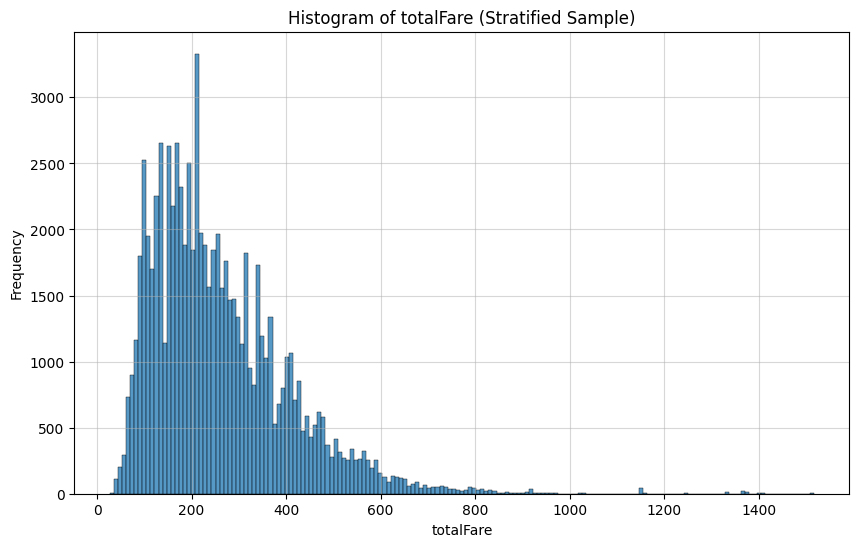

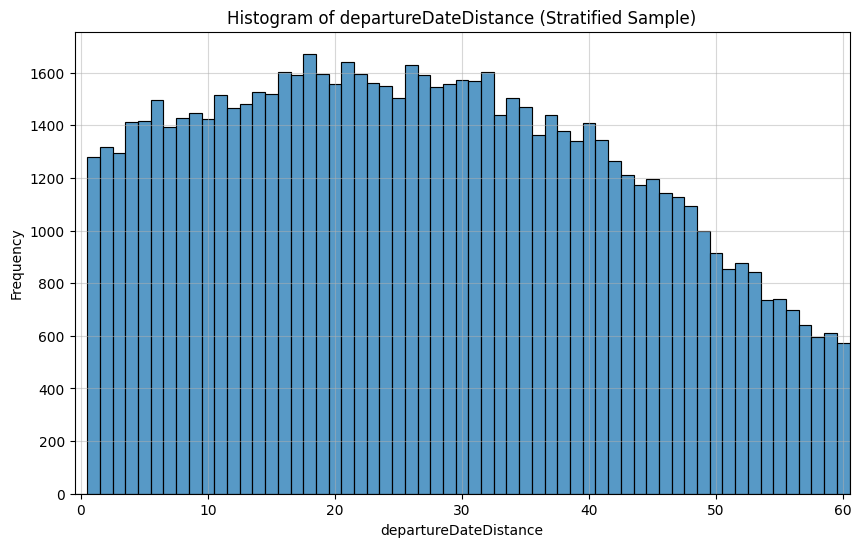

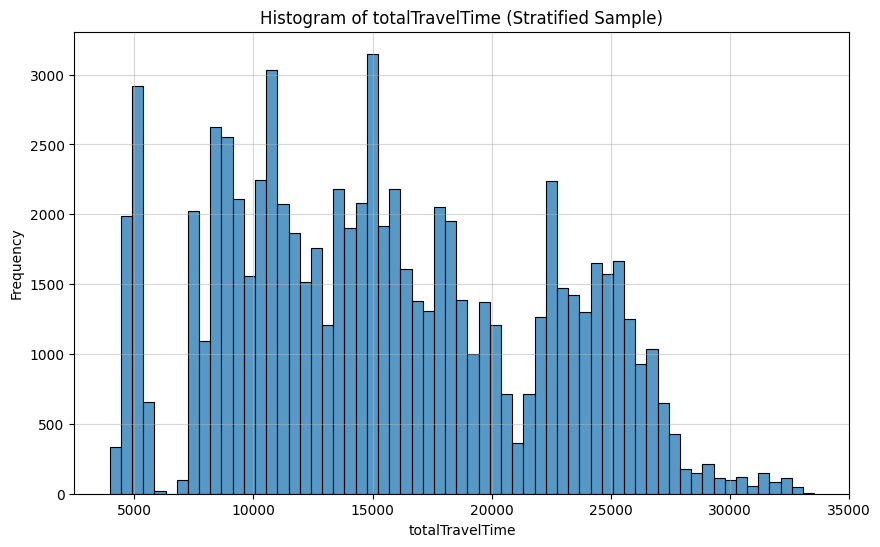

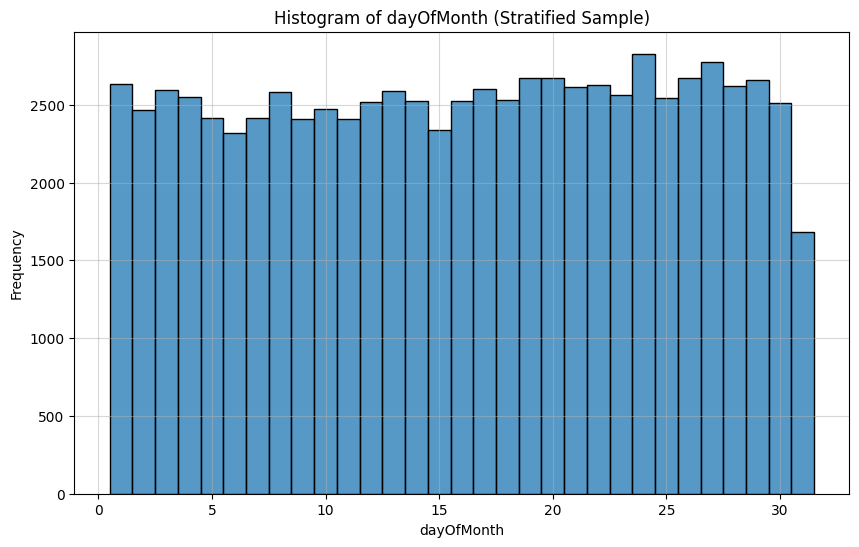

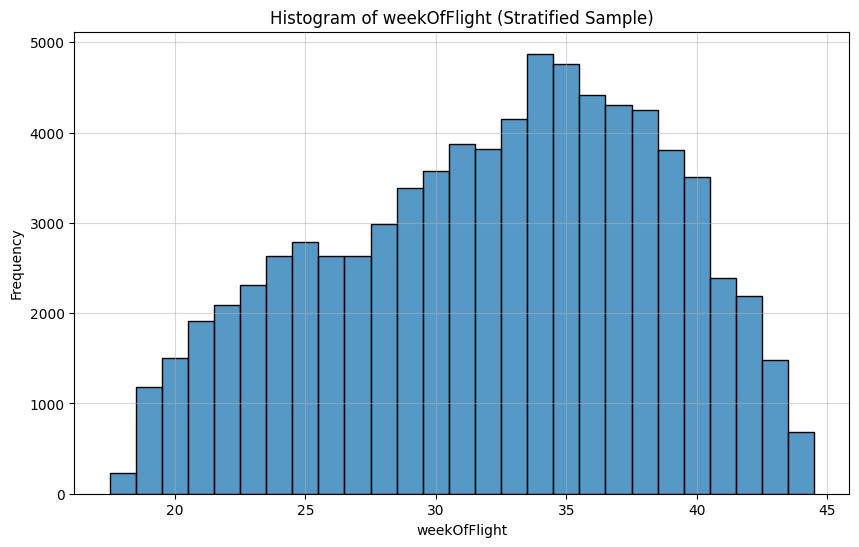

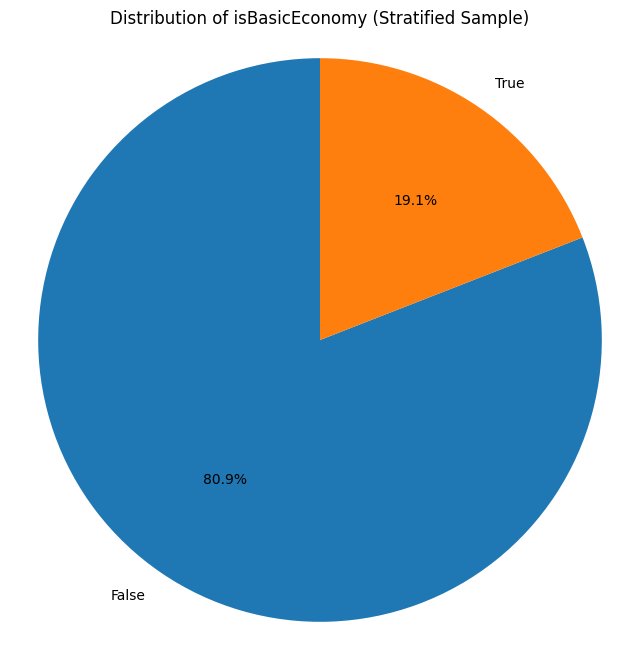

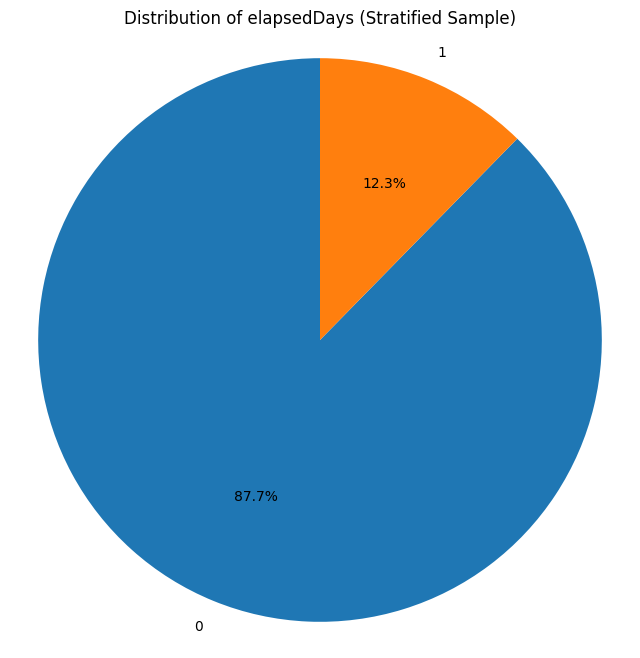

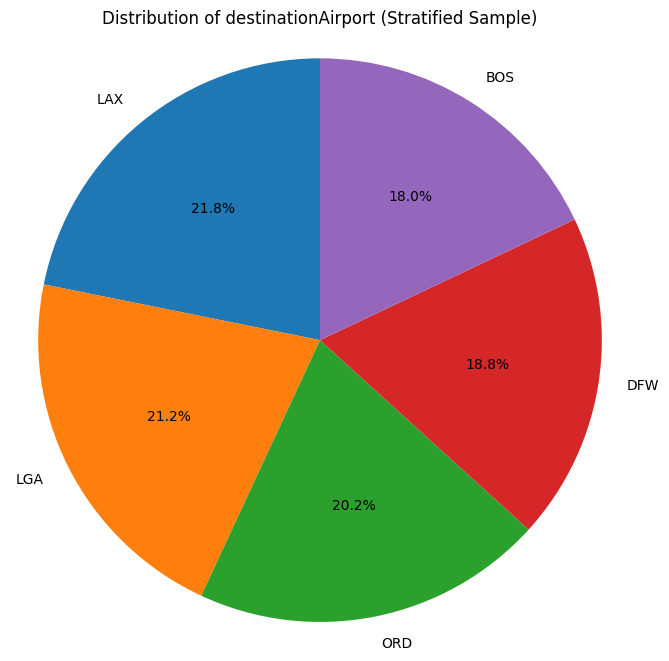

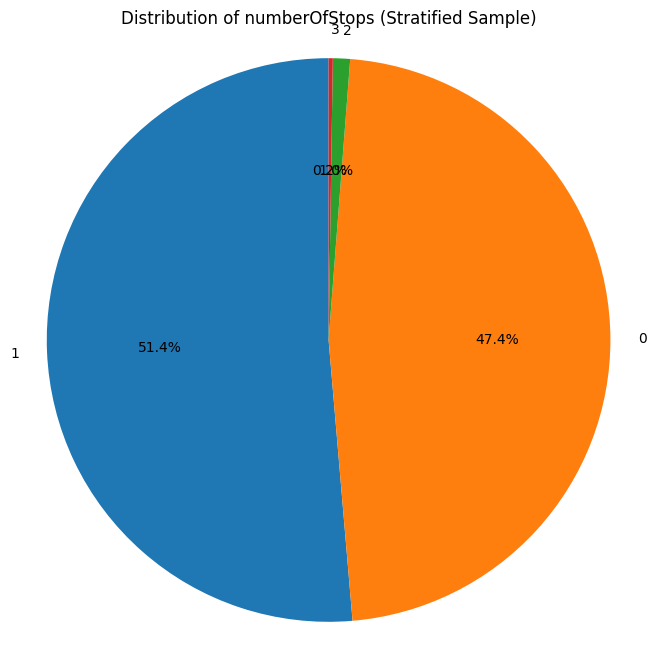

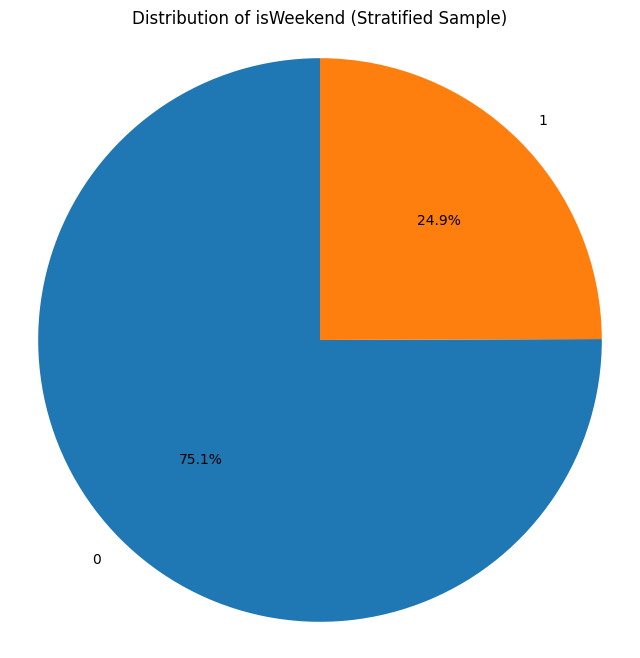

In [ ]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Define the columns for histograms and pie charts
    histogram_cols = ['totalFare', 'departureDateDistance', 'totalTravelTime', 'dayOfMonth', 'weekOfFlight']
    pie_chart_cols = ['isBasicEconomy', 'elapsedDays', 'destinationAirport', 'numberOfStops', 'isWeekend']
    
    # Function to perform stratified sampling based on a given column
    def get_stratified_sample_for_plot(df, column_name, sample_fraction, num_bins=10, seed=42):
        total_rows = df.count()
        if total_rows == 0:
            return df.limit(0).toPandas()
    
        # Determine column type and if it should be treated as categorical for stratification
        col_field = df.schema[column_name]
        col_type = col_field.dataType
        treat_as_categorical = False
    
        if isinstance(col_type, (StringType, BooleanType)):
            treat_as_categorical = True
        elif isinstance(col_type, IntegerType):
            # For IntegerType, check distinct count to decide between categorical and binning
            distinct_vals = df.select(column_name).distinct().collect()
            if len(distinct_vals) < num_bins * 2: # Heuristic: if few distinct values, treat as categorical
                treat_as_categorical = True
    
        if treat_as_categorical:
            # Stratify by distinct values of the column
            strata_df = df.groupBy(column_name).count()
            strata_dict = {row[column_name]: sample_fraction for row in strata_df.collect() if row['count'] > 0}
            if strata_dict:
                sampled_df = df.stat.sampleBy(column_name, strata_dict, seed=seed)
            else:
                # Fallback to simple random sample if no valid strata (e.g., all nulls)
                sampled_df = df.sample(False, sample_fraction, seed=seed)
        else:
            # For numerical columns (FloatType, DoubleType, or IntegerType with many distinct values), create bins
            df_non_null = df.filter(col(column_name).isNotNull())
            if df_non_null.count() == 0:
                 return df.limit(0).toPandas()
    
            # Use NTILE to create approximately equal-sized bins
            df_binned = df_non_null.withColumn(f"{column_name}_bin", ntile(num_bins).over(Window.orderBy(col(column_name))))
    
            # Stratified sample by these bins
            strata_df = df_binned.groupBy(f"{column_name}_bin").count()
            strata_dict = {row[f"{column_name}_bin"]: sample_fraction for row in strata_df.collect() if row['count'] > 0}
    
            if strata_dict:
                sampled_df = df_binned.stat.sampleBy(f"{column_name}_bin", strata_dict, seed=seed)
            else: # Fallback if binning failed or no strata
                sampled_df = df_binned.sample(False, sample_fraction, seed=seed)
            sampled_df = sampled_df.drop(f"{column_name}_bin")
    
        return sampled_df.toPandas()
    
    overall_sample_fraction = 0.01 # Reduced sampling fraction for plotting to avoid OutOfMemoryError
    print(f"Generating plots for the entire dataset with {overall_sample_fraction*100:.1f}% stratified sampling...")
    # Generate Histograms
    for col_name in histogram_cols:
        try:
            # Get a stratified sample based on the current histogram column from the entire df_top5_mod
            df_sampled_for_plot_pd = get_stratified_sample_for_plot(df_top5_mod, col_name, overall_sample_fraction)
    
            if df_sampled_for_plot_pd.empty:
                print(f"Sample for histogram {col_name} is empty, skipping plot.")
                continue
    
            plt.figure(figsize=(10, 6))
    
            # Adjust plotting based on column type
            if col_name in ['departureDateDistance', 'dayOfMonth', 'weekOfFlight']:
                # These are discrete integer values, use discrete=True and adjust bins
                if col_name == 'departureDateDistance':
                    # Limit x-axis to remove potential outliers if they exist, considering previous filtering
                    sns.histplot(df_sampled_for_plot_pd[col_name].dropna(), discrete=True, binwidth=1, binrange=(0, 60), kde=False)
                    plt.xlim(-0.5, 60.5) # Set xlim to align with bin edges for discrete values from 0 to 60
                else:
                    sns.histplot(df_sampled_for_plot_pd[col_name].dropna(), discrete=True, binwidth=1, kde=False)
            else:
                # Continuous variables, let seaborn choose appropriate bins
                sns.histplot(df_sampled_for_plot_pd[col_name].dropna(), bins='auto', kde=False)
    
            plt.title(f'Histogram of {col_name} (Stratified Sample)')
            plt.xlabel(col_name)
            plt.ylabel('Frequency')
            plt.grid(True, alpha=0.5)
            plt.show()
        except Exception as e:
            print(f"Could not generate histogram for {col_name}. Error: {e}")
    
    # Generate Pie Charts
    for col_name in pie_chart_cols:
        try:
            # Get a stratified sample based on the current pie chart column from the entire df_top5_mod
            df_sampled_for_plot_pd = get_stratified_sample_for_plot(df_top5_mod, col_name, overall_sample_fraction)
    
            if df_sampled_for_plot_pd.empty:
                print(f"Sample for pie chart {col_name} is empty, skipping plot.")
                continue
    
            plt.figure(figsize=(8, 8))
            value_counts = df_sampled_for_plot_pd[col_name].value_counts().dropna()
            if not value_counts.empty:
                plt.pie(value_counts, labels=value_counts.index, autopct='%1.1f%%', startangle=90)
                plt.title(f'Distribution of {col_name} (Stratified Sample)') # Removed airport specific title
                plt.axis('equal')
                plt.show()
            else:
                print(f"Skipping pie chart for {col_name} as its sample contains no non-null values.")
        except Exception as e:
            print(f"Could not generate pie chart for {col_name}. Error: {e}")
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


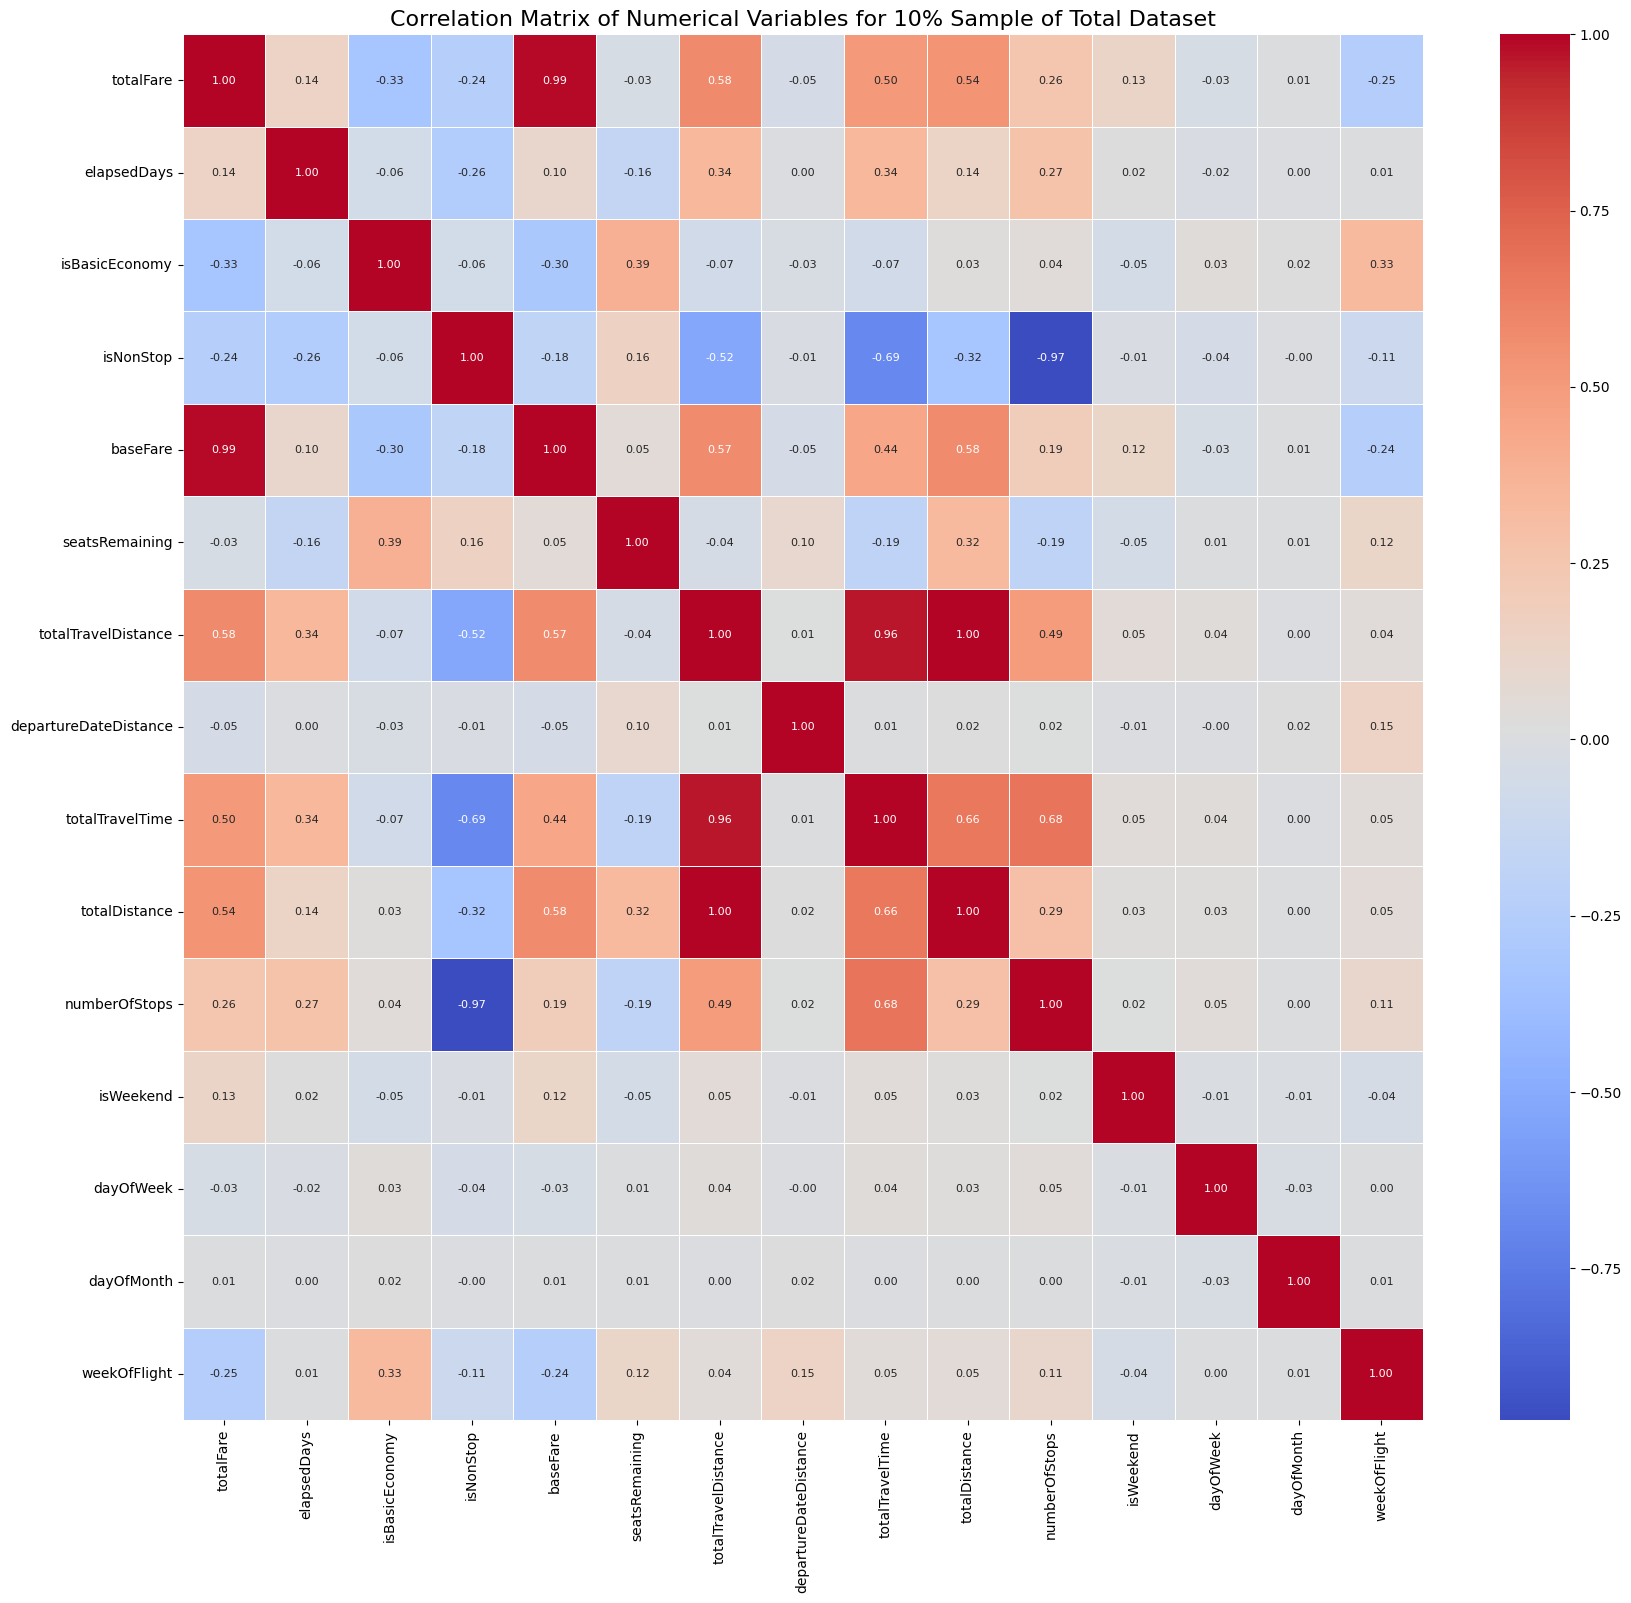

In [ ]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    sample_fraction = 0.1
    df_sample = df_top5_mod.sample(False, sample_fraction, seed=42)
    
    if df_sample.count() > 0:
        df_sample_pd = df_sample.toPandas()
    else:
        print(f"No data in the sampled DataFrame, skipping correlation map.")
    
    if not df_sample_pd.empty:
        # Identify numerical columns in the sampled Pandas DataFrame
        numerical_cols_for_corr = []
    
        # Add totalFare first if it's a numeric column
        if 'totalFare' in df_sample_pd.columns and pd.api.types.is_numeric_dtype(df_sample_pd['totalFare']):
            numerical_cols_for_corr.append('totalFare')
    
        exclusion_list = ['legId', 'flightDate', 'searchDate', 'firstDepartureTime', 'finalArrivalTime', 'isRefundable', 'depSin', 'depCos', 'arrSin', 'arrCos', 'totalFare'] # Add totalFare to exclude from general loop
    
        for col_name, dtype in df_sample_pd.dtypes.items():
            # Include all numeric dtypes (int, float, double)
            if pd.api.types.is_numeric_dtype(dtype):
                if not (col_name.startswith('airline_') and col_name.endswith('_count')) and \
                   col_name not in exclusion_list and \
                   not col_name.startswith('lagged_fare_'):
                    numerical_cols_for_corr.append(col_name)
    
        # Select only the numerical columns for correlation calculation
        df_numerical_for_corr = df_sample_pd[numerical_cols_for_corr]
    
        if df_numerical_for_corr.empty or len(df_numerical_for_corr.columns) < 2:
            print(f"Not enough numerical columns to form a correlation matrix for the sampled dataset.")
        else:
            # Calculate the correlation matrix
            correlation_matrix = df_numerical_for_corr.corr()
    
            # Plot the correlation map
            plt.figure(figsize=(20, 18)) # Adjust size as needed for readability
            sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, annot_kws={"size": 8})
            plt.title(f'Correlation Matrix of Numerical Variables for 10% Sample of Total Dataset', fontsize=16)
            plt.show()
    else:
        print("Sampled Pandas DataFrame is empty, cannot generate correlation map.")
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


These variables either have low information content, or are highly correlated with another variable, thus making them unnecessary for modeling uses.

In [10]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Discard columns as per problem statement and to ensure clean feature set.
    # 'isBasicEconomy' and 'isNonStop' original boolean columns are dropped as their '_int' versions are used.
    columns_to_discard = [
        'isBasicEconomy',
        'isRefundable',
        'isNonStop',
        'baseFare',
        'totalTravelDistance',
        'totalDistance'
    ]
    df_top5_mod = df_top5_mod.drop(*columns_to_discard)
    
    print(f"Schema after dropping {columns_to_discard}:")
    df_top5_mod.printSchema()
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


Schema after dropping ['isBasicEconomy', 'isRefundable', 'isNonStop', 'baseFare', 'totalTravelDistance', 'totalDistance']:
root
 |-- legId: string (nullable = true)
 |-- flightDate: date (nullable = true)
 |-- searchDate: date (nullable = true)
 |-- startingAirport: string (nullable = true)
 |-- destinationAirport: string (nullable = true)
 |-- elapsedDays: integer (nullable = true)
 |-- totalFare: float (nullable = true)
 |-- seatsRemaining: integer (nullable = true)
 |-- departureDateDistance: integer (nullable = true)
 |-- firstDepartureTime: string (nullable = true)
 |-- finalArrivalTime: string (nullable = true)
 |-- totalTravelTime: integer (nullable = true)
 |-- airline_UA_count: integer (nullable = true)
 |-- airline_NK_count: integer (nullable = true)
 |-- airline_AA_count: integer (nullable = true)
 |-- airline_B6_count: integer (nullable = true)
 |-- airline_DL_count: integer (nullable = true)
 |-- airline_9K_count: integer (nullable = true)
 |-- airline_F9_count: integer (n

The time-series variables are built **after** the log transform (next code cell), on the log-fare scale, and are all *stationary* quantities:
*    lagged_fare_diff_k: the k-th lagged first difference of log fare, log P(t-k) - log P(t-k-1)
*    rollingStd3: standard deviation of the previous three one-day changes (volatility)
*    fareChange: today's change in log fare, log P(t) - log P(t-1). **This is the prediction target of every price model.**
*    lagged_fare_1: yesterday's log fare. It is the *anchor* used only to turn a predicted change back into a price level for evaluation. It is never a model input.


As it could be seen on the histogram, the distribution of totalFare presents significant skew, so logarithmization is applied.

In [11]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Log-transform the fare, then build every time-series quantity on the log scale.
    df_top5_mod = df_top5_mod.withColumn('totalFare', log(col('totalFare')))
    df_top5_mod = df_top5_mod.drop('baseFare')
    
    N_DIFF_LAGS = 20   # each lagged difference d_k needs k+1 earlier observations; rows without them are dropped by the assembler
    
    price_window = Window.partitionBy('legId', 'flightDate').orderBy('searchDate')
    
    # Lagged log-fare LEVELS. lagged_fare_1 is the anchor; ALL levels are excluded from model inputs.
    for lag_number in range(1, N_DIFF_LAGS + 2):
        df_top5_mod = df_top5_mod.withColumn(
            f'lagged_fare_{lag_number}', lag(col('totalFare'), lag_number).over(price_window)
        )
    
    # Lagged first differences d_k = logP(t-k) - logP(t-k-1): the stationary model inputs.
    for lag_number in range(1, N_DIFF_LAGS + 1):
        df_top5_mod = df_top5_mod.withColumn(
            f'lagged_fare_diff_{lag_number}',
            col(f'lagged_fare_{lag_number}') - col(f'lagged_fare_{lag_number + 1}')
        )
    
    # TARGET of all price models: today's change in log fare.
    df_top5_mod = df_top5_mod.withColumn('fareChange', col('totalFare') - col('lagged_fare_1'))
    
    # Volatility = std of the PREVIOUS three changes (rows -3..-1 never include the current row).
    df_top5_mod = df_top5_mod.withColumn(
        'rollingStd3', stddev(col('fareChange')).over(price_window.rowsBetween(-3, -1))
    )
    
    print(f'Created lagged_fare_1..{N_DIFF_LAGS + 1} (levels, anchor only), lagged_fare_diff_1..{N_DIFF_LAGS}, fareChange (target), rollingStd3')
    df_top5_mod.select(
        'legId', 'flightDate', 'searchDate', 'totalFare', 'lagged_fare_1', 'fareChange',
        'lagged_fare_diff_1', 'rollingStd3'
    ).show(5, truncate=False)
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


Created lagged_fare_1..21 (levels, anchor only), lagged_fare_diff_1..20, fareChange (target), rollingStd3
+--------------------------------+----------+----------+-----------------+-----------------+----------+------------------+-----------+
|legId                           |flightDate|searchDate|totalFare        |lagged_fare_1    |fareChange|lagged_fare_diff_1|rollingStd3|
+--------------------------------+----------+----------+-----------------+-----------------+----------+------------------+-----------+
|00000115f8d6a14453bcd1bbc90fbd0b|2022-06-08|2022-04-17|5.836563603705302|NULL             |NULL      |NULL              |NULL       |
|00000115f8d6a14453bcd1bbc90fbd0b|2022-06-08|2022-04-18|5.836563603705302|5.836563603705302|0.0       |NULL              |NULL       |
|00000115f8d6a14453bcd1bbc90fbd0b|2022-06-08|2022-04-19|5.836563603705302|5.836563603705302|0.0       |0.0               |NULL       |
|00000115f8d6a14453bcd1bbc90fbd0b|2022-06-08|2022-04-21|5.836563603705302|5.83656360

### Stationarity check for log fares and their first differences

Two complementary tests are run on a **random** sample of itineraries (not the longest ones, which would bias the result) with at least 20 observations:
* **ADF** - null hypothesis: unit root (non-stationary). A small p-value supports stationarity.
* **KPSS** - null hypothesis: stationary. A *large* p-value supports stationarity.

A series is called stationary only if both tests agree. The per-series p-values are also combined into one **panel** test (Maddala-Wu Fisher test, null: every series has a unit root). The mean lag-1 autocorrelation of the differences is reported as an **over-differencing check** (values close to -0.5 or below would mean the series was differenced too much). Constant series (price never moves) are counted and skipped, because the tests are undefined for them.

Caveats: with 20-60 observations per series both tests have limited power, and the Fisher test assumes independent series although itineraries on the same route share shocks, so its p-value is optimistic. Finally, a pooled weekly view of `fareChange` over calendar time checks that the mean and variance of the changes do not drift.


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/stattools/_stattools.py:432: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(xdshort, add_trend(xdall[:, : usedlag + 1], regression)).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/stattools/_stattools.py:432: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(xdshort, add_trend(xdall[:, : usedlag + 1], regression)).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/stattools/_stattools.py:432: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(xdshort, add_trend(xdall[:, : usedlag + 1], regression)).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/stattools/_stattools.py:432: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquel

Sampled itineraries with >= 20 observations: 2000; constant (skipped): 21; tested: 1974
                   ADF rejects unit root  KPSS keeps stationarity  both agree: stationary  median ADF p  median KPSS p  mean lag-1 autocorr
log fare (levels)                  0.077                    0.485                   0.065         0.594          0.047                0.640
first difference                   0.653                    0.903                   0.595         0.014          0.100               -0.187
Panel (Maddala-Wu) ADF test, log fare (levels): statistic=nan, p-value=nan
Panel (Maddala-Wu) ADF test, first difference: statistic=nan, p-value=nan
Weekly mean of fareChange: min=-0.0038, max=0.0242
Weekly std of fareChange:  min=0.1121, max=0.1744


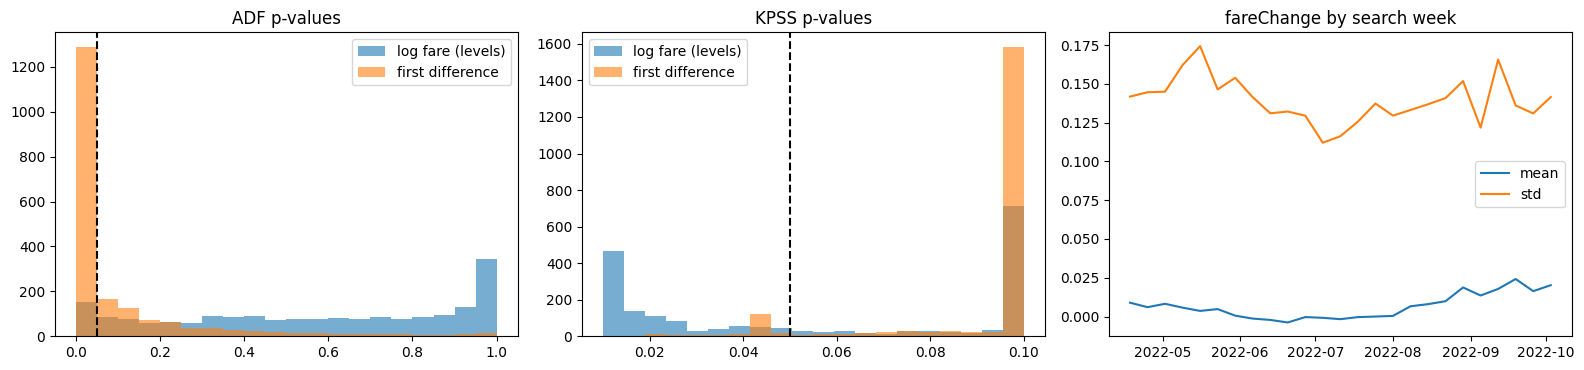

In [ ]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    import warnings
    from scipy import stats
    from statsmodels.tsa.stattools import adfuller, kpss
    
    warnings.filterwarnings('ignore', category=FutureWarning)
    try:
        from statsmodels.tools.sm_exceptions import InterpolationWarning
        warnings.filterwarnings('ignore', category=InterpolationWarning)
    except ImportError:
        pass
    
    MIN_OBS = 20
    N_SERIES = 2000      # cap on the number of sampled itineraries
    HASH_MOD = 20        # pseudo-random 1-in-20 itinerary sample (independent of series length)
    
    eligible = (
        df_top5_mod.groupBy('legId', 'flightDate').agg(F.count('*').alias('n_observations'))
        .filter(col('n_observations') >= MIN_OBS)
        .filter(F.abs(F.hash('legId', 'flightDate')) % HASH_MOD == 0)
        .limit(N_SERIES).select('legId', 'flightDate')
    )
    stationarity_sample = (
        df_top5_mod.join(eligible, ['legId', 'flightDate'], 'inner')
        .select('legId', 'flightDate', 'searchDate', 'totalFare')
        .orderBy('legId', 'flightDate', 'searchDate')
        .toPandas()
    )
    
    def lag1_autocorr(x):
        x = x - x.mean()
        denom = np.dot(x, x)
        return np.dot(x[:-1], x[1:]) / denom if denom > 0 else np.nan
    
    def fisher_panel_test(p_values):
        # Maddala-Wu: -2*sum(log p_i) ~ chi2(2N) if every series has a unit root
        p = np.clip(np.asarray(p_values, dtype=float), 1e-12, 1.0)
        stat = -2.0 * np.log(p).sum()
        return stat, stats.chi2.sf(stat, 2 * len(p))
    
    records, n_constant, n_total = [], 0, 0
    for _, group in stationarity_sample.groupby(['legId', 'flightDate'], sort=False):
        y = group['totalFare'].dropna().to_numpy(dtype=float)
        if len(y) < MIN_OBS:
            continue
        n_total += 1
        dy = np.diff(y)
        if np.ptp(y) == 0 or np.ptp(dy) == 0:
            n_constant += 1
            continue
        try:
            records.append({
                'n_obs': len(y),
                'adf_level_p': adfuller(y, maxlag=3, regression='c', autolag=None)[1],
                'adf_diff_p': adfuller(dy, maxlag=3, regression='c', autolag=None)[1],
                'kpss_level_p': kpss(y, regression='c', nlags='auto')[1],
                'kpss_diff_p': kpss(dy, regression='c', nlags='auto')[1],
                'acf1_level': lag1_autocorr(y),
                'acf1_diff': lag1_autocorr(dy),
            })
        except Exception:
            continue
    
    res = pd.DataFrame(records)
    if res.empty:
        raise ValueError('No non-constant itinerary series were available for the stationarity tests.')
    alpha = 0.05
    print(f'Sampled itineraries with >= {MIN_OBS} observations: {n_total}; constant (skipped): {n_constant}; tested: {len(res)}')
    
    summary = pd.DataFrame({
        'ADF rejects unit root': [(res.adf_level_p < alpha).mean(), (res.adf_diff_p < alpha).mean()],
        'KPSS keeps stationarity': [(res.kpss_level_p >= alpha).mean(), (res.kpss_diff_p >= alpha).mean()],
        'both agree: stationary': [
            ((res.adf_level_p < alpha) & (res.kpss_level_p >= alpha)).mean(),
            ((res.adf_diff_p < alpha) & (res.kpss_diff_p >= alpha)).mean()],
        'median ADF p': [res.adf_level_p.median(), res.adf_diff_p.median()],
        'median KPSS p': [res.kpss_level_p.median(), res.kpss_diff_p.median()],
        'mean lag-1 autocorr': [res.acf1_level.mean(), res.acf1_diff.mean()],
    }, index=['log fare (levels)', 'first difference'])
    print(summary.to_string(float_format=lambda v: f'{v:.3f}'))
    
    for label, column in [('log fare (levels)', 'adf_level_p'), ('first difference', 'adf_diff_p')]:
        stat, p_value = fisher_panel_test(res[column])
        print(f'Panel (Maddala-Wu) ADF test, {label}: statistic={stat:.1f}, p-value={p_value:.3g}')
    if res.acf1_diff.mean() < -0.5:
        print('WARNING: mean lag-1 autocorrelation of the differences is below -0.5 -> likely over-differenced.')
    
    # Pooled drift check of the target over calendar time
    weekly = (
        df_top5_mod.filter(col('fareChange').isNotNull())
        .groupBy(F.date_trunc('week', col('searchDate')).alias('week'))
        .agg(F.avg('fareChange').alias('mean_change'), F.stddev('fareChange').alias('std_change'), F.count('*').alias('n'))
        .orderBy('week').toPandas()
    )
    print(f"Weekly mean of fareChange: min={weekly.mean_change.min():.4f}, max={weekly.mean_change.max():.4f}")
    print(f"Weekly std of fareChange:  min={weekly.std_change.min():.4f}, max={weekly.std_change.max():.4f}")
    
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    axes[0].hist(res.adf_level_p, bins=20, alpha=0.6, label='log fare (levels)')
    axes[0].hist(res.adf_diff_p, bins=20, alpha=0.6, label='first difference')
    axes[0].axvline(alpha, color='k', ls='--'); axes[0].set_title('ADF p-values'); axes[0].legend()
    axes[1].hist(res.kpss_level_p, bins=20, alpha=0.6, label='log fare (levels)')
    axes[1].hist(res.kpss_diff_p, bins=20, alpha=0.6, label='first difference')
    axes[1].axvline(alpha, color='k', ls='--'); axes[1].set_title('KPSS p-values'); axes[1].legend()
    axes[2].plot(weekly['week'], weekly['mean_change'], label='mean')
    axes[2].plot(weekly['week'], weekly['std_change'], label='std')
    axes[2].set_title('fareChange by search week'); axes[2].legend()
    plt.tight_layout(); plt.show()
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


# Modeling - price prediction

All price regressors predict the **one-day change in log fare**, not the level. Categorical encoders and feature scalers are fitted on training data only. Chronological train/validation/test periods prevent future-label leakage; forecasts are reconstructed from the previous observed log fare plus the predicted change.

For DL-only work, run the parameter/protocol configuration and shared dataset cells, then the DL preparation and diagnostic cells. Skip the opt-in CV/Optuna cells, optional XGBoost fit/evaluation cells and their feature-importance cells. Train/test creation does not fit an XGBoost model. The saved manual parameter dictionaries are editable independently of data preparation.


In [12]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Feature classification for the unscaled Spark feature pipeline.
    
    LEVEL_COL = 'totalFare'        # log fare level (never a feature)
    ANCHOR_COL = 'lagged_fare_1'   # previous observed log fare, used only to rebuild levels
    TARGET_COL = 'fareChange'      # prediction target: one-day change in log fare
    
    EXCLUDE_FROM_FEATURES = [
    
        'legId', 'firstDepartureTime', 'finalArrivalTime', 'flightDate', 'searchDate',
    
        'isBasicEconomy', 'isNonStop', 'priceRankPercentile',
    
        'priceVsRouteMean', 'priceVsRouteMin', 'rollingTrend', 'fareChange', 'totalFare', 'rollingMean3'
    
    ]
    
    EXCLUDE_FROM_FEATURES += [f'lagged_fare_{i}' for i in range(1, 22)]
    
    categorical_to_encode = ['startingAirport', 'destinationAirport']
    
    handled_features = set(EXCLUDE_FROM_FEATURES + [TARGET_COL] + categorical_to_encode)
    
    numerical_to_keep_as_numerical = sorted(
    
        field.name for field in df_top5_mod.schema
    
        if field.name not in handled_features
    
        and isinstance(field.dataType, (IntegerType, FloatType, DoubleType))
    
    )
    
    print(f'Numerical model features: {numerical_to_keep_as_numerical}')
    
    print(f'Categorical model features: {categorical_to_encode}')
    
    stages = []
    
    encoded_categorical_names = []
    
    for cat_col in categorical_to_encode:
    
        indexer = StringIndexer(inputCol=cat_col, outputCol=cat_col + '_indexed', handleInvalid='keep')
    
        encoder = OneHotEncoder(inputCol=indexer.getOutputCol(), outputCol=cat_col + '_encoded')
    
        stages += [indexer, encoder]
    
        encoded_categorical_names.append(cat_col + '_encoded')
    
    assembler = VectorAssembler(
    
        inputCols=numerical_to_keep_as_numerical + encoded_categorical_names,
    
        outputCol='features', handleInvalid='skip'
    
    )
    
    stages.append(assembler)
    
    pipeline = Pipeline(stages=stages)
    
    def evaluate_log_price_predictions(y_true_log, y_pred_log, model_name):
        y_true_log = np.asarray(y_true_log, dtype=float).reshape(-1)
        y_pred_log = np.asarray(y_pred_log, dtype=float).reshape(-1)
        log_rmse = np.sqrt(mean_squared_error(y_true_log, y_pred_log))
        log_r2 = r2_score(y_true_log, y_pred_log)
    
        y_true_price = np.exp(y_true_log)
        y_pred_price = np.exp(y_pred_log)
        price_rmse = np.sqrt(mean_squared_error(y_true_price, y_pred_price))
        price_mae = mean_absolute_error(y_true_price, y_pred_price)
        price_r2 = r2_score(y_true_price, y_pred_price)
    
        print(f'{model_name} - log-price RMSE: {log_rmse:.4f}; log-price R^2: {log_r2:.4f}')
        print(f'{model_name} - price RMSE: ${price_rmse:.2f}; price MAE: ${price_mae:.2f}; price R^2: {price_r2:.4f}')
        return {
            'log_price_rmse': log_rmse,
            'log_price_r2': log_r2,
            'price_rmse': price_rmse,
            'price_mae': price_mae,
            'price_r2': price_r2
        }
    
    
    def evaluate_change_predictions(delta_true, delta_pred, anchor_log, model_name, scale=1.0):
        """Targets are one-day changes in log fare. price level = anchor (yesterday's log fare) + change.
        `scale` undoes target standardisation (the DL loaders return changes divided by the train std).
        skill = 1 - MSE(model) / MSE(persistence); persistence predicts 'no change', so skill > 0 means
        the model beats 'tomorrow = today'. RMSE of the change equals RMSE of the log price level."""
        d_true = np.asarray(delta_true, dtype=float).reshape(-1) * scale
        d_pred = np.asarray(delta_pred, dtype=float).reshape(-1) * scale
        anchor = np.asarray(anchor_log, dtype=float).reshape(-1)
    
        mse_model = np.mean((d_true - d_pred) ** 2)
        mse_persistence = np.mean(d_true ** 2)
        skill = 1.0 - mse_model / mse_persistence if mse_persistence > 0 else np.nan
        change_r2 = r2_score(d_true, d_pred)
        change_mae = mean_absolute_error(d_true, d_pred)
        moved = d_true != 0
        direction_acc = np.mean(np.sign(d_pred[moved]) == np.sign(d_true[moved])) if moved.any() else np.nan
    
        print(f'{model_name} - change RMSE: {np.sqrt(mse_model):.4f}; change MAE: {change_mae:.4f}; '
              f'change R^2: {change_r2:.4f}; skill vs persistence: {skill:+.4f}; '
              f'direction accuracy (non-zero changes): {direction_acc:.1%}')
        metrics = evaluate_log_price_predictions(anchor + d_true, anchor + d_pred, model_name)
        metrics.update({
            'change_rmse': float(np.sqrt(mse_model)), 'change_mae': float(change_mae),
            'change_r2': float(change_r2), 'skill_vs_persistence': float(skill),
            'direction_acc': float(direction_acc),
        })
        return metrics
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


Numerical model features: ['airline_4B_count', 'airline_9K_count', 'airline_9X_count', 'airline_AA_count', 'airline_AS_count', 'airline_B6_count', 'airline_DL_count', 'airline_F9_count', 'airline_LF_count', 'airline_NK_count', 'airline_SY_count', 'airline_UA_count', 'arrCos', 'arrSin', 'dayOfMonth', 'dayOfWeek', 'depCos', 'depSin', 'departureDateDistance', 'elapsedDays', 'isWeekend', 'lagged_fare_diff_1', 'lagged_fare_diff_10', 'lagged_fare_diff_11', 'lagged_fare_diff_12', 'lagged_fare_diff_13', 'lagged_fare_diff_14', 'lagged_fare_diff_15', 'lagged_fare_diff_16', 'lagged_fare_diff_17', 'lagged_fare_diff_18', 'lagged_fare_diff_19', 'lagged_fare_diff_2', 'lagged_fare_diff_20', 'lagged_fare_diff_3', 'lagged_fare_diff_4', 'lagged_fare_diff_5', 'lagged_fare_diff_6', 'lagged_fare_diff_7', 'lagged_fare_diff_8', 'lagged_fare_diff_9', 'numberOfStops', 'rollingStd3', 'seatsRemaining', 'totalTravelTime', 'weekOfFlight']
Categorical model features: ['startingAirport', 'destinationAirport']


In [13]:
# Fixed parameters and independent, opt-in XGBoost runs.
RUN_XGBOOST_OPTUNA_GLOBAL = False
RUN_XGBOOST_OPTUNA_NO_TS = False
RUN_XGBOOST_CV = False
MATCH_TRAINING_TARGETS = True  # all price models use the same labeled train/validation keys
DL_TRAIN_WINDOW_STRIDE = 7
DL_MAX_TRAIN_WINDOWS_PER_ITINERARY = 2  # 1 = latest-only; supervised sample budget <=2x
XGBOOST_N_JOBS = 4

best_xgboost_params_global = {'n_estimators': 500,
 'max_depth': 10,
 'learning_rate': 0.018917635679004976,
 'subsample': 0.7568449717264432,
 'colsample_bytree': 0.6911351445774336,
 'gamma': 0.019807357204211055,
 'lambda': 0.00017057639608890834,
 'alpha': 0.03542702980889016}

best_xgboost_params_no_ts = {'n_estimators': 380,
 'max_depth': 10,
 'learning_rate': 0.1421064507694708,
 'subsample': 0.7292837976505322,
 'colsample_bytree': 0.6837058180689995,
 'gamma': 0.7063503593548291,
 'lambda': 6.821076629346802e-08,
 'alpha': 0.015929857865941584}


In [14]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    LEVEL_COL = 'totalFare'
    ANCHOR_COL = 'lagged_fare_1'
    TARGET_COL = 'fareChange'
    
    
    
    EXCLUDE_FROM_FEATURES = ['legId', 'firstDepartureTime', 'finalArrivalTime', 'flightDate', 'searchDate', 'isBasicEconomy', 'isNonStop', 'priceRankPercentile', 'priceVsRouteMean', 'priceVsRouteMin', 'rollingTrend', 'fareChange', 'totalFare', 'rollingMean3']
    
    EXCLUDE_FROM_FEATURES += [f'lagged_fare_{i}' for i in range(1, 22)]  # Use differences, not levels.
    
    
    
    all_possible_features = [col_name for col_name in df_top5_mod.columns
    
                               if col_name not in EXCLUDE_FROM_FEATURES and col_name != TARGET_COL]
    
    
    
    numerical_to_keep_as_numerical = []
    
    categorical_to_encode = []
    
    
    
    categorical_to_encode.append('startingAirport')
    
    categorical_to_encode.append('destinationAirport')
    
    
    
    handled_features = set(EXCLUDE_FROM_FEATURES + [TARGET_COL] + categorical_to_encode + numerical_to_keep_as_numerical)
    
    
    
    for field in df_top5_mod.schema:
    
        col_name = field.name
    
        data_type = field.dataType
    
        if col_name not in handled_features and isinstance(data_type, (IntegerType, FloatType, DoubleType)):
    
            numerical_to_keep_as_numerical.append(col_name)
    
    
    
    numerical_to_keep_as_numerical = sorted(list(set(numerical_to_keep_as_numerical)))
    
    categorical_to_encode = sorted(list(set(categorical_to_encode)))
    
    
    
    print(f"\nNumerical features directly used: {numerical_to_keep_as_numerical}")
    
    print(f"Categorical features for encoding: {categorical_to_encode}")
    
    
    
    stages_with_scaler = []
    
    final_encoded_categorical_names = []
    
    
    
    for cat_col_to_encode in categorical_to_encode:
    
        indexer = StringIndexer(inputCol=cat_col_to_encode, outputCol=cat_col_to_encode + '_indexed', handleInvalid="keep")
    
        encoder = OneHotEncoder(inputCol=indexer.getOutputCol(), outputCol=cat_col_to_encode + '_encoded')
    
        stages_with_scaler += [indexer, encoder]
    
        final_encoded_categorical_names.append(cat_col_to_encode + '_encoded')
    
    
    
    assembler_inputs = numerical_to_keep_as_numerical + final_encoded_categorical_names
    
    vector_assembler = VectorAssembler(inputCols=assembler_inputs, outputCol='rawFeatures', handleInvalid="skip")
    
    stages_with_scaler.append(vector_assembler)
    
    
    
    scaler = StandardScaler(inputCol="rawFeatures", outputCol="features", withStd=True, withMean=False)
    
    stages_with_scaler.append(scaler)
    
    
    
    pipeline_with_scaler = Pipeline(stages=stages_with_scaler)
    
    
    
    # --- Step 2: Global Data Sampling and Splitting ---
    
    SAMPLE_FRACTION_OVERALL = 1.0
    
    df_sampled_raw = df_top5_mod.filter(col(TARGET_COL).isNotNull()).sample(False, SAMPLE_FRACTION_OVERALL, seed=42)
    
    print(f"Original dataset size: {df_top5_mod.count()} records")
    
    print(f"Sampled dataset size ({SAMPLE_FRACTION_OVERALL*100:.0f}%): {df_sampled_raw.count()} records")
    
    
    
    unique_search_dates = df_sampled_raw.select('searchDate').distinct().orderBy('searchDate').collect()
    
    unique_search_dates_list = [row.searchDate for row in unique_search_dates]
    
    
    
    total_unique_dates = len(unique_search_dates_list)
    
    
    
    train_date_count = int(total_unique_dates * 0.8)
    
    val_date_count = int(total_unique_dates * 0.9)
    
    
    
    train_date_boundary = unique_search_dates_list[train_date_count - 1]
    
    val_date_boundary = unique_search_dates_list[val_date_count - 1]
    
    
    
    print(f"\nTotal unique search dates in sampled data: {total_unique_dates}")
    
    print(f"Train set will include dates up to: {train_date_boundary}")
    
    print(f"Validation set will include dates between {train_date_boundary} (exclusive) and {val_date_boundary} (inclusive)")
    
    print(f"Test set will include dates after: {val_date_boundary}")
    
    
    
    raw_train_df = df_sampled_raw.filter(col('searchDate') <= train_date_boundary)
    
    raw_val_df = df_sampled_raw.filter((col('searchDate') > train_date_boundary) & (col('searchDate') <= val_date_boundary))
    
    raw_test_df = df_sampled_raw.filter(col('searchDate') > val_date_boundary)
    
    
    
    print(f"\nRaw Training set size: {raw_train_df.count()} records")
    
    print(f"Raw Validation set size: {raw_val_df.count()} records")
    
    print(f"Raw Test set size: {raw_test_df.count()} records")
    
    
    
    # --- Step 3: Fit the pipeline on the global training data ---
    
    pipeline_model = pipeline_with_scaler.fit(raw_train_df)
    
    
    
    # --- Step 4: Transform all three sets separately using the fitted pipeline ---
    
    train_df_processed = pipeline_model.transform(raw_train_df).select('legId', 'flightDate', 'searchDate', 'features', TARGET_COL, ANCHOR_COL, LEVEL_COL)
    
    val_df_processed = pipeline_model.transform(raw_val_df).select('legId', 'flightDate', 'searchDate', 'features', TARGET_COL, ANCHOR_COL, LEVEL_COL)
    
    test_df_processed = pipeline_model.transform(raw_test_df).select('legId', 'flightDate', 'searchDate', 'features', TARGET_COL, ANCHOR_COL, LEVEL_COL)
    
    # One latest valid test observation per itinerary is shared with the DL evaluation.
    test_target_keys = test_df_processed.groupBy('legId', 'flightDate').agg(
        F.max('searchDate').alias('searchDate')
    )
    
    
    
    # Display schema and sample of the processed training features for verification
    
    print("\n--- Final Processed DataFrames ---")
    
    print("Features DataFrame (X_train_spark) created with a 'features' vector column:")
    
    train_df_processed.select('features').printSchema()
    
    train_df_processed.select('features').show(5, truncate=False)
    
    
    
    # 6. Separate features (X) and target (y) for train, validation, and test sets
    
    X_train_spark = train_df_processed.select('features')
    
    y_train_spark = train_df_processed.select(TARGET_COL)
    
    
    
    X_val_spark = val_df_processed.select('features')
    
    y_val_spark = val_df_processed.select(TARGET_COL)
    
    
    
    X_test_spark = test_df_processed.select('features')
    
    y_test_spark = test_df_processed.select(TARGET_COL)
    
    
    
    print(f"\nProcessed Training set size: {X_train_spark.count()} records")
    
    print(f"Processed Validation set size: {X_val_spark.count()} records")
    
    print(f"Processed Test set size: {X_test_spark.count()} records")
    
    
    
    print("\nX_train_spark schema:")
    
    X_train_spark.printSchema()
    
    print("\ny_train_spark schema:")
    
    y_train_spark.printSchema()
    
    
    
    print("\nX_val_spark schema:")
    
    X_val_spark.printSchema()
    
    print("\ny_val_spark schema:")
    
    y_val_spark.printSchema()
    
    
    
    print("\nX_test_spark schema:")
    
    X_test_spark.printSchema()
    
    print("\ny_test_spark schema:")
    
    y_test_spark.printSchema()
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')



Numerical features directly used: ['airline_4B_count', 'airline_9K_count', 'airline_9X_count', 'airline_AA_count', 'airline_AS_count', 'airline_B6_count', 'airline_DL_count', 'airline_F9_count', 'airline_LF_count', 'airline_NK_count', 'airline_SY_count', 'airline_UA_count', 'arrCos', 'arrSin', 'dayOfMonth', 'dayOfWeek', 'depCos', 'depSin', 'departureDateDistance', 'elapsedDays', 'isWeekend', 'lagged_fare_diff_1', 'lagged_fare_diff_10', 'lagged_fare_diff_11', 'lagged_fare_diff_12', 'lagged_fare_diff_13', 'lagged_fare_diff_14', 'lagged_fare_diff_15', 'lagged_fare_diff_16', 'lagged_fare_diff_17', 'lagged_fare_diff_18', 'lagged_fare_diff_19', 'lagged_fare_diff_2', 'lagged_fare_diff_20', 'lagged_fare_diff_3', 'lagged_fare_diff_4', 'lagged_fare_diff_5', 'lagged_fare_diff_6', 'lagged_fare_diff_7', 'lagged_fare_diff_8', 'lagged_fare_diff_9', 'numberOfStops', 'rollingStd3', 'seatsRemaining', 'totalTravelTime', 'weekOfFlight']
Categorical features for encoding: ['destinationAirport', 'startingA

In [15]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Shared price-forecast target protocol: no model training in this cell.
    KEY_COLUMNS = ['legId', 'flightDate', 'searchDate']
    if DL_TRAIN_WINDOW_STRIDE < 1 or DL_MAX_TRAIN_WINDOWS_PER_ITINERARY < 1:
        raise ValueError('Window stride and cap must be positive.')
    validation_dates = [r.searchDate for r in raw_val_df.select('searchDate').distinct().orderBy('searchDate').collect()]
    if len(validation_dates) < 2:
        raise ValueError('At least two validation dates are needed for checkpoint/meta-training splits.')
    stack_date_boundary = validation_dates[len(validation_dates) // 2 - 1]
    train_window_order = Window.partitionBy('legId', 'flightDate').orderBy(F.col('searchDate').desc())
    train_ranked_targets = train_df_processed.select(*KEY_COLUMNS).withColumn(
        '_target_rank', F.row_number().over(train_window_order)
    )
    forecast_train_keys = train_ranked_targets.filter(
        ((col('_target_rank') - 1) % DL_TRAIN_WINDOW_STRIDE == 0)
        & (col('_target_rank') <= 1 + (DL_MAX_TRAIN_WINDOWS_PER_ITINERARY - 1) * DL_TRAIN_WINDOW_STRIDE)
    ).select(*KEY_COLUMNS).cache()
    forecast_val_keys = val_df_processed.filter(col('searchDate') <= stack_date_boundary).groupBy(
        'legId', 'flightDate'
    ).agg(F.max('searchDate').alias('searchDate')).cache()
    stack_target_keys = val_df_processed.filter(col('searchDate') > stack_date_boundary).groupBy(
        'legId', 'flightDate'
    ).agg(F.max('searchDate').alias('searchDate')).withColumnRenamed('searchDate','targetSearchDate')
    train_target_keys = forecast_train_keys.withColumnRenamed('searchDate','targetSearchDate')
    val_target_keys = forecast_val_keys.withColumnRenamed('searchDate','targetSearchDate')
    latest_train_count = train_ranked_targets.filter(col('_target_rank') == 1).count()
    window_train_count = forecast_train_keys.count()
    if not latest_train_count or not forecast_val_keys.count():
        raise ValueError('Shared training/validation targets are empty after feature assembly.')
    print(f'Training windows: {window_train_count:,}; latest-only: {latest_train_count:,}; '
          f'batch multiplier: {window_train_count / latest_train_count:.2f}x')
    print(f'Checkpoint-validation cutoff: {stack_date_boundary}; later validation is reserved for stacking.')
    print('Matched supervised training targets:', MATCH_TRAINING_TARGETS)
    
    def select_price_targets(processed_df, keys, split_name):
        missing = keys.join(processed_df.select(*KEY_COLUMNS), KEY_COLUMNS, 'left_anti')
        if missing.limit(1).count():
            raise ValueError(f'{split_name}: shared target keys are missing after feature assembly.')
        return processed_df.join(keys, KEY_COLUMNS, 'inner')
    
    # Baseline fits are TRAIN ONLY, matching DL; no train+validation refit.
    train_model_df = select_price_targets(train_df_processed, forecast_train_keys, 'train') if MATCH_TRAINING_TARGETS else train_df_processed
    val_model_df = select_price_targets(val_df_processed, forecast_val_keys, 'validation')
    common_test_rows = select_price_targets(test_df_processed, test_target_keys, 'test')
    
    # Standard Spark aliases follow the same supervised protocol as the NumPy arrays.
    X_train_spark = train_model_df.select('features')
    y_train_spark = train_model_df.select(TARGET_COL)
    X_val_spark = val_model_df.select('features')
    y_val_spark = val_model_df.select(TARGET_COL)
    X_test_spark = common_test_rows.select('features')
    y_test_spark = common_test_rows.select(TARGET_COL)
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


Training windows: 264,976; latest-only: 149,668; batch multiplier: 1.77x
Checkpoint-validation cutoff: 2022-09-09; later validation is reserved for stacking.
Matched supervised training targets: True


In [16]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Tabular train/validation/test creation
    def collect_price_arrays(frame):
        pdf = frame.select(*KEY_COLUMNS, 'features', TARGET_COL, ANCHOR_COL).orderBy(*KEY_COLUMNS).toPandas()
        if pdf.empty or pdf.duplicated(KEY_COLUMNS).any():
            raise ValueError('A price-model split must contain unique, nonempty target keys.')
        features = np.vstack(pdf['features'].map(lambda v: v.toArray()).to_numpy()).astype(np.float32)
        targets = pdf[TARGET_COL].to_numpy(dtype=np.float32)
        if not np.isfinite(features).all() or not np.isfinite(targets).all():
            raise ValueError('Non-finite model inputs/targets.')
        return pdf, features, targets, pdf[ANCHOR_COL].to_numpy(dtype=float)
    
    xgb_train_pd, X_train_np, y_train_np, _ = collect_price_arrays(train_model_df)
    xgb_val_pd, X_val_np, y_val_np, _ = collect_price_arrays(val_model_df)
    common_test_pd, X_test_np, y_test_np, anchor_test_np = collect_price_arrays(common_test_rows)
    print(f'Tabular arrays ready: train={len(y_train_np):,}, validation={len(y_val_np):,}, test={len(y_test_np):,}')
    
    def current_xgboost_fit_signature():
        import hashlib
        key_hash = pd.util.hash_pandas_object(xgb_train_pd[KEY_COLUMNS], index=False).to_numpy().tobytes()
        digest = hashlib.sha256(key_hash)
        digest.update(np.ascontiguousarray(X_train_np).tobytes())
        digest.update(np.ascontiguousarray(y_train_np).tobytes())
        digest.update(repr(sorted(best_xgboost_params_global.items())).encode())
        return digest.hexdigest()
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


Tabular arrays ready: train=264,976, validation=37,126, test=41,761


In [17]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    print('Preparing no-time-series feature pipeline and aligned arrays.')
    
    
    
    # Redefine EXCLUDE_FROM_FEATURES to include lagged fares and rolling statistics
    
    LEVEL_COL = 'totalFare'
    ANCHOR_COL = 'lagged_fare_1'
    TARGET_COL = 'fareChange'
    
    EXCLUDE_FROM_FEATURES_NO_TS = [
    
        'legId', 'firstDepartureTime', 'finalArrivalTime', 'flightDate', 'searchDate',
    
        'isBasicEconomy', 'isNonStop', # These were dropped earlier
    
        'priceRankPercentile', 'priceVsRouteMean', 'priceVsRouteMin', # These were commented out earlier
    
        'rollingMean3', 'rollingStd3', 'rollingTrend', 'fareChange', 'totalFare' # Exclude target-derived changes and the level
    
    ]
    
    
    
    # Dynamically add all lagged_fare columns to exclusion list
    
    for i in range(1, 22):
    
        EXCLUDE_FROM_FEATURES_NO_TS.append(f'lagged_fare_{i}')
    
    for i in range(1, 21):
    
        EXCLUDE_FROM_FEATURES_NO_TS.append(f'lagged_fare_diff_{i}')
    
    
    
    # Identify all potential feature columns using the modified exclusion list
    
    all_possible_features_no_ts = [col_name for col_name in df_top5_mod.columns
    
                                   if col_name not in EXCLUDE_FROM_FEATURES_NO_TS and col_name != TARGET_COL]
    
    
    
    numerical_to_keep_as_numerical_no_ts = []
    
    categorical_to_encode_no_ts = []
    
    
    
    categorical_to_encode_no_ts.append('startingAirport')
    
    categorical_to_encode_no_ts.append('destinationAirport')
    
    
    
    handled_features_no_ts = set(EXCLUDE_FROM_FEATURES_NO_TS + [TARGET_COL] + categorical_to_encode_no_ts + numerical_to_keep_as_numerical_no_ts)
    
    
    
    for field in df_top5_mod.schema:
    
        col_name = field.name
    
        data_type = field.dataType
    
        if col_name not in handled_features_no_ts and isinstance(data_type, (IntegerType, FloatType, DoubleType)):
    
            numerical_to_keep_as_numerical_no_ts.append(col_name)
    
    
    
    numerical_to_keep_as_numerical_no_ts = sorted(list(set(numerical_to_keep_as_numerical_no_ts)))
    
    categorical_to_encode_no_ts = sorted(list(set(categorical_to_encode_no_ts)))
    
    
    
    print(f"\nNumerical features directly used (no time series): {numerical_to_keep_as_numerical_no_ts}")
    
    print(f"Categorical features for encoding (no time series): {categorical_to_encode_no_ts}")
    
    
    
    # Build a new Spark ML Pipeline for feature engineering without time series features
    
    stages_with_scaler_no_ts = []
    
    final_encoded_categorical_names_no_ts = []
    
    
    
    for cat_col_to_encode in categorical_to_encode_no_ts:
    
        indexer = StringIndexer(inputCol=cat_col_to_encode, outputCol=cat_col_to_encode + '_indexed', handleInvalid="keep")
    
        encoder = OneHotEncoder(inputCol=indexer.getOutputCol(), outputCol=cat_col_to_encode + '_encoded')
    
        stages_with_scaler_no_ts += [indexer, encoder]
    
        final_encoded_categorical_names_no_ts.append(cat_col_to_encode + '_encoded')
    
    
    
    assembler_inputs_no_ts = numerical_to_keep_as_numerical_no_ts + final_encoded_categorical_names_no_ts
    
    vector_assembler_no_ts = VectorAssembler(inputCols=assembler_inputs_no_ts, outputCol='rawFeatures', handleInvalid="skip")
    
    stages_with_scaler_no_ts.append(vector_assembler_no_ts)
    
    
    
    scaler_no_ts = StandardScaler(inputCol="rawFeatures", outputCol="features", withStd=True, withMean=False)
    
    stages_with_scaler_no_ts.append(scaler_no_ts)
    
    
    
    pipeline_with_scaler_no_ts = Pipeline(stages=stages_with_scaler_no_ts)
    
    
    
    # Fit the new pipeline on the raw training data
    
    # Match the training observation population used for feature statistics as well.
    no_ts_pipeline_train_raw = raw_train_df.join(
        train_df_processed.select(*KEY_COLUMNS), KEY_COLUMNS, 'inner'
    ) if MATCH_TRAINING_TARGETS else raw_train_df
    pipeline_model_no_ts = pipeline_with_scaler_no_ts.fit(no_ts_pipeline_train_raw)
    
    
    
    # Transform all three sets separately using the new fitted pipeline
    
    train_df_processed_no_ts = pipeline_model_no_ts.transform(raw_train_df).select(*KEY_COLUMNS, 'features', TARGET_COL, ANCHOR_COL)
    
    val_df_processed_no_ts = pipeline_model_no_ts.transform(raw_val_df).select(*KEY_COLUMNS, 'features', TARGET_COL, ANCHOR_COL)
    
    test_df_processed_no_ts = pipeline_model_no_ts.transform(raw_test_df).select('legId', 'flightDate', 'searchDate', 'features', TARGET_COL, ANCHOR_COL, LEVEL_COL)
    
    
    
    # Even without lags, use the lag-eligible supervised keys in matched mode.
    train_model_df_no_ts = select_price_targets(train_df_processed_no_ts, forecast_train_keys, 'no-TS train') if MATCH_TRAINING_TARGETS else train_df_processed_no_ts
    val_model_df_no_ts = select_price_targets(val_df_processed_no_ts, forecast_val_keys, 'no-TS validation')
    common_test_rows_no_ts = select_price_targets(test_df_processed_no_ts, test_target_keys, 'no-TS test')
    xgb_train_pd_no_ts, X_train_np_no_ts, y_train_np_no_ts, _ = collect_price_arrays(train_model_df_no_ts)
    xgb_val_pd_no_ts, X_val_np_no_ts, y_val_np_no_ts, _ = collect_price_arrays(val_model_df_no_ts)
    common_test_pd_no_ts, X_test_np_no_ts, y_test_np_no_ts, anchor_test_np_no_ts = collect_price_arrays(common_test_rows_no_ts)
    print(f'No-TS arrays ready: train={len(y_train_np_no_ts):,}, validation={len(y_val_np_no_ts):,}, test={len(y_test_np_no_ts):,}')
    
    X_train_spark_no_ts = train_model_df_no_ts.select('features')
    y_train_spark_no_ts = train_model_df_no_ts.select(TARGET_COL)
    X_val_spark_no_ts = val_model_df_no_ts.select('features')
    y_val_spark_no_ts = val_model_df_no_ts.select(TARGET_COL)
    X_test_spark_no_ts = common_test_rows_no_ts.select('features')
    y_test_spark_no_ts = common_test_rows_no_ts.select(TARGET_COL)
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


Preparing no-time-series feature pipeline and aligned arrays.

Numerical features directly used (no time series): ['airline_4B_count', 'airline_9K_count', 'airline_9X_count', 'airline_AA_count', 'airline_AS_count', 'airline_B6_count', 'airline_DL_count', 'airline_F9_count', 'airline_LF_count', 'airline_NK_count', 'airline_SY_count', 'airline_UA_count', 'arrCos', 'arrSin', 'dayOfMonth', 'dayOfWeek', 'depCos', 'depSin', 'departureDateDistance', 'elapsedDays', 'isWeekend', 'numberOfStops', 'seatsRemaining', 'totalTravelTime', 'weekOfFlight']
Categorical features for encoding (no time series): ['destinationAirport', 'startingAirport']
No-TS arrays ready: train=264,976, validation=37,126, test=41,761


### Expanding-window time-series validation

Three chronological folds are formed from training-period search dates. In each fold the categorical encoders and scaler are fitted on that fold's past only, and XGBoost is evaluated on the next block of dates. The target is the one-day change in log fare and the inputs are lagged log-fare *differences* (stationary), so the reported RMSE is directly the price-level error in log units. **Skill vs persistence** = 1 - MSE(model)/MSE(no change): it must be positive in every fold for the model to be adding information beyond 'tomorrow = today'. The independent validation and test periods remain untouched by this diagnostic.


In [ ]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Optional chronological XGBoost CV: skip for DL-only work.
    if RUN_XGBOOST_CV:
        cv_dates = [row.searchDate for row in raw_train_df.select('searchDate').distinct().orderBy('searchDate').collect()]
        if len(cv_dates) < 4:
            raise ValueError(f'At least four training dates are required for time-series validation; found {len(cv_dates)}.')
        time_series_cv = TimeSeriesSplit(n_splits=3)
        cv_metrics = []
        for fold_number, (train_indices, validation_indices) in enumerate(
            time_series_cv.split(np.arange(len(cv_dates))), start=1
        ):
            fold_train_raw = raw_train_df.filter(col('searchDate') <= cv_dates[train_indices[-1]])
            fold_validation_raw = raw_train_df.filter(
                (col('searchDate') >= cv_dates[validation_indices[0]])
                & (col('searchDate') <= cv_dates[validation_indices[-1]])
            )
            fold_pipeline = pipeline_with_scaler.fit(fold_train_raw)
            fold_train = fold_pipeline.transform(fold_train_raw).select('features', TARGET_COL).toPandas()
            fold_validation = fold_pipeline.transform(fold_validation_raw).select('features', TARGET_COL).toPandas()
            if fold_train.empty or fold_validation.empty:
                raise ValueError(f'Time-series fold {fold_number} has no usable rows after feature assembly.')
            X_fold_train = np.vstack(fold_train['features'].map(lambda vector: vector.toArray()).to_numpy())
            y_fold_train = fold_train[TARGET_COL].to_numpy()
            X_fold_validation = np.vstack(fold_validation['features'].map(lambda vector: vector.toArray()).to_numpy())
            y_fold_validation = fold_validation[TARGET_COL].to_numpy()
            fold_model = xgb.XGBRegressor(
                objective='reg:squarederror', eval_metric='rmse', n_estimators=300,
                max_depth=6, learning_rate=0.05, subsample=0.8,
                colsample_bytree=0.8, random_state=42, n_jobs=-1
            )
            fold_model.fit(X_fold_train, y_fold_train, verbose=False)
            fold_predictions = fold_model.predict(X_fold_validation)
            cv_metrics.append({
                'fold': fold_number,
                'rmse': np.sqrt(mean_squared_error(y_fold_validation, fold_predictions)),
                'mae': mean_absolute_error(y_fold_validation, fold_predictions),
                'skill_vs_persistence': 1 - np.mean((y_fold_validation - fold_predictions) ** 2) / np.mean(y_fold_validation ** 2),
                'validation_start': cv_dates[validation_indices[0]],
                'validation_end': cv_dates[validation_indices[-1]]
            })
        cv_results = pd.DataFrame(cv_metrics)
        print(cv_results.to_string(index=False))
        print(f"Mean expanding-window RMSE: {cv_results['rmse'].mean():.4f} +/- {cv_results['rmse'].std(ddof=0):.4f}")
        print(f"Mean expanding-window MAE: {cv_results['mae'].mean():.4f} +/- {cv_results['mae'].std(ddof=0):.4f}")
        print(f"Mean expanding-window skill vs persistence: {cv_results['skill_vs_persistence'].mean():+.4f} +/- {cv_results['skill_vs_persistence'].std(ddof=0):.4f}")
    else:
        print('XGBoost CV skipped; shared datasets remain available.')
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


## XGBoost baseline

The primary XGBoost model predicts the **one-day change in log fare** from lagged first differences of log fares, a short-term volatility measure, and non-leaking itinerary and calendar features. The log-fare level is never an input; a price forecast is obtained as yesterday's log fare plus the predicted change. A second model intentionally excludes all time-series features as a comparator. Hyperparameters are selected against the chronological validation period; final metrics are reported on the later held-out test period. The expanding-window validation reports performance over multiple past-to-future folds.

Standalone XGBoost now fits the same training target keys as DL, with no validation-label refit. Both optimization cells are independent and opt-in. See the matched-target audit and diagnostics below.


In [ ]:
# --- Optuna Objective Function for XGBoost Regression ---
def objective(trial):
    # Hyperparameters to tune
    param = {
        'objective': 'reg:squarederror',
        'eval_metric': 'rmse',
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),
        'lambda': trial.suggest_float('lambda', 1e-8, 1.0, log=True),
        'alpha': trial.suggest_float('alpha', 1e-8, 1.0, log=True),
        'random_state': 42,
        'n_jobs': XGBOOST_N_JOBS
    }

    model = xgb.XGBRegressor(**param)
    model.fit(X_train_np, y_train_np,
              eval_set=[(X_val_np, y_val_np)],
              verbose=False)

    preds = model.predict(X_val_np)
    rmse = np.sqrt(mean_squared_error(y_val_np, preds))

    return rmse

if RUN_XGBOOST_OPTUNA_GLOBAL:
    import optuna  # Optional: required only when tuning is enabled.
    # --- Run Optuna Study for the global model ---
    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=30) # Use 30 trials for optimization

    print("\nHyperparameter optimization finished for the global model.")
    print(f"Number of finished trials: {len(study.trials)}")
    print(f"Best trial (RMSE): {study.best_trial.value}")
    print("Best parameters found for the global model:")
    for key, value in study.best_params.items():
        print(f"  {key}: {value}")

    # Store the best parameters and RMSE for the global model
    best_xgboost_params_global = study.best_params
    best_rmse_global = study.best_trial.value
else:
    print('Using recorded global XGBoost parameters; no hyperparameter search.')


In [ ]:
# --- Optuna Objective Function for XGBoost Regression (no time series) ---

def objective_no_ts(trial):

    param = {

        'objective': 'reg:squarederror',

        'eval_metric': 'rmse',

        'n_estimators': trial.suggest_int('n_estimators', 50, 500),

        'max_depth': trial.suggest_int('max_depth', 3, 10),

        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),

        'subsample': trial.suggest_float('subsample', 0.6, 1.0),

        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),

        'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),

        'lambda': trial.suggest_float('lambda', 1e-8, 1.0, log=True),

        'alpha': trial.suggest_float('alpha', 1e-8, 1.0, log=True),

        'random_state': 42,

        'n_jobs': XGBOOST_N_JOBS

    }



    model = xgb.XGBRegressor(**param)

    model.fit(X_train_np_no_ts, y_train_np_no_ts,

              eval_set=[(X_val_np_no_ts, y_val_np_no_ts)],

              verbose=False)



    preds = model.predict(X_val_np_no_ts)

    rmse = np.sqrt(mean_squared_error(y_val_np_no_ts, preds))



    return rmse



if RUN_XGBOOST_OPTUNA_NO_TS:
    import optuna  # Optional: required only when tuning is enabled.
    # --- Run Optuna Study for the model without time series features ---

    study_no_ts = optuna.create_study(direction='minimize', study_name="xgboost_no_ts_features")

    study_no_ts.optimize(objective_no_ts, n_trials=30) # Use 30 trials for optimization



    print("\nHyperparameter optimization finished for the model without time series features.")

    print(f"Number of finished trials: {len(study_no_ts.trials)}")

    print(f"Best trial (RMSE): {study_no_ts.best_trial.value}")

    print("Best parameters found for the model without time series features:")

    for key, value in study_no_ts.best_params.items():

        print(f"  {key}: {value}")



    # Store the best parameters and RMSE for this model

    best_xgboost_params_no_ts = study_no_ts.best_params

    best_rmse_no_ts = study_no_ts.best_trial.value
else:
    print('Using recorded no_ts XGBoost parameters; no hyperparameter search.')


In [18]:
# Array creation and optimization are independent. Manual parameters are set in the configuration cell.
print('Active lag-model parameters:', best_xgboost_params_global)
print('Active no-TS parameters:', best_xgboost_params_no_ts)



Active lag-model parameters: {'n_estimators': 500, 'max_depth': 10, 'learning_rate': 0.018917635679004976, 'subsample': 0.7568449717264432, 'colsample_bytree': 0.6911351445774336, 'gamma': 0.019807357204211055, 'lambda': 0.00017057639608890834, 'alpha': 0.03542702980889016}
Active no-TS parameters: {'n_estimators': 380, 'max_depth': 10, 'learning_rate': 0.1421064507694708, 'subsample': 0.7292837976505322, 'colsample_bytree': 0.6837058180689995, 'gamma': 0.7063503593548291, 'lambda': 6.821076629346802e-08, 'alpha': 0.015929857865941584}


In [19]:
# Optional baseline fit/evaluation; array preparation is in separate earlier cells.
final_model = xgb.XGBRegressor(**best_xgboost_params_global, random_state=42, n_jobs=XGBOOST_N_JOBS)
final_model.fit(X_train_np, y_train_np)
predictions = final_model.predict(X_test_np)
xgboost_price_metrics = evaluate_change_predictions(y_test_np, predictions, anchor_test_np, 'XGBoost (train-only, matched targets)')
rmse = xgboost_price_metrics['change_rmse']
r2 = xgboost_price_metrics['change_r2']
print(f'Train targets: {len(y_train_np):,}; shared test targets: {len(y_test_np):,}')
final_model_fit_signature = current_xgboost_fit_signature()


XGBoost (train-only, matched targets) - change RMSE: 0.1560; change MAE: 0.1009; change R^2: 0.1448; skill vs persistence: +0.2386; direction accuracy (non-zero changes): 76.5%
XGBoost (train-only, matched targets) - log-price RMSE: 0.1560; log-price R^2: 0.8807
XGBoost (train-only, matched targets) - price RMSE: $52.83; price MAE: $29.73; price R^2: 0.8367
Train targets: 264,976; shared test targets: 41,761


In [20]:
# Optional no-time-series fit/evaluation; does not recreate datasets or run Optuna.
final_model_no_ts = xgb.XGBRegressor(**best_xgboost_params_no_ts, random_state=42, n_jobs=XGBOOST_N_JOBS)
final_model_no_ts.fit(X_train_np_no_ts, y_train_np_no_ts)
predictions_no_ts = final_model_no_ts.predict(X_test_np_no_ts)
xgboost_no_ts_price_metrics = evaluate_change_predictions(
    y_test_np_no_ts, predictions_no_ts, anchor_test_np_no_ts, 'XGBoost no time-series (train-only, matched targets)'
)


XGBoost no time-series (train-only, matched targets) - change RMSE: 0.1640; change MAE: 0.1003; change R^2: 0.0554; skill vs persistence: +0.1591; direction accuracy (non-zero changes): 70.4%
XGBoost no time-series (train-only, matched targets) - log-price RMSE: 0.1640; log-price R^2: 0.8683
XGBoost no time-series (train-only, matched targets) - price RMSE: $55.37; price MAE: $29.21; price R^2: 0.8206


All price models predict the **one-day change in log fare**, and a price forecast is yesterday's log fare plus the predicted change. To compare the DL models fairly with XGBoost and with the persistence baseline, all are scored on the same latest valid test observation per itinerary. Reported metrics: error of the change (RMSE, MAE, R^2), the **skill score against persistence** (1 - MSE/MSE of 'no change'; positive = better than 'tomorrow = today'), directional accuracy on non-zero changes, and the log-price and fare-unit ($) errors after adding the anchor back. Note that R^2 of the *price level* is dominated by between-itinerary differences and is therefore not a meaningful measure of forecasting skill; the change-based skill score is.


Reconstructed feature names for SHAP: ['airline_4B_count', 'airline_9K_count', 'airline_9X_count', 'airline_AA_count', 'airline_AS_count', 'airline_B6_count', 'airline_DL_count', 'airline_F9_count', 'airline_LF_count', 'airline_NK_count', 'airline_SY_count', 'airline_UA_count', 'arrCos', 'arrSin', 'dayOfMonth', 'dayOfWeek', 'depCos', 'depSin', 'departureDateDistance', 'elapsedDays', 'isWeekend', 'lagged_fare_diff_1', 'lagged_fare_diff_10', 'lagged_fare_diff_11', 'lagged_fare_diff_12', 'lagged_fare_diff_13', 'lagged_fare_diff_14', 'lagged_fare_diff_15', 'lagged_fare_diff_16', 'lagged_fare_diff_17', 'lagged_fare_diff_18', 'lagged_fare_diff_19', 'lagged_fare_diff_2', 'lagged_fare_diff_20', 'lagged_fare_diff_3', 'lagged_fare_diff_4', 'lagged_fare_diff_5', 'lagged_fare_diff_6', 'lagged_fare_diff_7', 'lagged_fare_diff_8', 'lagged_fare_diff_9', 'numberOfStops', 'rollingStd3', 'seatsRemaining', 'totalTravelTime', 'weekOfFlight', 'destinationAirport_LAX', 'destinationAirport_LGA', 'destinationA

Calculating SHAP values for 10000 samples...
Generating SHAP summary plot...


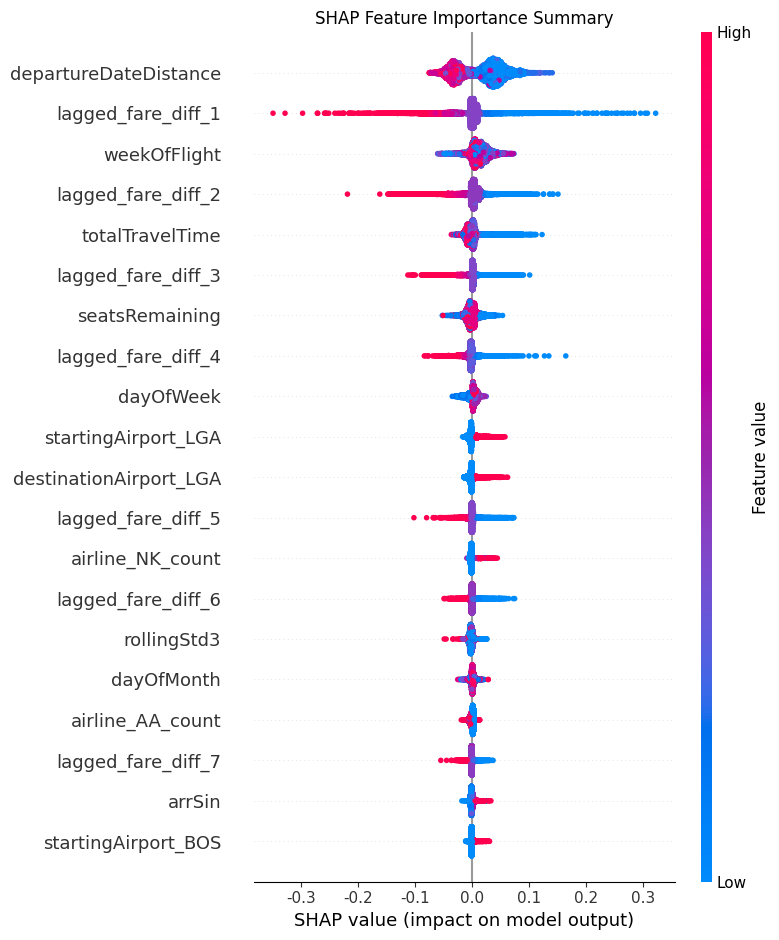

Generating SHAP dependence plot for the most important feature...


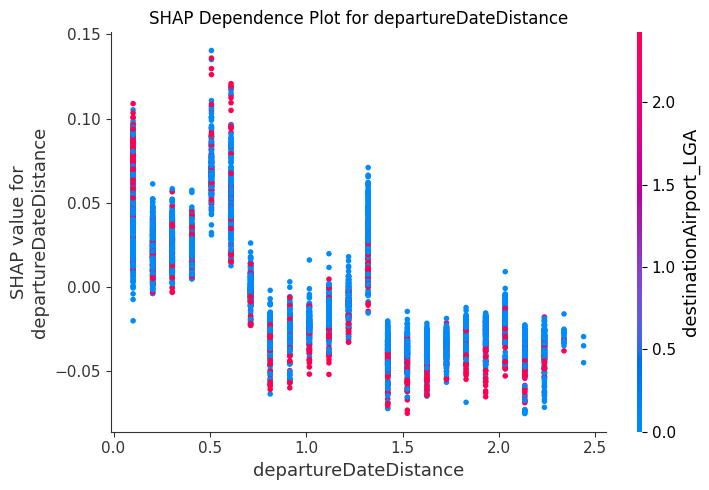

SHAP analysis complete.


In [21]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # So, startingAirport_indexed is at stage 0, and destinationAirport_indexed is at stage 2.
    string_indexer_model_starting = pipeline_model.stages[0]
    string_indexer_model_destination = pipeline_model.stages[2]
    
    # Get sorted unique categories for each airport
    starting_airport_categories = string_indexer_model_starting.labels
    destination_airport_categories = string_indexer_model_destination.labels
    
    # Construct names for one-hot encoded features
    encoded_starting_airport_names = [f'startingAirport_{cat}' for cat in starting_airport_categories]
    encoded_destination_airport_names = [f'destinationAirport_{cat}' for cat in destination_airport_categories]
    
    # Extract the VectorAssembler stage from the pipeline_model (it's at index 4)
    vector_assembler_stage = pipeline_model.stages[4]
    assembler_input_cols = vector_assembler_stage.getInputCols()
    
    # Initialize lists for numerical and expanded categorical feature names
    numerical_feature_names_for_shap = []
    expanded_categorical_feature_names = []
    
    # Iterate through the inputCols of the VectorAssembler
    for col_name in assembler_input_cols:
        if col_name.endswith('_encoded'):
            # This is an OHE categorical feature, need to expand it
            # Identify the original categorical column name (e.g., 'startingAirport' from 'startingAirport_encoded')
            original_cat_col_name = col_name.replace('_encoded', '')
    
            # Find the corresponding StringIndexer model to get the labels (categories)
            if original_cat_col_name == 'startingAirport':
                categories = starting_airport_categories
            elif original_cat_col_name == 'destinationAirport':
                categories = destination_airport_categories
            else:
                # Fallback for unexpected encoded columns, though should not happen with current setup
                categories = [f'{original_cat_col_name}_idx{i}' for i in range(pipeline_model.stages[assembler_input_cols.index(col_name)-1].numCategories)]
    
            # Expand into one-hot style names (e.g., 'startingAirport_LAX')
            expanded_categorical_feature_names.extend([f'{original_cat_col_name}_{cat}' for cat in categories])
        else:
            # This is a numerical feature, add directly
            numerical_feature_names_for_shap.append(col_name)
    
    # Combine numerical and expanded categorical feature names in the correct order
    feature_names = numerical_feature_names_for_shap + expanded_categorical_feature_names
    
    print(f"Reconstructed feature names for SHAP: {feature_names}")
    print(f"Length of reconstructed feature names: {len(feature_names)}")
    print(f"Expected number of features from X_test_np: {X_test_np.shape[1]}")
    
    # Ensure the lengths match before proceeding
    if len(feature_names) != X_test_np.shape[1]:
        raise ValueError(f"Mismatch in feature names length ({len(feature_names)}) and X_test_np columns ({X_test_np.shape[1]}). SHAP cannot proceed.")
    
    # Set feature_names for the model, in case xgb.plot_importance is used later
    final_model.feature_names = feature_names
    
    # Initialize Javascript for SHAP plots
    shap.initjs()
    
    # Create a SHAP TreeExplainer for the XGBoost model
    explainer = shap.TreeExplainer(final_model)
    
    # Calculate SHAP values for a sample of the test data for faster computation and visualization
    sample_size = builtin_min(10000, X_test_np.shape[0])
    shap_sample_indices = np.random.choice(X_test_np.shape[0], sample_size, replace=False)
    X_test_sample_np = X_test_np[shap_sample_indices]
    
    # Convert to Pandas DataFrame for SHAP plotting to ensure feature names are correctly associated
    X_test_sample_pd = pd.DataFrame(X_test_sample_np, columns=feature_names)
    
    print(f"Calculating SHAP values for {X_test_sample_pd.shape[0]} samples...")
    shap_values = explainer.shap_values(X_test_sample_pd)
    
    print("Generating SHAP summary plot...")
    shap.summary_plot(shap_values, X_test_sample_pd, feature_names=feature_names, show=False)
    plt.title("SHAP Feature Importance Summary")
    # Apply formatting to the x-axis (SHAP values)
    plt.gca().xaxis.set_major_formatter(plt.FormatStrFormatter('%.1f'))
    plt.tight_layout()
    plt.show()
    
    print("Generating SHAP dependence plot for the most important feature...")
    shap_abs_means = np.abs(shap_values).mean(0)
    most_important_feature_idx = np.argmax(shap_abs_means)
    most_important_feature_name = feature_names[most_important_feature_idx]
    
    shap.dependence_plot(most_important_feature_name, shap_values, X_test_sample_pd, feature_names=feature_names, show=False)
    plt.title(f"SHAP Dependence Plot for {most_important_feature_name}")
    plt.tight_layout()
    plt.show()
    
    print("SHAP analysis complete.")
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


In [ ]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # --- Reconstruct feature names for the no-time-series model ---
    
    
    string_indexer_model_starting_no_ts = pipeline_model_no_ts.stages[0]
    string_indexer_model_destination_no_ts = pipeline_model_no_ts.stages[2]
    
    # Get sorted unique categories for each airport
    starting_airport_categories_no_ts = string_indexer_model_starting_no_ts.labels
    destination_airport_categories_no_ts = string_indexer_model_destination_no_ts.labels
    
    # Construct names for one-hot encoded features
    encoded_starting_airport_names_no_ts = [f'startingAirport_{cat}' for cat in starting_airport_categories_no_ts]
    encoded_destination_airport_names_no_ts = [f'destinationAirport_{cat}' for cat in destination_airport_categories_no_ts]
    
    # Extract the VectorAssembler stage from the pipeline_model_no_ts
    # It's the second to last stage in pipeline_with_scaler_no_ts
    vector_assembler_stage_no_ts = pipeline_model_no_ts.stages[len(pipeline_model_no_ts.stages) - 2]
    assembler_input_cols_no_ts = vector_assembler_stage_no_ts.getInputCols()
    
    # Initialize lists for numerical and expanded categorical feature names
    numerical_feature_names_for_shap_no_ts = []
    expanded_categorical_feature_names_no_ts = []
    
    # Iterate through the inputCols of the VectorAssembler to build the feature names in order
    for col_name in assembler_input_cols_no_ts:
        if col_name.endswith('_encoded'):
            original_cat_col_name = col_name.replace('_encoded', '')
            if original_cat_col_name == 'startingAirport':
                categories = starting_airport_categories_no_ts
            elif original_cat_col_name == 'destinationAirport':
                categories = destination_airport_categories_no_ts
            else:
                # Fallback for unexpected encoded columns, should not be reached with current setup
                categories = [f'{original_cat_col_name}_idx{i}' for i in range(1)] # Placeholder if needed
            expanded_categorical_feature_names_no_ts.extend([f'{original_cat_col_name}_{cat}' for cat in categories])
        else:
            numerical_feature_names_for_shap_no_ts.append(col_name)
    
    # Combine numerical and expanded categorical feature names in the correct order
    feature_names_no_ts = numerical_feature_names_for_shap_no_ts + expanded_categorical_feature_names_no_ts
    
    print(f"Reconstructed feature names for SHAP (no time series): {feature_names_no_ts}")
    print(f"Length of reconstructed feature names (no time series): {len(feature_names_no_ts)}")
    print(f"Expected number of features from X_test_np_no_ts: {X_test_np_no_ts.shape[1]}")
    
    # Ensure the lengths match before proceeding
    if len(feature_names_no_ts) != X_test_np_no_ts.shape[1]:
        raise ValueError(f"Mismatch in feature names length ({len(feature_names_no_ts)}) and X_test_np_no_ts columns ({X_test_np_no_ts.shape[1]}). SHAP cannot proceed.")
    
    # Initialize Javascript for SHAP plots
    shap.initjs()
    
    # Create a SHAP TreeExplainer for the XGBoost model without time series features
    explainer_no_ts = shap.TreeExplainer(final_model_no_ts)
    
    # Calculate SHAP values for a sample of the test data
    sample_size_no_ts = builtin_min(10000, X_test_np_no_ts.shape[0])
    shap_sample_indices_no_ts = np.random.choice(X_test_np_no_ts.shape[0], sample_size_no_ts, replace=False)
    X_test_sample_np_no_ts = X_test_np_no_ts[shap_sample_indices_no_ts]
    
    # Convert to Pandas DataFrame for SHAP plotting to ensure feature names are correctly associated
    X_test_sample_pd_no_ts = pd.DataFrame(X_test_sample_np_no_ts, columns=feature_names_no_ts)
    
    print(f"Calculating SHAP values for {X_test_sample_pd_no_ts.shape[0]} samples (no time series)...")
    shap_values_no_ts = explainer_no_ts.shap_values(X_test_sample_pd_no_ts)
    
    print("Generating SHAP summary plot...")
    plt.figure(figsize=(12, 8)) # Adjust figure size for better readability
    shap.summary_plot(shap_values_no_ts, X_test_sample_pd_no_ts, plot_type="bar", max_display=len(feature_names_no_ts), show=False) # Plot all features
    plt.title("SHAP Feature Importance Summary (No Time Series) - All Features")
    # Apply formatting to the x-axis (SHAP values)
    plt.gca().xaxis.set_major_formatter(plt.FormatStrFormatter('%.1f'))
    plt.tight_layout()
    plt.show()
    
    print("Generating SHAP dependence plot for the most important feature (no time series)...")
    shap_abs_means_no_ts = np.abs(shap_values_no_ts).mean(0)
    most_important_feature_idx_no_ts = np.argmax(shap_abs_means_no_ts)
    most_important_feature_name_no_ts = feature_names_no_ts[most_important_feature_idx_no_ts]
    
    plt.figure(figsize=(10, 6)) # Adjust figure size for better readability
    shap.dependence_plot(most_important_feature_name_no_ts, shap_values_no_ts, X_test_sample_pd_no_ts, feature_names=feature_names_no_ts, show=False)
    plt.title(f"SHAP Dependence Plot for {most_important_feature_name_no_ts} (No Time Series)")
    plt.tight_layout()
    plt.show()
    
    print("SHAP analysis complete.")
    
    
    # Plotting feature importance using XGBoost's built-in function
    print("Generating XGBoost built-in feature importance plot (No Time Series) with annotations...")
    
    # Set feature names on the model's booster directly before getting scores
    # This ensures that get_score() returns a dictionary with actual feature names as keys
    final_model_no_ts.set_params(feature_names=feature_names_no_ts)
    
    # Get feature importances. Now, importance.items() will yield (feature_name, score)
    importance_dict = final_model_no_ts.get_booster().get_score(importance_type='gain')
    
    # Sort the features by importance in descending order
    sorted_importance = sorted(importance_dict.items(), key=lambda x: x[1], reverse=True)
    
    # Separate feature names and their importance scores
    sorted_features = [item[0] for item in sorted_importance]
    sorted_scores = [item[1] for item in sorted_importance]
    
    plt.figure(figsize=(12, 10)) # Adjusted figure size for more features
    plt.barh(sorted_features, sorted_scores) # Use barh for horizontal bars
    
    # Annotate each bar with its importance value, formatted to one decimal place
    for i, (feature, score) in enumerate(sorted_importance):
        plt.text(score + 0.005 * max(sorted_scores), i, f'{score:.1f}', va='center', fontsize=8)
    
    plt.title("XGBoost Feature Importance (Gain) - No Time Series - All Features")
    plt.xlabel("Feature Importance (Gain)")
    plt.ylabel("Features")
    
    # Adjust y-axis tick labels for better readability
    plt.yticks(fontsize=8, ha='right')
    plt.gca().invert_yaxis() # Display most important feature at the top
    plt.subplots_adjust(left=0.3) # Give more room for long y-axis labels
    
    plt.tight_layout()
    plt.show()
    
    print("XGBoost built-in feature importance plot generated.")
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


## Deep learning

GRU, CNN, LSTM and Transformer models predict changes in log fare. Training uses bounded sliding windows; validation and test use the latest valid target per itinerary. All models share the same test target keys.


### Sequentializing data

Windows contain up to 10 chronological feature rows ending at the target observation. The label is `fareChange`; neither the current fare nor its change enters the features. The current row contains known itinerary/calendar attributes and strictly lagged price information. Training selects up to two windows per itinerary, spaced at least seven observations apart, to limit additional work. Set `DL_MAX_TRAIN_WINDOWS_PER_ITINERARY = 1` to reproduce latest-only training. Validation uses the earlier half of validation dates for checkpoint selection; the later half is reserved for stacking. Test windows keep prior-date context and the original common test targets.

Shared keys are created before any XGBoost fit. DL preprocessing and loaders can run while CV, optimization, baseline fitting and feature-importance cells are skipped.


In [22]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    LEVEL_COL = 'totalFare'
    ANCHOR_COL = 'lagged_fare_1'
    TARGET_COL = 'fareChange'
    EXCLUDE_FROM_FEATURES_DL = {
        'legId', 'firstDepartureTime', 'finalArrivalTime', 'flightDate', 'searchDate',
        'isBasicEconomy', 'isNonStop', TARGET_COL, LEVEL_COL, ANCHOR_COL, 'fareChange', 'rollingMean3', 'priceRankPercentile',
        'priceVsRouteMean', 'priceVsRouteMin', 'rollingTrend'
    }
    EXCLUDE_FROM_FEATURES_DL.update(f'lagged_fare_{i}' for i in range(1, 22))
    categorical_to_encode_dl = ['startingAirport', 'destinationAirport']
    numerical_to_keep_as_numerical_dl = sorted(
        field.name for field in df_top5_mod.schema
        if field.name not in EXCLUDE_FROM_FEATURES_DL
        and field.name not in categorical_to_encode_dl
        and isinstance(field.dataType, (IntegerType, FloatType, DoubleType))
    )
    print(f'DL numerical features: {numerical_to_keep_as_numerical_dl}')
    
    stages_dl = []
    encoded_categorical_names_dl = []
    for cat_col in categorical_to_encode_dl:
        indexer = StringIndexer(inputCol=cat_col, outputCol=cat_col + '_indexed', handleInvalid='keep')
        encoder = OneHotEncoder(inputCol=indexer.getOutputCol(), outputCol=cat_col + '_encoded')
        stages_dl += [indexer, encoder]
        encoded_categorical_names_dl.append(cat_col + '_encoded')
    assembler_dl = VectorAssembler(
        inputCols=numerical_to_keep_as_numerical_dl + encoded_categorical_names_dl,
        outputCol='rawFeatures', handleInvalid='skip'
    )
    scaler_dl = StandardScaler(inputCol='rawFeatures', outputCol='scaledFeatures', withStd=True, withMean=True)
    dl_feature_pipeline = Pipeline(stages=stages_dl + [assembler_dl, scaler_dl])
    
    raw_train_dl_df = df_sampled_raw.filter(col('searchDate') <= train_date_boundary)
    raw_val_dl_df = df_sampled_raw.filter(
        (col('searchDate') > train_date_boundary) & (col('searchDate') <= val_date_boundary)
    )
    raw_test_dl_df = df_sampled_raw.filter(col('searchDate') > val_date_boundary)
    dl_feature_pipeline_model = dl_feature_pipeline.fit(raw_train_dl_df)
    
    # Transform once so validation and test samples can retain earlier-period context.
    df_processed_dl_all = dl_feature_pipeline_model.transform(df_sampled_raw)
    SEQUENCE_LENGTH = 10
    def prepare_ordered_sequences(processed_df, target_keys):
        grouped = processed_df.groupBy('legId', 'flightDate').agg(
            F.collect_list(F.struct(
                col('searchDate').alias('searchDate'),
                col('scaledFeatures').alias('features'),
                col(LEVEL_COL).alias('target'),      # log-fare level, kept for the buy-time trajectory code
                col(TARGET_COL).alias('change'),     # price-model target
                col(ANCHOR_COL).alias('anchor')      # previous log fare
            )).alias('unordered_steps')
        )
    
        @udf(ArrayType(StructType([
            StructField('features', VectorUDT(), nullable=False),
            StructField('target', DoubleType(), nullable=False),
            StructField('change', DoubleType(), nullable=False),
            StructField('anchor', DoubleType(), nullable=False)
        ])))
        def select_forecast_window(steps, target_search_date):
            if not steps or target_search_date is None:
                return []
            ordered_steps = sorted(steps, key=lambda step: step['searchDate'])
            target_indices = [
                index for index, step in enumerate(ordered_steps)
                if step['searchDate'] == target_search_date
            ]
            if not target_indices:
                return []
            target_index = target_indices[0]
            first_index = max(0, target_index - SEQUENCE_LENGTH + 1)
            return [
                {'features': step['features'], 'target': float(step['target']),
                 'change': float(step['change']), 'anchor': float(step['anchor'])}
                for step in ordered_steps[first_index:target_index + 1]
            ]
    
        targets_with_context = grouped.join(target_keys, ['legId', 'flightDate'], 'inner')
        return targets_with_context.withColumn(
            'sequences', select_forecast_window(col('unordered_steps'), col('targetSearchDate'))
        ).drop('unordered_steps').filter(F.size(col('sequences')) > 0)
    
    # Keys were created before optional XGBoost optimization/fitting.
    df_final_dl_data_train = prepare_ordered_sequences(df_processed_dl_all, train_target_keys)
    df_final_dl_data_val = prepare_ordered_sequences(df_processed_dl_all, val_target_keys)
    df_final_dl_data_test = prepare_ordered_sequences(
        df_processed_dl_all,
        test_target_keys.withColumnRenamed('searchDate', 'targetSearchDate')
    )
    
    displayed_dl_test_keys = df_final_dl_data_test.select(
        'legId', 'flightDate', col('targetSearchDate').alias('searchDate')
    )
    missing_dl_test_keys = test_target_keys.join(
        displayed_dl_test_keys, on=['legId', 'flightDate', 'searchDate'], how='left_anti'
    )
    if missing_dl_test_keys.limit(1).count():
        raise ValueError('DL sequence labels do not cover the exact XGBoost test target keys.')
    print('Chronologically ordered DL forecast windows with historical split context:')
    for split_name, split_df in [
        ('train', df_final_dl_data_train),
        ('validation', df_final_dl_data_val),
        ('test', df_final_dl_data_test)
    ]:
        print(f'{split_name}: {split_df.count()} itinerary targets')
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


DL numerical features: ['airline_4B_count', 'airline_9K_count', 'airline_9X_count', 'airline_AA_count', 'airline_AS_count', 'airline_B6_count', 'airline_DL_count', 'airline_F9_count', 'airline_LF_count', 'airline_NK_count', 'airline_SY_count', 'airline_UA_count', 'arrCos', 'arrSin', 'dayOfMonth', 'dayOfWeek', 'depCos', 'depSin', 'departureDateDistance', 'elapsedDays', 'isWeekend', 'lagged_fare_diff_1', 'lagged_fare_diff_10', 'lagged_fare_diff_11', 'lagged_fare_diff_12', 'lagged_fare_diff_13', 'lagged_fare_diff_14', 'lagged_fare_diff_15', 'lagged_fare_diff_16', 'lagged_fare_diff_17', 'lagged_fare_diff_18', 'lagged_fare_diff_19', 'lagged_fare_diff_2', 'lagged_fare_diff_20', 'lagged_fare_diff_3', 'lagged_fare_diff_4', 'lagged_fare_diff_5', 'lagged_fare_diff_6', 'lagged_fare_diff_7', 'lagged_fare_diff_8', 'lagged_fare_diff_9', 'numberOfStops', 'rollingStd3', 'seatsRemaining', 'totalTravelTime', 'weekOfFlight']
Chronologically ordered DL forecast windows with historical split context:
train

In [23]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    import builtins
    import torch
    from torch.nn.utils.rnn import pad_sequence
    
    class CustomSequenceDataset(torch.utils.data.Dataset):
        def __init__(self, X_list, y_tensor, lengths):
            self.X_list = X_list
            self.y_tensor = y_tensor
            self.lengths = lengths
    
        def __len__(self):
            return len(self.X_list)
    
        def __getitem__(self, idx):
            return self.X_list[idx], self.y_tensor[idx], self.lengths[idx]
    
    def sequence_collate_fn(batch):
        # No length-sorting here: batch order == dataset order, so test predictions stay aligned with
        # test_anchor_np. The recurrent models pack with enforce_sorted=False instead.
        sequences, targets, lengths = zip(*batch)
        return (
            pad_sequence(sequences, batch_first=True),
            torch.stack(targets),
            torch.tensor(lengths, dtype=torch.long)
        )
    
    batch_size = 64
    
    def spark_sequences_to_variable_numpy(spark_df_sequences):
        X_list, y_list, anchors, lengths, keys = [], [], [], [], []
        for row in spark_df_sequences.toLocalIterator():
            sequence_data = row.sequences
            if not sequence_data:
                continue
            feature_sequence = torch.stack([
                torch.tensor(item.features.toArray(), dtype=torch.float32)
                for item in sequence_data
            ])
            if not torch.isfinite(feature_sequence).all():
                raise ValueError('Non-finite DL feature sequence.')
            X_list.append(feature_sequence)
            y_list.append(float(sequence_data[-1].change))     # target: change in log fare on the target day
            anchors.append(float(sequence_data[-1].anchor))    # yesterday's log fare (for evaluation only)
            lengths.append(len(feature_sequence))
            keys.append((row.legId, row.flightDate, row.targetSearchDate))
    
        if not X_list:
            raise ValueError('No usable itinerary sequences were produced for a model split.')
        y_tensor = torch.tensor(y_list, dtype=torch.float32).unsqueeze(1)
        return X_list, y_tensor, np.asarray(anchors, dtype=float), lengths, keys
    
    print('Building aligned train/validation/test tensors...')
    X_train_list_dl, y_train_tensor_dl, train_anchor_np, lengths_train, train_sequence_keys = spark_sequences_to_variable_numpy(df_final_dl_data_train)
    X_val_list_dl, y_val_tensor_dl, val_anchor_np, lengths_val, val_sequence_keys = spark_sequences_to_variable_numpy(df_final_dl_data_val)
    X_test_list_dl, y_test_tensor_dl, test_anchor_np, lengths_test, test_sequence_keys = spark_sequences_to_variable_numpy(df_final_dl_data_test)
    
    # Standardise the target with TRAIN statistics only (changes are small numbers). Evaluation undoes this via DELTA_STD.
    DELTA_STD = float(y_train_tensor_dl.std())
    if not np.isfinite(DELTA_STD) or DELTA_STD <= 0:
        raise ValueError("Training change targets need a finite, non-zero standard deviation.")
    y_train_tensor_dl = y_train_tensor_dl / DELTA_STD
    y_val_tensor_dl = y_val_tensor_dl / DELTA_STD
    y_test_tensor_dl = y_test_tensor_dl / DELTA_STD
    print(f'Std of the one-day log-fare change (train targets): {DELTA_STD:.4f}')
    
    for split_name, sequences, lengths in [
        ('train', X_train_list_dl, lengths_train),
        ('validation', X_val_list_dl, lengths_val),
        ('test', X_test_list_dl, lengths_test)
    ]:
        print(
            f'{split_name}: {len(sequences)} targets; history lengths '
            f'min={builtins.min(lengths)}, median={int(np.median(lengths))}, max={builtins.max(lengths)}'
        )
    
    train_dataset_dl = CustomSequenceDataset(X_train_list_dl, y_train_tensor_dl, lengths_train)
    val_dataset_dl = CustomSequenceDataset(X_val_list_dl, y_val_tensor_dl, lengths_val)
    test_dataset_dl = CustomSequenceDataset(X_test_list_dl, y_test_tensor_dl, lengths_test)
    train_loader_dl = DataLoader(train_dataset_dl, batch_size=batch_size, shuffle=True, collate_fn=sequence_collate_fn)
    val_loader_dl = DataLoader(val_dataset_dl, batch_size=batch_size, shuffle=False, collate_fn=sequence_collate_fn)
    test_loader_dl = DataLoader(test_dataset_dl, batch_size=batch_size, shuffle=False, collate_fn=sequence_collate_fn)
    
    feature_dim = X_train_list_dl[0].shape[1]
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    
    # A count alone is insufficient: assert equality of supervised target keys and labels.
    def assert_matched_targets(tabular_pdf, sequence_keys, scaled_targets, split_name):
        expected = tabular_pdf.set_index(KEY_COLUMNS)[TARGET_COL]
        actual = pd.Series(scaled_targets.numpy().reshape(-1) * DELTA_STD,
                           index=pd.MultiIndex.from_tuples(sequence_keys, names=KEY_COLUMNS))
        if not expected.index.is_unique or not actual.index.is_unique or set(expected.index) != set(actual.index):
            raise ValueError(f'{split_name}: tabular/DL target keys differ.')
        np.testing.assert_allclose(expected.reindex(actual.index).to_numpy(), actual.to_numpy(), rtol=1e-5, atol=1e-7)
    if MATCH_TRAINING_TARGETS:
        assert_matched_targets(xgb_train_pd, train_sequence_keys, y_train_tensor_dl, 'train')
        assert_matched_targets(xgb_train_pd_no_ts, train_sequence_keys, y_train_tensor_dl, 'no-TS train')
    assert_matched_targets(xgb_val_pd, val_sequence_keys, y_val_tensor_dl, 'validation')
    assert_matched_targets(xgb_val_pd_no_ts, val_sequence_keys, y_val_tensor_dl, 'no-TS validation')
    assert_matched_targets(common_test_pd, test_sequence_keys, y_test_tensor_dl, 'test')
    assert_matched_targets(common_test_pd_no_ts, test_sequence_keys, y_test_tensor_dl, 'no-TS test')
    print('Target-key/label audit passed. Same supervised train targets:', MATCH_TRAINING_TARGETS)
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


Building aligned train/validation/test tensors...
Std of the one-day log-fare change (train targets): 0.1825
train: 264976 targets; history lengths min=1, median=10, max=10
validation: 37126 targets; history lengths min=1, median=10, max=10
test: 41761 targets; history lengths min=1, median=10, max=10
Target-key/label audit passed. Same supervised train targets: True


### Why validation loss plateaus, and what is comparable

The newly saved run on GitHub `main` (commit `6383ba8`) used **149,668 DL train targets**, **2,763,030 lagged-XGBoost train targets**, and **6,203,100 no-TS-XGBoost train targets**. XGBoost also refitted on validation labels; DL used validation only for early stopping. Test coverage matched (41,761 targets), but the ranking did not isolate architecture from training data. The saved run was latest-only: bounded windows and stacking from the earlier local edit were not present in that committed version.

The DL models do learn. GRU training MSE fell 0.7910→0.5651 while validation reached its best 0.6217 at epoch 6; LSTM reached 0.6234 at epoch 6; CNN improved only 0.6568→0.6485 before deteriorating. Transformer validation fell 0.6738→0.6041 (10.34%) at epoch 11, although training continued down to 0.5159. Positive test skill (16.77–21.11%) confirms predictive learning. Continued training improvement without sustained validation improvement is consistent with overfitting; limited predictive signal, split shift and objective mismatch remain hypotheses to test, not established causes.

Raw validation MSE is in units of **training target standard deviation squared**, not a percentage error. The zero-change baseline MSE need not equal 1 in validation because change variance and the mean can differ by period. Dropout is active in train loss but disabled in validation loss, so their numerical gap is not a clean generalization estimate. The diagnostics below print zero-change/constant-mean baselines, change rates, target distributions, history lengths, known/unseen itinerary coverage and validation error by changed/unchanged rows. A validation-selected model must beat the actual validation persistence loss, not an assumed loss of 1.

Code inspection also identifies two plausible bottlenecks: uncentered inputs can bias recurrent gates/attention projections, and CNN mean pooling can dilute the most recent row. Centering is enabled on training-fitted DL features; the current-row Ridge diagnostic tests how much sequence modeling adds. AdamW, gradient clipping and plateau scheduling make optimization more observable and controlled; no full-data improvement from these changes has yet been measured. One-day regression MSE emphasizes larger moves, whereas unchanged-price and buying-decision performance can favor different objectives. Do not increase epochs or replace the loss merely to obtain a lower displayed number.

**New default protocol:** all standalone price models use identical labeled train targets (up to two spaced windows per itinerary), the same early-validation targets, and the same test targets. No-TS XGBoost is restricted to the same lag-eligible keys; XGBoost fits training labels only. Runtime assertions check keys and labels, not just counts. This removes the supervised sample-count/refit confound. It still does not mean identical input information or optimization effort: DL receives a sequence of covariate rows while XGBoost receives the target row's engineered lags, and no-TS deliberately receives fewer features. Hyperparameters reused from the historical all-validation search also retain that selection history. Stacking uses an additional later-validation meta-training block and should be reported separately from this matched standalone comparison. With `MATCH_TRAINING_TARGETS=False`, the original XGBoost sample-count advantage returns and the notebook says so explicitly.


In [ ]:
# Training diagnostics
from sklearn.linear_model import Ridge
import copy

def report_target_distributions():
    rows = []
    train_mean = float(y_train_tensor_dl.mean())
    for label, targets, lengths, keys in [
        ('train', y_train_tensor_dl, lengths_train, train_sequence_keys),
        ('validation', y_val_tensor_dl, lengths_val, val_sequence_keys),
        ('test (descriptive only)', y_test_tensor_dl, lengths_test, test_sequence_keys),
    ]:
        y = targets.numpy().reshape(-1)
        rows.append({'split': label, 'targets': len(y), 'unchanged_fraction': np.mean(y == 0),
                     'mean_log_change': float(np.mean(y) * DELTA_STD),
                     'std_log_change': float(np.std(y) * DELTA_STD),
                     'zero_change_MSE_scaled': float(np.mean(y ** 2)),
                     'train_mean_MSE_scaled': float(np.mean((y - train_mean) ** 2)),
                     'median_history_rows': float(np.median(lengths)),
                     'full_history_fraction': float(np.mean(np.asarray(lengths) == SEQUENCE_LENGTH))})
    print(pd.DataFrame(rows).to_string(index=False))
    trained_itineraries = {k[:2] for k in train_sequence_keys}
    print('Validation targets from unseen itinerary/flight pairs:',
          f'{np.mean([k[:2] not in trained_itineraries for k in val_sequence_keys]):.1%}')

def validation_prediction_diagnostics(model, label):
    model.eval()
    model_device = next(model.parameters()).device
    with torch.no_grad():
        pred = np.concatenate([model(x.to(model_device), lengths.to(model_device)).cpu().numpy().reshape(-1)
                               for x, _, lengths in val_loader_dl])
    y = y_val_tensor_dl.numpy().reshape(-1)
    rows = []
    for group, mask in [('all', np.ones(len(y), dtype=bool)), ('unchanged', y == 0), ('changed', y != 0)]:
        if not mask.any(): continue
        error = float(np.mean((y[mask] - pred[mask]) ** 2))
        baseline = float(np.mean(y[mask] ** 2))
        rows.append({'model': label, 'validation_group': group, 'targets': int(mask.sum()),
                     'MSE_scaled': error, 'persistence_MSE_scaled': baseline,
                     'skill': 1 - error / baseline if baseline > 0 else np.nan,
                     'prediction_std_log': float(np.std(pred[mask]) * DELTA_STD)})
    print(pd.DataFrame(rows).to_string(index=False))
    return pd.DataFrame(rows)

# Same labeled targets, using only the most recent covariate row.
last_row_ridge = Ridge(alpha=10.0)
last_row_ridge.fit(np.stack([seq[-1].numpy() for seq in X_train_list_dl]),
                   y_train_tensor_dl.numpy().reshape(-1))
ridge_val_pred = last_row_ridge.predict(np.stack([seq[-1].numpy() for seq in X_val_list_dl]))
ridge_val_y = y_val_tensor_dl.numpy().reshape(-1)
ridge_val_mse = float(np.mean((ridge_val_y - ridge_val_pred) ** 2))
val_persistence_mse = float(np.mean(ridge_val_y ** 2))
print(f'Current-row Ridge validation MSE: {ridge_val_mse:.4f}; '
      f'skill: {1 - ridge_val_mse / val_persistence_mse:+.4f}' if val_persistence_mse > 0
      else f'Current-row Ridge validation MSE: {ridge_val_mse:.4f}; persistence variance is zero')
report_target_distributions()

# Opt-in tiny-batch check: copied model; no checkpoint or test labels are used.
def tiny_batch_overfit_check(model, steps=200, sample_size=64, learning_rate=0.003):
    probe = copy.deepcopy(model)
    probe.train()
    for module in probe.modules():
        if isinstance(module, nn.Dropout): module.p = 0.0
        if isinstance(module, (nn.GRU, nn.LSTM, nn.MultiheadAttention)): module.dropout = 0.0
    optimizer = optim.Adam(probe.parameters(), lr=learning_rate)
    selected = np.random.default_rng(42).choice(len(train_dataset_dl),
                    size=builtins.min(sample_size, len(train_dataset_dl)), replace=False)
    x, y, lengths = sequence_collate_fn([train_dataset_dl[int(i)] for i in selected])
    probe_device = next(probe.parameters()).device
    x, y, lengths = x.to(probe_device), y.to(probe_device), lengths.to(probe_device)
    criterion = nn.MSELoss()
    with torch.no_grad(): initial = float(criterion(probe(x, lengths), y))
    first_grad_norm = None
    for _ in range(steps):
        optimizer.zero_grad()
        loss = criterion(probe(x, lengths), y)
        if not torch.isfinite(loss): raise ValueError('Tiny-batch loss became non-finite.')
        loss.backward()
        norm = torch.nn.utils.clip_grad_norm_(probe.parameters(), 1.0)
        if first_grad_norm is None: first_grad_norm = float(norm)
        optimizer.step()
    with torch.no_grad(): final = float(criterion(probe(x, lengths), y))
    result = {'initial_MSE': initial, 'final_MSE': final,
              'final_to_initial': final / initial if initial > 0 else np.nan,
              'initial_gradient_norm': first_grad_norm, 'steps': steps}
    print('Tiny-batch diagnostic:', result)
    return result
# After constructing a model, run tiny_batch_overfit_check(model) if optimization is in doubt.
# A substantial drop supports working gradients/label plumbing; it does not prove generalization.


Current-row Ridge validation MSE: 0.5972; skill: +0.0951
                  split  targets  unchanged_fraction  mean_log_change  std_log_change  zero_change_MSE_scaled  train_mean_MSE_scaled  median_history_rows  full_history_fraction
                  train   264976            0.485308         0.033749        0.182482                1.034200               0.999996                 10.0               0.705396
             validation    37126            0.634353         0.035988        0.143805                0.659914               0.621171                 10.0               0.662393
test (descriptive only)    41761            0.418524         0.059250        0.168739                0.960473               0.874579                 10.0               0.693159
Validation targets from unseen itinerary/flight pairs: 25.4%


### Modeling

The GRU predicts the (standardised) one-day change in log fare on each selected training target day, using the target-day feature row and up to 20 observed rows of history. Validation/test windows retain earlier-date history. Price levels are rebuilt as yesterday's log fare plus the predicted change, and all models are scored on the same latest valid test targets as XGBoost and the persistence baseline.


In [ ]:
# ============================================================
# DEFINE GRU MODEL
# SEQUENCE-TO-ONE
# ============================================================

class GRUModel(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size,
        output_size,
        num_layers=2,
        dropout=0.2
    ):

        super(GRUModel, self).__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        self.fc1 = nn.Linear(hidden_size, 32)

        self.relu = nn.ReLU()

        self.fc2 = nn.Linear(32, output_size)

    def forward(self, x, lengths):
        # --------------------------------------------
        # Initial hidden state
        # --------------------------------------------
        h0 = torch.zeros(
            self.num_layers,
            x.size(0), # batch_size
            self.hidden_size
        ).to(x.device)

        # --------------------------------------------
        # Pack padded sequence:
        # takes the padded input tensor and the tensor of original lengths,
        # effectively telling the recurrent layer to ignore padding, optimize and process dynamically
        # --------------------------------------------
        packed_input = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)

        # --------------------------------------------
        # GRU forward
        # --------------------------------------------
        packed_output, _ = self.gru(packed_input, h0)

        # --------------------------------------------
        # Unpack padded sequence
        # --------------------------------------------
        output, _ = pad_packed_sequence(packed_output, batch_first=True)

        # Take ONLY FINAL timestep output of the actual sequence
        last_outputs = []
        for i, length in enumerate(lengths):
            # length - 1 because sequence lengths are 1-indexed, but tensor indices are 0-indexed
            last_outputs.append(output[i, length - 1, :])
        out = torch.stack(last_outputs) # Stack the collected outputs to form a batch

        out = self.dropout(out)
        out = self.fc1(out)
        out = self.relu(out)
        out = self.fc2(out)

        return out

# ============================================================
# INITIALIZE GRU MODEL
# ============================================================

# Dynamically define feature_dim from the training dataset list
feature_dim = X_train_list_dl[0].shape[1] if len(X_train_list_dl) > 0 else 57

hidden_size = 64
output_size = 1

gru_model = GRUModel(
    input_size=feature_dim,
    hidden_size=hidden_size,
    output_size=output_size
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

gru_model.to(device)

print(f"\nUsing device: {device}")

# ============================================================
# LOSS + OPTIMIZER
# ============================================================
# Mean squared error is the criterion, but square root will be taken to determine loss for comparability
criterion_gru = nn.MSELoss()

optimizer_gru = optim.AdamW(
    gru_model.parameters(),
    lr=0.001, weight_decay=1e-4
)

epochs = 100
scheduler_gru = optim.lr_scheduler.ReduceLROnPlateau(optimizer_gru, mode='min', factor=0.5, patience=3)
val_zero_mse_gru = float(torch.mean(y_val_tensor_dl ** 2))

# ============================================================
# TRAINING LOOP
# ============================================================

best_val_loss_gru = float("inf")
early_stopping_patience_gru = 10 # Number of epochs to wait for improvement
patience_counter_gru = 0

print("\nTraining GRU model with Early Stopping and Validation-Scheduled LR...")

for epoch in range(epochs):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    gru_model.train()

    train_loss_gru = 0.0

    for inputs, targets, lengths in train_loader_dl:

        inputs = inputs.to(device)
        targets = targets.to(device)
        lengths = lengths.to(device)

        optimizer_gru.zero_grad()

        outputs = gru_model(inputs, lengths)
        # RMSE loss
        loss = criterion_gru(outputs, targets)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(gru_model.parameters(), 1.0)
        optimizer_gru.step()

        train_loss_gru += loss.item() * inputs.size(0)

    train_loss_gru /= len(train_loader_dl.dataset)

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    gru_model.eval()

    val_loss_gru = 0.0

    with torch.no_grad():

        # Modified to unpack lengths
        for inputs, targets, lengths in val_loader_dl:

            inputs = inputs.to(device)
            targets = targets.to(device)
            lengths = lengths.to(device)

            outputs = gru_model(inputs, lengths)

            loss = criterion_gru(outputs, targets)

            val_loss_gru += loss.item() * inputs.size(0)

    val_loss_gru /= len(val_loader_dl.dataset)
    scheduler_gru.step(val_loss_gru)
    val_skill_gru = 1 - val_loss_gru / val_zero_mse_gru if val_zero_mse_gru > 0 else float("nan")

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss_gru:.4f} "
        f"Val Loss: {val_loss_gru:.4f} Val skill: {val_skill_gru:+.4f} LR: {optimizer_gru.param_groups[0]['lr']:.6f}"
    )

    # --------------------------------------------------------
    # Early Stopping
    # --------------------------------------------------------
    if val_loss_gru < best_val_loss_gru:
        best_val_loss_gru = val_loss_gru
        patience_counter_gru = 0
        # Save model when validation loss improves
        torch.save(
            gru_model.state_dict(),
            "best_gru_model.pth"
        )
    else:
        patience_counter_gru += 1
        if patience_counter_gru >= early_stopping_patience_gru:
            print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss for {early_stopping_patience_gru} epochs.")
            break

# ============================================================
# LOAD BEST MODEL
# ============================================================

gru_model.load_state_dict(
    torch.load("best_gru_model.pth")
)

# ============================================================
# EVALUATE ON TEST SET
# ============================================================

print("\nEvaluating GRU model on TEST set...")

gru_model.eval()

test_loss_gru = 0.0

all_predictions_gru = []
all_targets_gru = []

with torch.no_grad():

    for inputs, targets, lengths in test_loader_dl:

        inputs = inputs.to(device)
        targets = targets.to(device)
        lengths = lengths.to(device)
        outputs = gru_model(inputs, lengths)

        loss = criterion_gru(outputs, targets)

        test_loss_gru += loss.item() * inputs.size(0)

        all_predictions_gru.append(
            outputs.cpu().numpy()
        )

        all_targets_gru.append(
            targets.cpu().numpy()
        )

test_loss_gru /= len(test_loader_dl.dataset)

print(f"\nTest MSE Loss (GRU): {test_loss_gru:.4f}")

# ============================================================
# METRICS
# ============================================================

predictions_np_gru = np.concatenate(all_predictions_gru, axis=0).reshape(-1)
y_true_np_gru = np.concatenate(all_targets_gru, axis=0).reshape(-1)
price_metrics_gru = evaluate_change_predictions(
    y_true_np_gru, predictions_np_gru, test_anchor_np, 'GRU', scale=DELTA_STD
)
rmse_gru = price_metrics_gru['log_price_rmse']
mae_gru = mean_absolute_error(y_true_np_gru, predictions_np_gru)
r2_gru = price_metrics_gru['log_price_r2']

validation_prediction_diagnostics(gru_model, 'GRU')



Using device: cuda

Training GRU model with Early Stopping and Validation-Scheduled LR...
Epoch [1/100] Train Loss: 0.8057 Val Loss: 0.5499 Val skill: +0.1667 LR: 0.001000
Epoch [2/100] Train Loss: 0.7447 Val Loss: 0.5482 Val skill: +0.1693 LR: 0.001000
Epoch [3/100] Train Loss: 0.7136 Val Loss: 0.5727 Val skill: +0.1322 LR: 0.001000
Epoch [4/100] Train Loss: 0.6916 Val Loss: 0.5664 Val skill: +0.1417 LR: 0.001000
Epoch [5/100] Train Loss: 0.6750 Val Loss: 0.6002 Val skill: +0.0905 LR: 0.001000


The 1D CNN predicts the same change target. Padded steps are zeroed before every convolution and again after every activation, and temporal pooling is masked by the true sequence length, so padding cannot influence the prediction. No batch normalisation is used (it would mix statistics of padded and real steps across a batch).


In [ ]:
# ============================================================
# 1D CNN MODEL
# ============================================================

class CNN1DModel(nn.Module):

    def __init__(
        self,
        input_features,
        output_size=1,
        num_filters=64,
        kernel_size=3,
        dropout=0.2,
        dilation=2
    ):

        super(CNN1DModel, self).__init__()

        # ----------------------------------------------------
        # Conv block 1
        # ----------------------------------------------------

        self.conv1 = nn.Conv1d(
            in_channels=input_features,
            out_channels=num_filters,
            kernel_size=kernel_size,
            padding="same",
            dilation=dilation # Added dilation
        )

        self.bn1 = nn.Identity()

        # ----------------------------------------------------
        # Conv block 2
        # ----------------------------------------------------

        self.conv2 = nn.Conv1d(
            in_channels=num_filters,
            out_channels=num_filters,
            kernel_size=kernel_size,
            padding="same",
            dilation=dilation # Added dilation
        )

        self.bn2 = nn.Identity()

        # ----------------------------------------------------
        # Activations
        # ----------------------------------------------------

        self.relu = nn.ReLU()

        self.dropout_layer = nn.Dropout(dropout) # Renamed to avoid clash with module name

        # ----------------------------------------------------
        # Global pooling
        # ----------------------------------------------------

        # ----------------------------------------------------
        # Dense head
        # ----------------------------------------------------

        self.fc1 = nn.Linear(num_filters, 32)

        self.fc2 = nn.Linear(32, output_size)

    def forward(self, x, lengths):
        # x: (batch, seq_len, features); mask: (batch, 1, seq_len) with 1 on real steps
        mask = (torch.arange(x.size(1), device=x.device).unsqueeze(0) < lengths.unsqueeze(1)).unsqueeze(1).to(x.dtype)

        x = x.permute(0, 2, 1) * mask
        x = self.conv1(x)
        x = self.bn1(x.permute(0, 2, 1)).permute(0, 2, 1)
        x = self.relu(x) * mask

        x = self.conv2(x)
        x = self.bn2(x.permute(0, 2, 1)).permute(0, 2, 1)
        x = self.relu(x) * mask

        # masked mean over the real steps only
        x = x.sum(dim=-1) / lengths.clamp_min(1).unsqueeze(1).to(x.dtype)

        x = self.dropout_layer(x)
        x = self.fc1(x)
        x = self.relu(x)
        return self.fc2(x)

# ============================================================
# INITIALIZE CNN MODEL
# ============================================================

cnn1d_model = CNN1DModel(
    input_features=feature_dim,
    output_size=1,
    num_filters=64,
    kernel_size=3,
    dropout=0.3
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

cnn1d_model.to(device)

print(f"\nUsing device: {device}")

# ============================================================
# LOSS + OPTIMIZER (CNN)
# ============================================================

criterion_cnn = nn.MSELoss()

optimizer_cnn = optim.AdamW(
    cnn1d_model.parameters(),
    lr=0.001, weight_decay=1e-4
)

epochs = 100
scheduler_cnn = optim.lr_scheduler.ReduceLROnPlateau(optimizer_cnn, mode='min', factor=0.5, patience=3)
val_zero_mse_cnn = float(torch.mean(y_val_tensor_dl ** 2))

# ============================================================
# TRAINING LOOP (CNN)
# ============================================================

best_val_loss_cnn = float("inf")
early_stopping_patience_cnn = 10
patience_counter_cnn = 0

print("\nTraining 1D CNN model with Early Stopping and Validation-Scheduled LR...")

for epoch in range(epochs):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    cnn1d_model.train()

    train_loss_cnn = 0.0

    for inputs, targets, lengths in train_loader_dl:

        inputs = inputs.to(device)
        targets = targets.to(device)
        lengths = lengths.to(device)

        optimizer_cnn.zero_grad()

        outputs = cnn1d_model(inputs, lengths)

        loss = criterion_cnn(outputs, targets)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(cnn1d_model.parameters(), 1.0)
        optimizer_cnn.step()

        train_loss_cnn += loss.item() * inputs.size(0)

    train_loss_cnn /= len(train_loader_dl.dataset)

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    cnn1d_model.eval()

    val_loss_cnn = 0.0

    with torch.no_grad():

        for inputs, targets, lengths in val_loader_dl:

            inputs = inputs.to(device)
            targets = targets.to(device)
            lengths = lengths.to(device)

            outputs = cnn1d_model(inputs, lengths)

            loss = criterion_cnn(outputs, targets)

            val_loss_cnn += loss.item() * inputs.size(0)

    val_loss_cnn /= len(val_loader_dl.dataset)
    scheduler_cnn.step(val_loss_cnn)
    val_skill_cnn = 1 - val_loss_cnn / val_zero_mse_cnn if val_zero_mse_cnn > 0 else float("nan")

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss_cnn:.4f} "
        f"Val Loss: {val_loss_cnn:.4f} Val skill: {val_skill_cnn:+.4f} LR: {optimizer_cnn.param_groups[0]['lr']:.6f}"
    )

    # --------------------------------------------------------
    # Early Stopping
    # --------------------------------------------------------
    if val_loss_cnn < best_val_loss_cnn:
        best_val_loss_cnn = val_loss_cnn
        patience_counter_cnn = 0
        # Save model when validation loss improves
        torch.save(
            cnn1d_model.state_dict(),
            "best_cnn1d_model.pth"
        )
    else:
        patience_counter_cnn += 1
        if patience_counter_cnn >= early_stopping_patience_cnn:
            print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss for {early_stopping_patience_cnn} epochs.")
            break

# ============================================================
# LOAD BEST MODEL (CNN)
# ============================================================

cnn1d_model.load_state_dict(
    torch.load("best_cnn1d_model.pth")
)

# ============================================================
# TEST EVALUATION (CNN)
# ============================================================

print("\nEvaluating CNN model on TEST set...")

cnn1d_model.eval()

test_loss_cnn = 0.0

all_predictions_cnn = []
all_targets_cnn = []

with torch.no_grad():

    for inputs, targets, lengths in test_loader_dl:

        inputs = inputs.to(device)
        targets = targets.to(device)
        lengths = lengths.to(device)

        outputs = cnn1d_model(inputs, lengths)

        loss = criterion_cnn(outputs, targets)

        test_loss_cnn += loss.item() * inputs.size(0)

        all_predictions_cnn.append(
            outputs.cpu().numpy()
        )

        all_targets_cnn.append(
            targets.cpu().numpy()
        )

test_loss_cnn /= len(test_loader_dl.dataset)

print(f"\nTest MSE Loss (CNN): {test_loss_cnn:.4f}")

# ============================================================
# METRICS (CNN)
# ============================================================

predictions_np_cnn = np.concatenate(all_predictions_cnn, axis=0).reshape(-1)
y_true_np_cnn = np.concatenate(all_targets_cnn, axis=0).reshape(-1)
price_metrics_cnn = evaluate_change_predictions(
    y_true_np_cnn, predictions_np_cnn, test_anchor_np, 'CNN', scale=DELTA_STD
)
rmse_cnn = price_metrics_cnn['log_price_rmse']
mae_cnn = mean_absolute_error(y_true_np_cnn, predictions_np_cnn)
r2_cnn = price_metrics_cnn['log_price_r2']

validation_prediction_diagnostics(cnn1d_model, 'CNN')


The LSTM predicts the same change target using chronological windows and prior-date context.


In [ ]:
# ============================================================

# DEFINE LSTM MODEL

# SEQUENCE-TO-ONE

# ============================================================

class LSTMModel(nn.Module):

    def __init__(

        self,

        input_size,

        hidden_size,

        output_size,

        num_layers=2,

        dropout=0.2

    ):

        super(LSTMModel, self).__init__()

        self.hidden_size = hidden_size

        self.num_layers = num_layers

        self.lstm = nn.LSTM(

            input_size=input_size,

            hidden_size=hidden_size,

            num_layers=num_layers,

            batch_first=True,

            dropout=dropout

        )

        self.dropout_layer = nn.Dropout(dropout)

        self.fc1 = nn.Linear(hidden_size, 32)

        self.relu = nn.ReLU()

        self.fc2 = nn.Linear(32, output_size)

    # Modified forward method to accept lengths

    def forward(self, x, lengths):

        # --------------------------------------------

        # Initial hidden and cell states

        # --------------------------------------------

        h0 = torch.zeros(

            self.num_layers,

            x.size(0),

            self.hidden_size

        ).to(x.device)

        c0 = torch.zeros(

            self.num_layers,

            x.size(0),

            self.hidden_size

        ).to(x.device)

        # --------------------------------------------

        # Pack padded sequence

        # --------------------------------------------

        packed_input = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)

        # --------------------------------------------

        # LSTM forward

        # --------------------------------------------

        packed_output, _ = self.lstm(packed_input, (h0, c0))

        # --------------------------------------------

        # Unpack padded sequence

        # --------------------------------------------

        output, _ = pad_packed_sequence(packed_output, batch_first=True)

        # --------------------------------------------

        # Take ONLY FINAL timestep output of the actual sequence

        # --------------------------------------------

        last_outputs = []

        for i, length in enumerate(lengths):

            last_outputs.append(output[i, length - 1, :])

        out = torch.stack(last_outputs)

        out = self.dropout_layer(out)

        out = self.fc1(out)

        out = self.relu(out)

        out = self.fc2(out)

        return out

# ============================================================

# INITIALIZE LSTM MODEL

# ============================================================

lstm_model = LSTMModel(

    input_size=feature_dim,

    hidden_size=64,

    output_size=1,

    num_layers=2,

    dropout=0.2

)

device = torch.device(

    "cuda" if torch.cuda.is_available() else "cpu"

)

lstm_model.to(device)

print(f"\nUsing device: {device}")

# ============================================================

# LOSS + OPTIMIZER (LSTM)

# ============================================================

criterion_lstm = nn.MSELoss()

optimizer_lstm = optim.AdamW(

    lstm_model.parameters(),

    lr=0.001, weight_decay=1e-4

)

epochs = 100
scheduler_lstm = optim.lr_scheduler.ReduceLROnPlateau(optimizer_lstm, mode='min', factor=0.5, patience=3)
val_zero_mse_lstm = float(torch.mean(y_val_tensor_dl ** 2))

# ============================================================

# TRAINING LOOP (LSTM)

# ============================================================

best_val_loss_lstm = float("inf")

early_stopping_patience_lstm = 10

patience_counter_lstm = 0

print("\nTraining LSTM model with Early Stopping and Validation-Scheduled LR...")

for epoch in range(epochs):

    # --------------------------------------------------------

    # TRAIN

    # --------------------------------------------------------

    lstm_model.train()

    train_loss_lstm = 0.0

    # Modified to unpack lengths

    for inputs, targets, lengths in train_loader_dl:

        inputs = inputs.to(device)

        targets = targets.to(device)

        # lengths should be on CPU for pack_padded_sequence if batch_first is True

        lengths = lengths.to(device)

        optimizer_lstm.zero_grad()

        outputs = lstm_model(inputs, lengths)

        loss = criterion_lstm(outputs, targets)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(lstm_model.parameters(), 1.0)
        optimizer_lstm.step()

        train_loss_lstm += loss.item() * inputs.size(0)

    train_loss_lstm /= len(train_loader_dl.dataset)

    # --------------------------------------------------------

    # VALIDATION

    # --------------------------------------------------------

    lstm_model.eval()

    val_loss_lstm = 0.0

    with torch.no_grad():

        for inputs, targets, lengths in val_loader_dl:

            inputs = inputs.to(device)

            targets = targets.to(device)

            lengths = lengths.to(device)

            outputs = lstm_model(inputs, lengths)

            loss = criterion_lstm(outputs, targets)

            val_loss_lstm += loss.item() * inputs.size(0)

    val_loss_lstm /= len(val_loader_dl.dataset)
    scheduler_lstm.step(val_loss_lstm)
    val_skill_lstm = 1 - val_loss_lstm / val_zero_mse_lstm if val_zero_mse_lstm > 0 else float("nan")

    print(

        f"Epoch [{epoch+1}/{epochs}] "

        f"Train Loss: {train_loss_lstm:.4f} "

        f"Val Loss: {val_loss_lstm:.4f} Val skill: {val_skill_lstm:+.4f} LR: {optimizer_lstm.param_groups[0]['lr']:.6f}"

    )

    # --------------------------------------------------------

    # Early Stopping

    # --------------------------------------------------------

    if val_loss_lstm < best_val_loss_lstm:

        best_val_loss_lstm = val_loss_lstm

        patience_counter_lstm = 0

        # Save model when validation loss improves

        torch.save(

            lstm_model.state_dict(),

            "best_lstm_model.pth"

        )

    else:

        patience_counter_lstm += 1

        if patience_counter_lstm >= early_stopping_patience_lstm:

            print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss for {early_stopping_patience_lstm} epochs.")

            break

# ============================================================

# LOAD BEST MODEL (LSTM)

# ============================================================

lstm_model.load_state_dict(

    torch.load("best_lstm_model.pth")

)

# ============================================================

# TEST EVALUATION (LSTM)

# ============================================================

print("\nEvaluating LSTM model on TEST set...")

lstm_model.eval()

test_loss_lstm = 0.0

all_predictions_lstm = []

all_targets_lstm = []

with torch.no_grad():

    # Modified to unpack lengths

    for inputs, targets, lengths in test_loader_dl:

        inputs = inputs.to(device)

        targets = targets.to(device)

        lengths = lengths.to(device)

        outputs = lstm_model(inputs, lengths)

        loss = criterion_lstm(outputs, targets)

        test_loss_lstm += loss.item() * inputs.size(0)

        all_predictions_lstm.append(

            outputs.cpu().numpy()

        )

        all_targets_lstm.append(

            targets.cpu().numpy()

        )

test_loss_lstm /= len(test_loader_dl.dataset)

print(f"\nTest MSE Loss (LSTM): {test_loss_lstm:.4f}")

# ============================================================

# METRICS (LSTM)

# ============================================================

predictions_np_lstm = np.concatenate(all_predictions_lstm, axis=0).reshape(-1)
y_true_np_lstm = np.concatenate(all_targets_lstm, axis=0).reshape(-1)
price_metrics_lstm = evaluate_change_predictions(
    y_true_np_lstm, predictions_np_lstm, test_anchor_np, 'LSTM', scale=DELTA_STD
)
rmse_lstm = price_metrics_lstm['log_price_rmse']
mae_lstm = mean_absolute_error(y_true_np_lstm, predictions_np_lstm)
r2_lstm = price_metrics_lstm['log_price_r2']

validation_prediction_diagnostics(lstm_model, 'LSTM')


In [ ]:
# ============================================================
# Transformer encoder for one-day log-fare change prediction
# ============================================================

class TimeSeriesTransformer(nn.Module):
    def __init__(self, input_size, d_model=64, nhead=4, num_layers=2,
                 dim_feedforward=128, dropout=0.2, max_len=32):
        super().__init__()
        self.max_len = max_len
        self.input_proj = nn.Linear(input_size, d_model)
        # Position = distance to the forecast target (0 = the target-day row), so a given index always
        # means the same recency whatever the history length.
        self.pos_embedding = nn.Embedding(max_len, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, batch_first=True, activation="gelu", norm_first=True   # Pre-LN: stabler without long warm-up
        )
        self.encoder = nn.TransformerEncoder(
            encoder_layer, num_layers=num_layers, norm=nn.LayerNorm(d_model), enable_nested_tensor=False
        )
        # target-day token + masked mean of all real steps
        self.head = nn.Sequential(
            nn.Linear(2 * d_model, 64), nn.GELU(), nn.Dropout(dropout), nn.Linear(64, 1)
        )

    def forward(self, x, lengths):
        batch_size, seq_len, _ = x.shape
        steps = torch.arange(seq_len, device=x.device).unsqueeze(0)               # (1, L)
        valid = steps < lengths.unsqueeze(1)                                        # (B, L), True = real step
        distance_to_target = (lengths.unsqueeze(1) - 1 - steps).clamp(min=0, max=self.max_len - 1)

        h = self.input_proj(x) + self.pos_embedding(distance_to_target)
        h = self.encoder(h, src_key_padding_mask=~valid)

        last = h[torch.arange(batch_size, device=x.device), lengths - 1]            # target-day token
        mean = (h * valid.unsqueeze(-1)).sum(dim=1) / lengths.clamp_min(1).unsqueeze(1).to(h.dtype)
        return self.head(torch.cat([last, mean], dim=-1))


def train_and_evaluate_transformer(train_loader, val_loader, test_loader, feature_dim,
                                    epochs=100, patience=10, lr=1e-3, warmup_steps=500, device=device):
    model = TimeSeriesTransformer(input_size=feature_dim).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)
    criterion = nn.MSELoss()

    val_zero_mse = float(np.mean([float(y ** 2) for _, y, _ in val_loader.dataset]))
    best_val, patience_ctr, global_step = float("inf"), 0, 0

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for inputs, targets, lengths in train_loader:
            inputs, targets, lengths = inputs.to(device), targets.to(device), lengths.to(device)
            if global_step < warmup_steps:                      # linear warm-up, then ReduceLROnPlateau takes over
                for group in optimizer.param_groups:
                    group["lr"] = lr * (global_step + 1) / warmup_steps
            global_step += 1
            optimizer.zero_grad()
            outputs = model(inputs, lengths)
            loss = criterion(outputs, targets)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * inputs.size(0)
        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, targets, lengths in val_loader:
                inputs, targets, lengths = inputs.to(device), targets.to(device), lengths.to(device)
                outputs = model(inputs, lengths)
                val_loss += criterion(outputs, targets).item() * inputs.size(0)
        val_loss /= len(val_loader.dataset)
        scheduler.step(val_loss)

        val_skill = 1 - val_loss / val_zero_mse if val_zero_mse > 0 else float('nan')
        print(f"Epoch [{epoch+1}/{epochs}] Train Loss: {train_loss:.4f} Val Loss: {val_loss:.4f} "
              f"Val skill: {val_skill:+.4f} LR: {optimizer.param_groups[0]['lr']:.6f}")

        if val_loss < best_val:
            best_val, patience_ctr = val_loss, 0
            torch.save(model.state_dict(), "best_transformer_model.pth")
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"Early stopping after {epoch+1} epochs.")
                break

    model.load_state_dict(torch.load("best_transformer_model.pth"))
    model.eval()

    preds, trues = [], []
    with torch.no_grad():
        for inputs, targets, lengths in test_loader:
            inputs, lengths = inputs.to(device), lengths.to(device)
            preds.append(model(inputs, lengths).cpu().numpy())
            trues.append(targets.numpy())
    preds = np.concatenate(preds).flatten()
    trues = np.concatenate(trues).flatten()

    metrics = evaluate_change_predictions(trues, preds, test_anchor_np, 'Transformer', scale=DELTA_STD)
    return model, metrics


transformer_model, transformer_metrics = train_and_evaluate_transformer(
    train_loader_dl, val_loader_dl, test_loader_dl, feature_dim
)

validation_prediction_diagnostics(transformer_model, 'Transformer')


In [ ]:
# Persistence baseline on the same target rows: 'today's price equals the most recently observed price',
# i.e. a predicted change of exactly zero.
naive_pd = common_test_pd[[TARGET_COL, ANCHOR_COL]].copy()
persistence_metrics = evaluate_change_predictions(
    naive_pd[TARGET_COL].to_numpy(), np.zeros(len(naive_pd)), naive_pd[ANCHOR_COL].to_numpy(),
    'Price-persistence baseline'
)
naive_metrics = persistence_metrics
print(f'Common DL/XGBoost/baseline test targets: {len(naive_pd):,}')
print(f'Share of test targets whose price did not change: {(naive_pd[TARGET_COL] == 0).mean():.1%}')


### Stacked XGBoost–Transformer model

A small XGBoost meta-regressor combines two predictions: a train-only XGBoost and the Transformer selected on early validation dates. The meta-regressor is fitted on **later validation dates only**, after joining tabular rows to sequence keys explicitly. The standalone train-only XGBoost is reused when its exact input/parameter signature matches; otherwise it is fitted once. The base models are frozen thereafter; a stale train+validation XGBoost from an earlier run must not supply meta-training predictions because it has already seen those labels. The test labels are used only for final scoring, with no search for ensemble weights or meta-model hyperparameters.

The user-saved XGBoost parameters were originally chosen using the entire validation period. Reusing them avoids another expensive search, but means the meta-training block is not independent of that historical parameter selection. This is holdout stacking with fixed, previously selected parameters, not a fully nested out-of-fold experiment. A rigorous replication should select those parameters on the early block only (or use temporal out-of-fold predictions). The original held-out test period remains the final evaluation, although this follow-up was proposed after seeing the first test results; any improvement needs confirmation on a new future holdout.

The sliding-window/validation changes require rerunning DL models. The recorded conclusions below describe the **previous saved run**, not results of this new stack.


In [ ]:
# Keyed holdout stacking: no predictions from the train+validation baseline.
STACK_KEYS = ['legId', 'flightDate', 'searchDate']
def aligned_tabular_rows(processed_df, sequence_keys):
    keys_pd = pd.DataFrame(sequence_keys, columns=STACK_KEYS)
    if keys_pd.duplicated(STACK_KEYS).any():
        raise ValueError('Duplicate sequence target keys.')
    if isinstance(processed_df, pd.DataFrame):
        rows_pd = processed_df[STACK_KEYS + ['features', TARGET_COL, ANCHOR_COL]]
    else:
        spark_keys = spark.createDataFrame(keys_pd)
        rows_pd = processed_df.join(spark_keys, STACK_KEYS, 'inner').select(
            *STACK_KEYS, 'features', TARGET_COL, ANCHOR_COL
        ).toPandas()
    rows_pd = keys_pd.merge(rows_pd, on=STACK_KEYS, how='left', validate='one_to_one', sort=False)
    if rows_pd['features'].isna().any():
        raise ValueError('Tabular features are missing for sequence keys.')
    return rows_pd

@torch.no_grad()
def transformer_change_predictions(model, loader):
    model.eval()
    model_device = next(model.parameters()).device
    result = [model(x.to(model_device), lengths.to(model_device)).cpu().numpy().reshape(-1)
              for x, _, lengths in loader]
    if not result:
        raise ValueError('No stacking prediction windows.')
    return np.concatenate(result) * DELTA_STD

if globals().get('DATASET_CACHE_LOADED', False):
    cached_stack = DATASET_CACHE_STACK
    stack_X, stack_y = cached_stack['X'], cached_stack['y']
    stack_anchors, stack_lengths, stack_keys = cached_stack['anchors'], cached_stack['lengths'], cached_stack['keys']
    stack_sequences = None
else:
    stack_sequences = prepare_ordered_sequences(df_processed_dl_all, stack_target_keys)
    stack_X, stack_y, stack_anchors, stack_lengths, stack_keys = spark_sequences_to_variable_numpy(stack_sequences)
stack_loader = DataLoader(
    CustomSequenceDataset(stack_X, stack_y / DELTA_STD, stack_lengths),
    batch_size=batch_size, shuffle=False, collate_fn=sequence_collate_fn
)
stack_train_pd = aligned_tabular_rows(val_df_processed, stack_keys)
stack_test_pd = aligned_tabular_rows(test_df_processed, test_sequence_keys)
np.testing.assert_allclose(stack_train_pd[TARGET_COL].to_numpy(), stack_y.numpy().reshape(-1), rtol=1e-5, atol=1e-7)
np.testing.assert_allclose(stack_train_pd[ANCHOR_COL].to_numpy(), stack_anchors)
np.testing.assert_allclose(stack_test_pd[TARGET_COL].to_numpy(), y_test_tensor_dl.numpy().reshape(-1) * DELTA_STD, rtol=1e-5, atol=1e-7)
np.testing.assert_allclose(stack_test_pd[ANCHOR_COL].to_numpy(), test_anchor_np)

stack_base_xgb = final_model if globals().get('final_model_fit_signature') == current_xgboost_fit_signature() else None
if stack_base_xgb is None:
    stack_base_xgb = xgb.XGBRegressor(**best_xgboost_params_global, random_state=42, n_jobs=XGBOOST_N_JOBS)
    stack_base_xgb.fit(X_train_np, y_train_np)  # standalone baseline cell can be skipped
stack_tabular_X = np.vstack(stack_train_pd['features'].map(lambda v: v.toArray()).to_numpy()).astype(np.float32)
stack_tabular_test_X = np.vstack(stack_test_pd['features'].map(lambda v: v.toArray()).to_numpy()).astype(np.float32)
meta_train_X = np.column_stack([
    stack_base_xgb.predict(stack_tabular_X),
    transformer_change_predictions(transformer_model, stack_loader)
])
meta_test_X = np.column_stack([
    stack_base_xgb.predict(stack_tabular_test_X),
    transformer_change_predictions(transformer_model, test_loader_dl)
])
stacked_model = xgb.XGBRegressor(
    objective='reg:squarederror', tree_method='hist', n_estimators=150,
    max_depth=2, learning_rate=0.03, min_child_weight=20,
    reg_lambda=10, subsample=0.8, colsample_bytree=1.0, random_state=42, n_jobs=4
)
stacked_model.fit(meta_train_X, stack_train_pd[TARGET_COL].to_numpy())
stacked_predictions = stacked_model.predict(meta_test_X)
stacked_metrics = evaluate_change_predictions(
    stack_test_pd[TARGET_COL].to_numpy(), stacked_predictions,
    stack_test_pd[ANCHOR_COL].to_numpy(), 'XGBoost + Transformer stack'
)
stack_base_metrics = evaluate_change_predictions(
    stack_test_pd[TARGET_COL].to_numpy(), meta_test_X[:, 0],
    stack_test_pd[ANCHOR_COL].to_numpy(), 'Stacking train-only XGBoost base'
)
print(f'Meta-training targets: {len(meta_train_X):,}; shared test targets: {len(meta_test_X):,}')
print(f"Stack skill gain vs its train-only XGBoost base: "
      f"{stacked_metrics['skill_vs_persistence'] - stack_base_metrics['skill_vs_persistence']:+.4f}")
# Large extra window tensors are no longer needed after meta-training.
del stack_X, stack_y, stack_loader, stack_sequences, stack_tabular_X, stack_tabular_test_X


In [ ]:
# Side-by-side comparison on the shared test targets (models that have not been run are skipped).
candidates = {
    'Persistence (yesterday\'s price)': 'persistence_metrics',
    'XGBoost (differenced lags)': 'xgboost_price_metrics',
    'XGBoost (no time-series features)': 'xgboost_no_ts_price_metrics',
    'GRU': 'price_metrics_gru',
    'CNN': 'price_metrics_cnn',
    'LSTM': 'price_metrics_lstm',
    'Transformer': 'transformer_metrics',
    'XGBoost + Transformer stack': 'stacked_metrics',
}
rows = []
for label, variable_name in candidates.items():
    metrics = globals().get(variable_name)
    if metrics is None:
        continue
    rows.append({
        'model': label,
        'change RMSE': metrics['change_rmse'],
        'change R2': metrics['change_r2'],
        'skill vs persistence': metrics['skill_vs_persistence'],
        'direction acc': metrics['direction_acc'],
        'price RMSE ($)': metrics['price_rmse'],
    })
comparison = pd.DataFrame(rows).sort_values('skill vs persistence', ascending=False)
print(comparison.to_string(index=False, float_format=lambda value: f'{value:.4f}'))


### Conclusions from the saved one-day forecasting run

These results are the user-saved GitHub run at commit `6383ba8`, **before the matched-target protocol, centered DL features and stacking**. All seven methods were evaluated on 41,761 common latest-per-itinerary test targets. Of these, 41.9% had no price change. Skill is the reduction in mean squared log-change error relative to predicting zero change; it is not percentage fare savings.

| Model | Log-change RMSE | Skill vs persistence | Dollar RMSE |
|---|---:|---:|---:|
| XGBoost, differenced lags | 0.1500 | 29.66% | $51.70 |
| XGBoost, no time-series inputs | 0.1605 | 19.50% | $55.55 |
| Transformer | 0.1588 | 21.11% | $53.25 |
| GRU | 0.1592 | 20.72% | $53.13 |
| LSTM | 0.1598 | 20.12% | $53.01 |
| CNN | 0.1632 | 16.77% | $54.39 |
| Persistence | 0.1788 | 0.00% | $56.62 |

**XGBoost.** Lagged changes and volatility produce the largest observed improvement, about 10.16 percentage points of skill above the no-time-series comparator. Its change R² is 0.2098 and direction accuracy on non-zero changes is 78.67%. The comparator still captures predictable itinerary and calendar effects. This is not a controlled feature ablation: the no-time-series model had about 6.20 million training rows versus 2.76 million for the lag model because lag availability drops observations. Identical test keys make the test errors comparable but do not remove that training-data difference. Expanding-window XGBoost checks were positive in all three folds (11.62–15.97% skill), supporting predictability across multiple historical periods; they used different fixed parameters and target coverage from the final test run.

**Transformer.** This is the strongest sequence model by log-change RMSE and skill, with 75.81% direction accuracy. LSTM has the lowest dollar RMSE of the DL models, while Transformer leads on log-change error; none outperforms lagged XGBoost. Validation loss reached its best value at epoch 11 while training loss kept falling, suggesting overfitting rather than a need for more epochs.

**GRU and LSTM.** GRU is close to the Transformer on log-change error with non-zero direction accuracy of 75.34%. LSTM is slightly weaker on skill but has the highest DL non-zero direction accuracy (76.31%). LSTM's dollar RMSE is slightly below GRU's, illustrating that ranking depends on the loss scale. These small differences have no confidence intervals and should not be presented as statistically significant architecture advantages.

**CNN.** CNN beats persistence on squared error, but has the weakest sequence-model skill and direction accuracy (73.06%). Its restricted convolutional representation did not outperform the recurrent or attention-based models in this run; this does not establish that CNNs are generally unsuitable.

**Baseline and interpretation.** Persistence alone achieves log-price R² of 0.8434 and dollar-price R² of 0.8125. Thus a high reconstructed-level R² is largely inherited from the known anchor and is insufficient evidence of forecast skill. The models do show genuine predictive improvement on squared change error, but the DL dollar MAEs ($29.86–$31.56) exceed persistence's $29.13: improvements are not uniform across loss functions. Predicting non-zero direction correctly also does not demonstrate profitable buying decisions. Buy-time results from the later executed run are analyzed separately below; one-day forecast skill does not establish purchase profitability.

**Next experiment.** Bounded sliding windows increase training coverage with at most twice as many training batches per epoch, while leaving test targets unchanged. Memory for materialized windows can also grow by roughly that factor; the notebook prints actual sample counts, but wall-clock impact must be measured on the full data. Stacking tests whether Transformer predictions add complementary information to XGBoost. Neither change, nor the new matched-target protocol, has a measured improvement yet; use the new comparison table after rerunning, and retain a future holdout for confirmation.


# Optimal buy time prediction

## Diagnosis of the executed run and corrected experiment

The latest executed notebook on GitHub `main` (`99fe3b2`) reports GRU average savings **−$0.19** per origin and LSTM **−$0.10**, versus a clairvoyant opportunity of $14.09. GRU training loss falls 0.0457→0.0367 while its best validation loss is only 0.0557; LSTM training loss falls 0.0449→0.0351 while its best validation loss (0.0554) is already at epoch 1. This is learning on training data with weak generalization, not proof of missing gradients. The 65.41%/67.54% best-day accuracies do not establish financial value: a few costly mistakes can outweigh many cheap correct decisions, and always-buy-now accuracy was not reported. No uncertainty interval was available for those financial estimates.

Confirmed implementation problems:

* Buy-time origins were sampled inside truncated one-day forecast windows. Earlier-period context could become a nominal validation/test target; those samples had no dates to enforce split ownership. Multiple parent windows also duplicated decision examples.
* The code counted the next available observation as the next day and admitted paths with only one of seven future prices available. Models therefore faced different effective horizons, and their action set used hindsight about which future quotes were observed.
* Unavailable zero-padded targets contaminated the future-minimum metric; the loss silently converted all-missing masks into zero targets. Change-MAPE was unstable around zero. These paths are removed or rejected rather than treated as observed prices.
* The buy-time CNN applied batch normalization and unmasked pooling to padding. Its representation and predictions could change with the batch's longest sequence.
* The one-day forecasting feature exclusions removed the origin's observed fare/change even though those quantities are known at purchase time. Buy-time inputs now explicitly include both, with training-only scaling.
* Exponentiating a squared-error log forecast estimates a geometric rather than arithmetic price, and taking its most optimistic predicted day can encourage waiting. This is a policy/estimation mismatch, not a sign error: the old savings calculation did use the realized fare at the selected day.
* Cross entropy for the most frequent best day does not directly optimize dollars. The previously added dual head had no purchase-policy evaluation; it now has an expected realized-dollar-regret term and an evaluated action rule.

**New protocol.** Build samples once from original dated observations. An origin and its entire next **seven calendar days** must lie in the same train, early-validation, later-validation calibration, or test block. Histories may use earlier observations only. Keep up to three train origins per itinerary, and one latest eligible origin per itinerary in each other block. Finish the horizon before departure day. Require complete follow-up and print all exclusions; this is a retrospective complete-case cohort, and results must not be generalized to censored/missing itineraries without further analysis. It is a fixed purchase day chosen at the origin, not a daily replanning simulator.

GRU, LSTM, CNN and dual-head GRU use the exact same decision samples. Regress cumulative log changes standardized with training-only per-horizon RMS; print validation skill against the corresponding zero-change baseline. CNN masks every convolution and uses the last real step plus masked pooling; recurrent models pack unsorted lengths safely. Fit with AdamW, clipping, plateau scheduling and early stopping. Zero-initialize regression heads at persistence.

**Policy and financial metrics.** After checkpoint selection, use only the later validation block to estimate an empirical log-to-dollar smearing correction and choose a fixed dollar waiting threshold. The grid includes infinity (always buy now); financial ties favor the conservative policy. For the dual-head model, the classification head proposes the action and the regression head estimates its saving for the same gate. Freeze everything before test inference. Report raw and calibrated savings, zero savings for buying now, wait fraction, clairvoyant savings, regret, tie-aware optimum accuracy, always-buy-now optimum accuracy, and a descriptive date-block savings interval when at least three origin dates exist. Fitting price correction and the gate on the same calibration block can overfit that block; it does not guarantee nonnegative future savings. Do not select an architecture or policy using this already-inspected test period.

The saved run is preserved at `/workspace/onboarding/buytime_user_run_99fe3b2.ipynb`. Its numbers above are historical evidence, **not results of the corrected code**. Rerun this section from feature preprocessing; prior buy-time metrics are not comparable to the corrected, purged full-horizon cohort.


In [24]:
# Buy-time helpers: dated, complete-horizon data and honest purchase-cost evaluation.
from dataclasses import dataclass
from datetime import timedelta
import copy
import math
import builtins as bt_builtins
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from torch.utils.data import Dataset, DataLoader, SequentialSampler

FUTURE_HORIZON_VALUES = [7]
BUYTIME_HISTORY_LENGTH = 20
BUYTIME_MIN_HISTORY = 3
BUYTIME_MAX_TRAIN_ORIGINS = 3
BUYTIME_BATCH_SIZE = 128
BUYTIME_EPOCHS = 50
BUYTIME_PATIENCE = 7
BUYTIME_THRESHOLD_GRID = (0.0, 1.0, 2.0, 5.0, 10.0, 20.0, float('inf'))

@dataclass
class BuyTimeRecord:
    key: tuple
    history_dates: tuple
    future_dates: tuple
    history: torch.Tensor
    future: torch.Tensor  # raw cumulative log changes relative to the observed origin fare
    current_log_price: float


def make_buytime_records(rows, horizon, bounds, extra_stats,
                         history_length=20, min_history=3, max_train_origins=3):
    """Rows have legId, flightDate and observations(searchDate, features, log_price, change).
    Split ownership is determined by the ORIGIN and ALL label dates, never a parent window.
    Future prices are labels only; no future feature vector enters an input window.
    """
    if horizon < 1 or history_length < min_history or min_history < 1 or max_train_origins < 1:
        raise ValueError('Invalid buy-time horizon/history/sample-cap configuration.')
    records = {name: [] for name in bounds}
    counts = {name: dict(candidates=0, no_features=0, short_history=0, boundary_purged=0,
                        departure_purged=0, missing_followup=0, complete_eligible=0, selected=0) for name in bounds}
    seen_itineraries = set()
    for row in rows:
        itinerary = (row.legId, row.flightDate)
        if itinerary in seen_itineraries:
            raise ValueError('Duplicate itinerary group; aggregate once from dated observations.')
        seen_itineraries.add(itinerary)
        observations = sorted(row.observations, key=lambda r: r.searchDate)
        prices = {}
        valid_steps = []
        for step in observations:
            if step.searchDate in prices:
                raise ValueError('Duplicate itinerary/search date must be resolved before modeling.')
            if step.log_price is None or not math.isfinite(float(step.log_price)):
                raise ValueError('Non-finite observed log fare.')
            prices[step.searchDate] = float(step.log_price)
            if step.features is None:
                for name, (lower, upper) in bounds.items():
                    if (lower is None or step.searchDate > lower) and step.searchDate <= upper:
                        counts[name]['candidates'] += 1
                        counts[name]['no_features'] += 1
            else:
                raw = step.features.toArray() if hasattr(step.features, 'toArray') else np.asarray(step.features)
                known_change = 0.0 if step.change is None else float(step.change)
                extras = [(float(step.log_price) - extra_stats['price_mean']) / extra_stats['price_std'],
                          (known_change - extra_stats['change_mean']) / extra_stats['change_std']]
                vector = np.concatenate([raw, extras]).astype(np.float32)
                if not np.isfinite(vector).all():
                    raise ValueError('Non-finite observed buy-time features.')
                valid_steps.append((step.searchDate, vector))
        if not valid_steps:
            continue
        eligible = {name: [] for name in bounds}
        for index, (origin, _) in enumerate(valid_steps):
            future_dates = tuple(origin + timedelta(days=k) for k in range(1, horizon + 1))
            for name, (lower, upper) in bounds.items():
                if (lower is not None and origin <= lower) or origin > upper:
                    continue
                counts[name]['candidates'] += 1
                if index + 1 < min_history:
                    counts[name]['short_history'] += 1
                    continue
                if future_dates[-1] > upper:
                    counts[name]['boundary_purged'] += 1
                    continue
                # With date-only observations, conservatively finish before departure day.
                if future_dates[-1] >= row.flightDate:
                    counts[name]['departure_purged'] += 1
                    continue
                if any(day not in prices for day in future_dates):
                    counts[name]['missing_followup'] += 1
                    continue
                eligible[name].append((index, future_dates))
                counts[name]['complete_eligible'] += 1
        if not any(eligible.values()):
            continue
        # Slices share storage; do not duplicate whole histories for overlapping origins.
        matrix = torch.from_numpy(np.stack([step[1] for step in valid_steps]))
        for name, candidates in eligible.items():
            cap = max_train_origins if name == 'train' else 1
            if len(candidates) > cap:
                chosen = np.linspace(0, len(candidates) - 1, cap, dtype=int) if name == 'train' else [len(candidates) - 1]
                candidates = [candidates[int(i)] for i in chosen]
            for index, future_dates in candidates:
                origin = valid_steps[index][0]
                first = bt_builtins.max(0, index - history_length + 1)
                record = BuyTimeRecord(
                    (row.legId, row.flightDate, origin),
                    tuple(step[0] for step in valid_steps[first:index + 1]),
                    future_dates, matrix[first:index + 1],
                    torch.tensor([prices[day] - prices[origin] for day in future_dates], dtype=torch.float32),
                    prices[origin])
                records[name].append(record)
                counts[name]['selected'] += 1
    for values in counts.values():
        values['capped_out'] = values['complete_eligible'] - values['selected']
    return records, counts


class BuyTimeDataset(Dataset):
    def __init__(self, records):
        self.records = records
    def __len__(self):
        return len(self.records)
    def __getitem__(self, index):
        r = self.records[index]
        return r.history, r.future, torch.ones_like(r.future), len(r.history), torch.tensor(r.current_log_price, dtype=torch.float64)


def buytime_collate(batch):
    # Preserve dataset order for keyed purchase evaluation; RNN packing sorts internally.
    x, y, masks, lengths, prices = zip(*batch)
    return (pad_sequence(x, batch_first=True), torch.stack(y), torch.stack(masks),
            torch.tensor(lengths, dtype=torch.long), torch.stack(prices))


def make_buytime_bundle(records, batch_size=128):
    for name in ('train', 'val', 'calibration', 'test'):
        if not records[name]:
            raise ValueError(f'No complete buy-time {name} windows. Inspect coverage; enlarge that '
                             'date block or explicitly reduce the calendar horizon. Do not mix label periods.')
    train_y = torch.stack([r.future for r in records['train']])
    rms = torch.sqrt(torch.mean(train_y ** 2, dim=0))
    scales = torch.where(rms > 1e-6, rms, torch.ones_like(rms))
    datasets = {name: BuyTimeDataset(value) for name, value in records.items()}
    loaders = {name: DataLoader(ds, batch_size=batch_size, shuffle=(name == 'train'),
                               collate_fn=buytime_collate) for name, ds in datasets.items()}
    return dict(datasets=datasets, loaders=loaders, scales=scales,
                feature_dim=records['train'][0].history.shape[1],
                train_mean_price=float(np.mean([np.exp(r.current_log_price) for r in records['train']])))


def masked_mse_loss(prediction, target, mask):
    if prediction.shape != target.shape or mask.shape != target.shape:
        raise ValueError('Prediction, target and mask shapes differ.')
    if torch.any(mask.sum(dim=1) <= 0):
        raise ValueError('An all-missing target row must not become a synthetic zero-price label.')
    return (((prediction - target) ** 2) * mask).sum() / mask.sum()


class BuyTimeTrajectoryModel(nn.Module):
    def __init__(self, input_size, future_horizon=7, kind='GRU', hidden_size=64,
                 num_layers=2, dropout=0.2, dual=False):
        super().__init__()
        self.kind, self.dual = kind, dual
        if kind == 'CNN':
            self.conv1 = nn.Conv1d(input_size, hidden_size, 3, padding=1)
            self.conv2 = nn.Conv1d(hidden_size, hidden_size, 3, padding=1)
            representation_size = 2 * hidden_size + input_size
        elif kind in ('GRU', 'LSTM'):
            recurrent = nn.GRU if kind == 'GRU' else nn.LSTM
            self.recurrent = recurrent(input_size, hidden_size, num_layers=num_layers,
                                       dropout=dropout if num_layers > 1 else 0.0, batch_first=True)
            representation_size = hidden_size + input_size
        else:
            raise ValueError('Unknown buy-time architecture.')
        self.trunk = nn.Sequential(nn.Linear(representation_size, 64), nn.GELU(), nn.Dropout(dropout))
        self.regression_head = nn.Linear(64, future_horizon)
        nn.init.zeros_(self.regression_head.weight)
        nn.init.zeros_(self.regression_head.bias)  # start from persistence, not random fare paths
        if dual:
            self.classification_head = nn.Linear(64, future_horizon + 1)
            nn.init.zeros_(self.classification_head.weight)
            nn.init.zeros_(self.classification_head.bias)
    def forward(self, x, lengths):
        lengths = lengths.to(x.device)
        indices = torch.arange(x.shape[0], device=x.device)
        latest = x[indices, lengths - 1]
        if self.kind == 'CNN':
            mask = (torch.arange(x.shape[1], device=x.device)[None, :] < lengths[:, None])[:, None, :]
            h = torch.relu(self.conv1(x.transpose(1, 2) * mask)) * mask
            h = torch.relu(self.conv2(h * mask)) * mask
            mean = h.sum(dim=2) / lengths[:, None]
            last = h.transpose(1, 2)[indices, lengths - 1]
            representation = torch.cat([last, mean, latest], dim=1)
        else:
            packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
            _, hidden = self.recurrent(packed)
            if self.kind == 'LSTM':
                hidden = hidden[0]
            representation = torch.cat([hidden[-1], latest], dim=1)
        h = self.trunk(representation)
        changes = self.regression_head(h)
        return (changes, self.classification_head(h)) if self.dual else changes


def buytime_objective(output, targets, masks, scales, current_log_prices, mean_train_price):
    regression = output[0] if isinstance(output, tuple) else output
    reg_loss = masked_mse_loss(regression, targets / scales, masks)
    if not isinstance(output, tuple):
        return reg_loss, reg_loss
    _, logits = output
    if not torch.all(masks == 1):
        raise ValueError('Financial decision training requires the declared complete-horizon cohort.')
    # Relative prices including the observed, immediately purchasable day 0.
    costs = torch.cat([torch.ones_like(targets[:, :1]), torch.exp(targets)], dim=1)
    labels = costs.argmin(dim=1)  # earliest tie; never interpret an invalid padded zero as a future fare
    regret = costs - costs.min(dim=1, keepdim=True).values
    price_weights = torch.exp(current_log_prices).to(targets.dtype) / mean_train_price
    financial_loss = ((torch.softmax(logits, dim=1) * regret).sum(dim=1) * price_weights).mean()
    # Cross entropy alone counts equally cheap and very expensive mistakes equally.
    loss = 0.2 * reg_loss + 0.1 * nn.functional.cross_entropy(logits, labels) + financial_loss
    return loss, reg_loss


def buytime_epoch(model, loader, scales, mean_train_price, optimizer=None):
    training = optimizer is not None
    model.train(training)
    model_device = next(model.parameters()).device
    scales = scales.to(model_device)
    total_loss = total_reg = total_zero = 0.0
    total_rows = 0
    for x, targets, masks, lengths, current in loader:
        x, targets, masks = x.to(model_device), targets.to(model_device), masks.to(model_device)
        lengths, current = lengths.to(model_device), current.to(model_device)
        with torch.set_grad_enabled(training):
            output = model(x, lengths)
            loss, reg_loss = buytime_objective(output, targets, masks, scales, current, mean_train_price)
            if not torch.isfinite(loss):
                raise ValueError('Non-finite buy-time loss; stop rather than save a broken checkpoint.')
            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
        # All examples have the same full horizon: sample-weighted aggregation is exact here.
        n = len(targets)
        total_rows += n
        total_loss += float(loss.detach()) * n
        total_reg += float(reg_loss.detach()) * n
        total_zero += float(torch.mean((targets / scales) ** 2).detach()) * n
    if total_rows == 0:
        raise ValueError('Empty buy-time loader.')
    return dict(loss=total_loss / total_rows, regression_mse=total_reg / total_rows,
                persistence_mse=total_zero / total_rows)


def fit_buytime_model(model, bundle, epochs=50, patience=7, lr=3e-4):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)
    best_loss, best_state, stale = float('inf'), None, 0
    history = []
    for epoch in range(epochs):
        train = buytime_epoch(model, bundle['loaders']['train'], bundle['scales'], bundle['train_mean_price'], optimizer)
        val = buytime_epoch(model, bundle['loaders']['val'], bundle['scales'], bundle['train_mean_price'])
        scheduler.step(val['loss'])
        skill = 1 - val['regression_mse'] / val['persistence_mse'] if val['persistence_mse'] > 0 else float('nan')
        print(f"Epoch {epoch+1}: train={train['loss']:.4f}; val={val['loss']:.4f}; "
              f"val regression skill={skill:+.4f}; lr={optimizer.param_groups[0]['lr']:.6f}")
        history.append(dict(epoch=epoch+1, train=train, val=val))
        if val['loss'] < best_loss:
            best_loss, stale = val['loss'], 0
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            stale += 1
            if stale >= patience:
                break
    if best_state is None:
        raise ValueError('No finite fitted checkpoint.')
    model.load_state_dict(best_state)
    return history


@torch.no_grad()
def predict_buytime(model, loader, scales):
    if not isinstance(loader.sampler, SequentialSampler):
        raise ValueError('Prediction loader must preserve target-key order.')
    model.eval()
    model_device = next(model.parameters()).device
    prediction, truth, anchors, logits = [], [], [], []
    for x, y, masks, lengths, current in loader:
        if not torch.all(masks == 1):
            raise ValueError('Purchase evaluation cannot use actual future availability to restrict actions.')
        output = model(x.to(model_device), lengths.to(model_device))
        reg = output[0] if isinstance(output, tuple) else output
        prediction.append(reg.cpu().numpy() * scales.cpu().numpy())
        truth.append(y.numpy())
        anchors.append(current.numpy())
        if isinstance(output, tuple):
            logits.append(output[1].cpu().numpy())
    return dict(prediction=np.concatenate(prediction), truth=np.concatenate(truth),
                anchors=np.concatenate(anchors), logits=np.concatenate(logits) if logits else None,
                keys=[r.key for r in loader.dataset.records])


def fit_smearing_factor(calibration):
    # E[exp(log change)] differs from exp(E[log change]); estimate correction on calibration only.
    factors = np.exp(calibration['truth'] - calibration['prediction']).mean(axis=0)
    if not np.isfinite(factors).all() or np.any(factors <= 0):
        raise ValueError('Invalid log-to-dollar calibration.')
    return factors


def proposed_buytime_actions(prediction, anchors, smearing, logits=None):
    current = np.exp(np.asarray(anchors))
    expected = current[:, None] * np.exp(prediction) * np.asarray(smearing)[None, :]
    all_prices = np.column_stack([current, expected])
    if not np.isfinite(all_prices).all():
        raise ValueError('Non-finite predicted dollar prices.')
    actions = all_prices.argmin(axis=1) if logits is None else np.argmax(logits, axis=1)
    gains = current - all_prices[np.arange(len(actions)), actions]
    return actions, gains


def gated_buytime_actions(actions, estimated_gains, threshold):
    # Strict comparison resolves all non-saving ties in favor of buying now.
    return np.where(np.asarray(estimated_gains) > threshold, actions, 0).astype(int)


def purchase_costs(anchors, truth, actions):
    anchors, truth, actions = np.asarray(anchors), np.asarray(truth), np.asarray(actions)
    if truth.ndim != 2 or actions.shape != (len(truth),) or anchors.shape != (len(truth),):
        raise ValueError('Purchase arrays are misaligned.')
    if np.any(actions != actions.astype(int)) or np.any(actions < 0) or np.any(actions > truth.shape[1]):
        raise ValueError('Invalid purchase-day action.')
    paths = np.exp(anchors[:, None] + np.column_stack([np.zeros(len(truth)), truth]))
    if not np.isfinite(paths).all():
        raise ValueError('Non-finite realized prices.')
    actual_paid = paths[np.arange(len(paths)), actions.astype(int)]
    current, oracle = paths[:, 0], paths.min(axis=1)
    savings = current - actual_paid
    return dict(savings=savings, regret=actual_paid - oracle, oracle_savings=current - oracle,
                optimal=(actual_paid <= oracle + np.maximum(1e-5, np.abs(oracle) * 1e-6)),
                wait=(actions > 0), always_now_optimal=(current <= oracle + np.maximum(1e-5, np.abs(oracle) * 1e-6)))


def calibrate_buytime_policy(calibration, smearing, thresholds=BUYTIME_THRESHOLD_GRID):
    if not thresholds or not any(np.isposinf(t) for t in thresholds) or any(t < 0 or np.isnan(t) for t in thresholds):
        raise ValueError('A nonnegative threshold grid must explicitly include always-buy-now (infinity).')
    actions, gains = proposed_buytime_actions(calibration['prediction'], calibration['anchors'], smearing,
                                            calibration.get('logits'))
    scores = []
    for threshold in thresholds:
        selected = gated_buytime_actions(actions, gains, threshold)
        score = float(purchase_costs(calibration['anchors'], calibration['truth'], selected)['savings'].mean())
        scores.append((score, float(threshold)))
    # Prefer the more conservative threshold in a financial tie. No test labels enter this choice.
    best_score, best_threshold = bt_builtins.max(scores, key=lambda pair: (pair[0], pair[1]))
    return dict(threshold=best_threshold, calibration_savings=best_score, threshold_scores=scores)


def date_block_savings_interval(savings, keys, repeats=500):
    grouped = pd.DataFrame({'day': [key[2] for key in keys], 'gain': savings}).groupby('day')['gain'].agg(['sum','count'])
    if len(grouped) < 3:
        return (float('nan'), float('nan'))  # too few calendar clusters for a useful interval
    rng = np.random.default_rng(42)
    selected = rng.integers(0, len(grouped), size=(repeats, len(grouped)))
    means = grouped['sum'].to_numpy()[selected].sum(axis=1) / grouped['count'].to_numpy()[selected].sum(axis=1)
    return tuple(np.quantile(means, [0.025, 0.975]))


def evaluate_buytime_policy(test, smearing, policy):
    actions, gains = proposed_buytime_actions(test['prediction'], test['anchors'], smearing, test.get('logits'))
    selected = gated_buytime_actions(actions, gains, policy['threshold'])
    realized = purchase_costs(test['anchors'], test['truth'], selected)
    uncalibrated_actions, _ = proposed_buytime_actions(test['prediction'], test['anchors'],
                                                     np.ones(test['truth'].shape[1]), test.get('logits'))
    # Regression raw argmin, or direct dual-head class choice, before calibration/gating.
    raw_cost = purchase_costs(test['anchors'], test['truth'], uncalibrated_actions)
    error = test['prediction'] - test['truth']
    baseline = float(np.mean(test['truth'] ** 2))
    result = dict(log_change_RMSE=float(np.sqrt(np.mean(error ** 2))),
                  skill_vs_persistence=1-float(np.mean(error ** 2))/baseline if baseline > 0 else float('nan'),
                  avg_money_saved=float(realized['savings'].mean()),
                  raw_policy_money_saved=float(raw_cost['savings'].mean()),
                  always_buy_now_money_saved=0.0,
                  oracle_money_saved=float(realized['oracle_savings'].mean()),
                  avg_regret=float(realized['regret'].mean()),
                  optimal_purchase_accuracy=float(realized['optimal'].mean()),
                  always_now_optimal_accuracy=float(realized['always_now_optimal'].mean()),
                  wait_fraction=float(realized['wait'].mean()), threshold=policy['threshold'],
                  savings_date_block_interval=date_block_savings_interval(realized['savings'], test['keys']),
                  unique_test_origin_dates=len({key[2] for key in test['keys']}))
    return result


def run_buytime_experiment(kind, bundle, dual=False, epochs=BUYTIME_EPOCHS, patience=BUYTIME_PATIENCE,
                           hidden_size=64, num_layers=2, dropout=0.2, device=None):
    torch.manual_seed(42)
    device = device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = BuyTimeTrajectoryModel(bundle['feature_dim'], len(bundle['scales']), kind=kind,
                                  hidden_size=hidden_size, num_layers=num_layers, dropout=dropout, dual=dual).to(device)
    history = fit_buytime_model(model, bundle, epochs=epochs, patience=patience)
    # Freeze model, price correction and policy BEFORE touching the test loader.
    calibration = predict_buytime(model, bundle['loaders']['calibration'], bundle['scales'])
    smearing = fit_smearing_factor(calibration)
    policy = calibrate_buytime_policy(calibration, smearing)
    print('Calibration-only policy:', policy)
    test = predict_buytime(model, bundle['loaders']['test'], bundle['scales'])
    metrics = evaluate_buytime_policy(test, smearing, policy)
    print(pd.Series(metrics).to_string())
    return dict(model=model, history=history, smearing=smearing, policy=policy, metrics=metrics)


In [25]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Buy-time preparation: start from original DATED observations, not one-day target windows.
    # Run the DL feature-pipeline cell first; no one-day model needs to have been trained.
    validation_days_bt = [r.searchDate for r in raw_val_df.select('searchDate').distinct().orderBy('searchDate').collect()]
    if len(validation_days_bt) < 2:
        raise ValueError('Buy-time checkpoint validation and calibration need separate date blocks.')
    buytime_stop_boundary = validation_days_bt[len(validation_days_bt) // 2 - 1]
    buytime_last_date = df_top5_mod.agg(F.max('searchDate')).first()[0]
    buytime_bounds = {
        'train': (None, train_date_boundary),
        'val': (train_date_boundary, buytime_stop_boundary),
        'calibration': (buytime_stop_boundary, val_date_boundary),
        'test': (val_date_boundary, buytime_last_date),
    }
    # Both current fare and today's observed change are KNOWN at the buy decision.
    # The one-day price predictor correctly excluded those targets; buy-time forecasting must not lose them.
    bt_stats_row = df_top5_mod.filter(col('searchDate') <= train_date_boundary).agg(
        F.avg('totalFare').alias('price_mean'), F.stddev('totalFare').alias('price_std'),
        F.avg('fareChange').alias('change_mean'), F.stddev('fareChange').alias('change_std')
    ).first()
    bt_extra_stats = {}
    for prefix in ('price', 'change'):
        mean, std = bt_stats_row[f'{prefix}_mean'], bt_stats_row[f'{prefix}_std']
        if mean is None or not math.isfinite(float(mean)):
            raise ValueError('Missing training-only buy-time feature statistics.')
        bt_extra_stats[f'{prefix}_mean'] = float(mean)
        bt_extra_stats[f'{prefix}_std'] = float(std) if std is not None and math.isfinite(float(std)) and std > 1e-6 else 1.0
    
    bt_price_rows = df_top5_mod.select('legId', 'flightDate', 'searchDate',
                                      col('totalFare').alias('log_price'), col('fareChange').alias('change'))
    bt_feature_rows = df_processed_dl_all.select('legId', 'flightDate', 'searchDate',
                                               col('scaledFeatures').alias('features'))
    bt_joined_rows = bt_price_rows.join(bt_feature_rows, ['legId', 'flightDate', 'searchDate'], 'left')
    bt_grouped_rows = bt_joined_rows.groupBy('legId', 'flightDate').agg(
        F.collect_list(F.struct('searchDate', 'log_price', 'change', 'features')).alias('observations'))
    
    buytime_bundles = {}
    for horizon in FUTURE_HORIZON_VALUES:
        records, coverage = make_buytime_records(
            bt_grouped_rows.toLocalIterator(), horizon, buytime_bounds, bt_extra_stats,
            history_length=BUYTIME_HISTORY_LENGTH, min_history=BUYTIME_MIN_HISTORY,
            max_train_origins=BUYTIME_MAX_TRAIN_ORIGINS)
        print(f'Calendar horizon {horizon}: coverage and exclusions')
        print(pd.DataFrame(coverage).T.to_string())
        bundle = make_buytime_bundle(records, batch_size=BUYTIME_BATCH_SIZE)
        bundle['coverage'], bundle['bounds'] = coverage, buytime_bounds
        buytime_bundles[horizon] = bundle
        print('Train-only horizon target RMS:', bundle['scales'].numpy())
        for split, dataset in bundle['datasets'].items():
            print(f'{split}: {len(dataset):,} origins; '
                  f"origin dates {bt_builtins.min(r.key[2] for r in dataset.records)}..{bt_builtins.max(r.key[2] for r in dataset.records)}")
    # Compatibility names for interactive inspection; calibration is explicitly separate.
    datasets_by_horizon = {h: b['datasets'] for h, b in buytime_bundles.items()}
    dataloaders_by_horizon = {h: b['loaders'] for h, b in buytime_bundles.items()}
    buytime_results = {}
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


Calendar horizon 7: coverage and exclusions
             candidates  no_features  short_history  boundary_purged  departure_purged  missing_followup  complete_eligible  selected  capped_out
train           6388405      3625375         293399           158578            566304            442215            1302534    264634     1037900
val              408981       189833          19557           175284              6735              3065              14507     14507           0
calibration      438455       235186          10918           144564             13753              6839              27195     14097       13098
test             564127       232999          42060           129765             64385             25952              68966     17068       51898
Train-only horizon target RMS: [0.1359985  0.1689415  0.20008011 0.21500762 0.22953951 0.24536175
 0.2740446 ]
train: 264,634 origins; origin dates 2022-05-18..2022-08-23
val: 14,507 origins; origin dates 2022-09-02..2022-09-0

### GRU trajectory baseline

Checkpoint selection uses early validation only; the waiting policy uses the later calibration block. Test financial results are computed after both are frozen.


In [26]:
# Run GRU independently
for horizon, bundle in buytime_bundles.items():
    buytime_results[('GRU', horizon)] = run_buytime_experiment(
        'GRU', bundle, dual=False, epochs=BUYTIME_EPOCHS, patience=BUYTIME_PATIENCE)


Epoch 1: train=0.7612; val=0.8273; val regression skill=+0.2829; lr=0.000300
Epoch 2: train=0.7103; val=0.7980; val regression skill=+0.3083; lr=0.000300
Epoch 3: train=0.6901; val=0.7873; val regression skill=+0.3176; lr=0.000300
Epoch 4: train=0.6738; val=0.7940; val regression skill=+0.3118; lr=0.000300
Epoch 5: train=0.6621; val=0.8149; val regression skill=+0.2937; lr=0.000300
Epoch 6: train=0.6517; val=0.8248; val regression skill=+0.2851; lr=0.000300
Epoch 7: train=0.6438; val=0.8031; val regression skill=+0.3039; lr=0.000150
Epoch 8: train=0.6333; val=0.8389; val regression skill=+0.2728; lr=0.000150
Epoch 9: train=0.6297; val=0.8296; val regression skill=+0.2809; lr=0.000150
Epoch 10: train=0.6265; val=0.8460; val regression skill=+0.2667; lr=0.000150
Calibration-only policy: {'threshold': 0.0, 'calibration_savings': 3.100557492385883, 'threshold_scores': [(3.100557492385883, 0.0), (3.0540000632116637, 1.0), (2.970523425756315, 2.0), (2.6121216357405266, 5.0), (2.0974447602560

### LSTM trajectory baseline

Checkpoint selection uses early validation only; the waiting policy uses the later calibration block. Test financial results are computed after both are frozen.


In [27]:
# Run LSTM independently; no one-day model or XGBoost fit is required.
for horizon, bundle in buytime_bundles.items():
    buytime_results[('LSTM', horizon)] = run_buytime_experiment(
        'LSTM', bundle, dual=False, epochs=BUYTIME_EPOCHS, patience=BUYTIME_PATIENCE)


Epoch 1: train=0.7566; val=0.7950; val regression skill=+0.3109; lr=0.000300
Epoch 2: train=0.6979; val=0.8054; val regression skill=+0.3019; lr=0.000300
Epoch 3: train=0.6757; val=0.8868; val regression skill=+0.2314; lr=0.000300
Epoch 4: train=0.6601; val=0.9682; val regression skill=+0.1608; lr=0.000300
Epoch 5: train=0.6492; val=0.9092; val regression skill=+0.2119; lr=0.000150
Epoch 6: train=0.6367; val=0.9570; val regression skill=+0.1705; lr=0.000150
Epoch 7: train=0.6311; val=0.9837; val regression skill=+0.1474; lr=0.000150
Epoch 8: train=0.6270; val=0.9554; val regression skill=+0.1719; lr=0.000150
Calibration-only policy: {'threshold': 0.0, 'calibration_savings': 2.6501681125610626, 'threshold_scores': [(2.6501681125610626, 0.0), (2.634322178579, 1.0), (2.6079981307903943, 2.0), (2.4698389418323226, 5.0), (2.1415953382831376, 10.0), (1.5857345106321268, 20.0), (0.0, inf)]}
log_change_RMSE                                               0.191282
skill_vs_persistence            

### CNN trajectory baseline

Checkpoint selection uses early validation only; the waiting policy uses the later calibration block. Test financial results are computed after both are frozen.


In [28]:
# Run CNN independently; no one-day model or XGBoost fit is required.
for horizon, bundle in buytime_bundles.items():
    buytime_results[('CNN', horizon)] = run_buytime_experiment(
        'CNN', bundle, dual=False, epochs=BUYTIME_EPOCHS, patience=BUYTIME_PATIENCE)


Epoch 1: train=0.7544; val=0.7921; val regression skill=+0.3134; lr=0.000300
Epoch 2: train=0.7017; val=0.7998; val regression skill=+0.3068; lr=0.000300
Epoch 3: train=0.6802; val=0.7951; val regression skill=+0.3109; lr=0.000300
Epoch 4: train=0.6635; val=0.8044; val regression skill=+0.3028; lr=0.000300
Epoch 5: train=0.6517; val=0.8263; val regression skill=+0.2838; lr=0.000150
Epoch 6: train=0.6382; val=0.8335; val regression skill=+0.2775; lr=0.000150
Epoch 7: train=0.6328; val=0.8382; val regression skill=+0.2734; lr=0.000150
Epoch 8: train=0.6286; val=0.8561; val regression skill=+0.2580; lr=0.000150
Calibration-only policy: {'threshold': 2.0, 'calibration_savings': 2.269533210532791, 'threshold_scores': [(2.245754397421067, 0.0), (2.266484337706957, 1.0), (2.269533210532791, 2.0), (2.217490923010315, 5.0), (1.8645498593165597, 10.0), (1.467448346037196, 20.0), (0.0, inf)]}
log_change_RMSE                                                0.181986
skill_vs_persistence             

### Dual-head GRU with financial decision loss

Checkpoint selection uses early validation only; the waiting policy uses the later calibration block. Test financial results are computed after both are frozen.


In [29]:
# Run Dual-head GRU independently; no one-day model or XGBoost fit is required.
for horizon, bundle in buytime_bundles.items():
    buytime_results[('Dual-head GRU', horizon)] = run_buytime_experiment(
        'GRU', bundle, dual=True, epochs=BUYTIME_EPOCHS, patience=BUYTIME_PATIENCE)


Epoch 1: train=0.4181; val=0.3362; val regression skill=+0.2928; lr=0.000300
Epoch 2: train=0.3947; val=0.3396; val regression skill=+0.2783; lr=0.000300
Epoch 3: train=0.3859; val=0.3337; val regression skill=+0.2985; lr=0.000300
Epoch 4: train=0.3794; val=0.3405; val regression skill=+0.2753; lr=0.000300
Epoch 5: train=0.3749; val=0.3454; val regression skill=+0.2697; lr=0.000300
Epoch 6: train=0.3711; val=0.3435; val regression skill=+0.2737; lr=0.000300
Epoch 7: train=0.3680; val=0.3591; val regression skill=+0.2353; lr=0.000150
Epoch 8: train=0.3643; val=0.3561; val regression skill=+0.2457; lr=0.000150
Epoch 9: train=0.3628; val=0.3623; val regression skill=+0.2295; lr=0.000150
Epoch 10: train=0.3614; val=0.3645; val regression skill=+0.2254; lr=0.000150
Calibration-only policy: {'threshold': 1.0, 'calibration_savings': 1.3025600697104915, 'threshold_scores': [(1.3025600697104915, 0.0), (1.3025600697104915, 1.0), (1.288869921006596, 2.0), (1.2447477722510487, 5.0), (1.13264235912

### What to try next, after validating these corrections

1. Compare each model with zero-change forecasts, a current-row linear/MLP baseline, and a direct buy-now/wait classifier trained to minimize realized purchase cost. If a simpler model matches the DL validation skill, more layers or epochs are unlikely to help.
2. Use the observed-change and zero-change breakdown to test whether a change/no-change head helps. Report both frequency and dollar severity of bad waits; classification accuracy alone can reward the wrong behavior.
3. Evaluate sensitivity to three versus one training origins per itinerary, lag count and minimum history. Keep the date/label purging and identical financial cohorts fixed across architectures. Adjacent windows are correlated samples, not independent extra itineraries.
4. Keep the always-buy-now fallback if the calibrated gate cannot demonstrate useful validation gains. Show raw-policy losses as well; returning zero by always buying now is a valid fallback, not evidence that the network has learned a profitable strategy.
5. Confirm any improvement on a new future holdout or multiple forward-chaining folds, with enough calendar dates for uncertainty estimates. Add transaction/waiting costs and, separately, a sequential daily replanning policy if that is the intended real use case. Never retune a threshold on test savings.

No improved full-data validation curve or positive savings is claimed until these corrected cells have been executed on the actual parquet. The implementation can remove evaluation bugs and give a safer policy; it cannot create predictive information absent from the data.


### AI tools used during the project
- https://chatgpt.com/
- https://gemini.google.com/app
### Application of the tools
For this project, these AI tools were used for the following purposes:
- Bug fixing
- Making plots and enhancing visualization
- Gathering ideas at the beginning of the project
- Correcting grammar

# Additional buy-time experiments: XGBoost and fitted Q-learning

This appended section preserves the executed DL experiments above. Run the existing buy-time **helpers and dated data-preparation cells** first (and their feature-pipeline prerequisites). No DL model or earlier one-day XGBoost model must be trained to run this section. Data preparation, model fitting, daily replay and result comparison occupy separate cells; there is no automatic hyperparameter search.

We compare three policies on the exact same original decision origins, seven-day deadlines and realized fares:

1. **Fixed-date XGBoost:** one regressor per horizon predicts `log(P[t+h]) - log(P[t])`. Choose a purchase day once at the origin, using calibration-only smearing correction and a dollar waiting threshold, as in the DL evaluation.
2. **Daily replanning XGBoost:** reuse those SAME fitted horizon regressors. Each day, reveal only the new observation/history, reforecast days still inside the original deadline, and buy now or wait one day. Replanning does not refit the models, roll the deadline forward, or choose a day using actual future quotes. Its benefit/cost relative to the fixed policy isolates the decision rule and fresh information while keeping fitted models fixed.
3. **Finite-horizon fitted Q-learning:** use XGBoost as a value-function approximator for the two actions buy/wait. Buying is terminal and costs the observed current fare. Waiting costs zero immediately and leads to tomorrow's state. Discount is 1, no transaction/waiting fees are assumed, and buying on the original final day is compulsory. This is offline fitted Q iteration/backward dynamic programming, not online exploration or a deep Q-network.

**States and equal-data audit.** XGBoost receives the latest row, historical means/stds, history length/span, age of the last usable covariates, days to departure and the freshly observed fare/change. All summaries use observations at or before the current decision date. Existing DL encoders and the extra-feature scalers remain fitted on training only. If an intermediate day's covariates are missing, carry forward the last usable covariates with their age, retain causal history summaries, and append that day's observed fare/change. Do not remove that episode using future availability. Report how often this occurs. The matrices are shared per itinerary, and only origin matrices are retained for fitting.

By default, all new models reuse every original DL train origin and exactly the same validation/calibration/test origins. The seven direct models and seven Q models each fit one target per original train origin per horizon; Q reuses the SAME origin→tomorrow transitions in its Bellman iterations rather than silently adding seven times as many independently supervised origins. Future covariates appear on the **target side** of training backups only; inference receives a state when that day has actually arrived. Summary features are not an identical representation to a DL sequence, and the objectives differ. An optional quick-run train cap is explicit and printed; using it disables the claim of equal train counts with DL while leaving test origins unchanged.

## Q-learning targets and stopping

Let `q_r(s)` be expected extra waiting cost **relative to today's fare**, with `r` days left. Buying has relative cost zero. At one day left, the wait target is `(P_next/P_now) - 1`. For longer horizons:

`V_next = P_next * min(1, max(0, 1 + predicted_q_(r-1)(next_state)))`

`target_q_r = V_next / P_now - 1`

Fit an XGBoost regressor to this one-step Bellman target. The `min` compares buying tomorrow with the **learned** future wait value; it must never be replaced by the actual cheapest future price. Nonnegative purchase cost is enforced. This is approximate fitted Q-learning: bootstrapped function-approximation errors and extrapolation to next-day states can accumulate; no optimality or profit guarantee is claimed. Buy when predicted wait cost is not sufficiently cheaper. The optional calibrated dollar gate conservatively modifies the ungated learned policy; its Q functions are not refitted for every threshold.

Each regressor uses training-only RMS target scaling, squared-error loss, and early stopping on the early-validation block: at most 200 trees and 15 non-improving rounds by default. Lower RMSE is better. The selected Q regression error concerns a **bootstrapped value target**, not a seven-day price forecast, so it must not be compared with DL forecast RMSE as the same metric. Calibration selects a fixed dollar threshold (including always buy now) using realized calibration costs; test labels never select trees, corrections or thresholds. Q directly predicts relative dollar costs and needs no log-price smearing factor. Price correction for the replanning baseline is reused from origin calibration, so distribution shift at later decision days is a limitation.

For horizon 7 this fits **14 small CPU histogram regressors**: 7 price-change models plus 7 Q models. Daily replanning reuses the first 7. Parameters are editable below; four threads, shallow trees and early stopping limit cost. Forecast and Q fitting cells are independent after shared preparation. Full-parquet runtime and financial improvement are not established by synthetic checks. Retain raw/calibrated savings, waiting frequency and date-cluster uncertainty, and confirm promising policies on a new future holdout rather than selecting the winner from this already-inspected test period.


In [ ]:
# Appended XGBoost / fitted-Q helpers. Existing DL cells and saved outputs are unchanged.
from dataclasses import dataclass
from bisect import bisect_right
import builtins as tq_builtins
from datetime import timedelta
import numpy as np
import pandas as pd
import xgboost as xgb

# Separate, editable parameters: no Optuna or DL/XGBoost retraining in data preparation.
TABULAR_Q_XGB_PARAMS = dict(
    objective='reg:squarederror', tree_method='hist', device='cpu',
    n_estimators=200, max_depth=4, learning_rate=0.05,
    min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
    reg_lambda=10.0, base_score=0.0, random_state=42, n_jobs=4,
    eval_metric='rmse', early_stopping_rounds=15)
TABULAR_Q_MAX_TRAIN_EPISODES = None  # optional quick-run cap; None preserves all DL train origins


def tabular_history_features(history, dates, decision_date, flight_date, known_extras):
    history = np.asarray(history, dtype=np.float32)
    if history.ndim != 2 or len(history) == 0 or len(history) != len(dates):
        raise ValueError('Missing/misaligned tabular history.')
    if any(day > decision_date for day in dates):
        raise ValueError('Future covariates must not enter the current state.')
    # Summaries expose history without flattening an entire padded sequence.
    # Fresh known fare/change are appended even when other covariates require causal carry-forward.
    time_features = [len(history), (decision_date - dates[0]).days,
                     (decision_date - dates[-1]).days, (flight_date - decision_date).days]
    values = np.concatenate([history[-1], history.mean(axis=0), history.std(axis=0),
                             np.asarray(time_features), np.asarray(known_extras)]).astype(np.float32)
    if not np.isfinite(values).all():
        raise ValueError('Non-finite tabular decision state.')
    return values


@dataclass
class TabularBuyEpisode:
    record: object
    feature_matrix: np.ndarray  # shared by all origins of the same itinerary
    feature_dates: tuple
    positions: tuple
    observed_logs: np.ndarray
    observed_changes: np.ndarray
    stats: dict
    history_limit: int

    @property
    def horizon(self):
        return len(self.observed_logs) - 1

    def state(self, day):
        if not isinstance(day, (int, np.integer)) or not 0 <= day <= self.horizon:
            raise ValueError('State day is outside the original purchase horizon.')
        decision_date = self.record.key[2] + timedelta(days=int(day))
        stop = self.positions[day]
        start = tq_builtins.max(0, stop - self.history_limit)
        extras = [(self.observed_logs[day] - self.stats['price_mean']) / self.stats['price_std'],
                  (self.observed_changes[day] - self.stats['change_mean']) / self.stats['change_std']]
        return tabular_history_features(self.feature_matrix[start:stop], self.feature_dates[start:stop],
                                        decision_date, self.record.key[1], extras)


def prepare_tabular_q_data(rows, bundle, extra_stats, history_limit, max_train_episodes=None):
    """Reuse EXACT existing origin keys, labels and purged blocks; do not resample test origins.
    Original dated observations provide newly revealed states for sequential replay.
    No model is fitted here. Only train origins may be optionally capped, independent of prices.
    """
    if history_limit < 1 or 'bounds' not in bundle:
        raise ValueError('Dated bundle bounds and a positive history limit are required.')
    source_records = {name: list(ds.records) for name, ds in bundle['datasets'].items()}
    if max_train_episodes is not None:
        if max_train_episodes < 1:
            raise ValueError('Training cap must be positive or None.')
        count = len(source_records['train'])
        if count > max_train_episodes:
            selected = np.sort(np.random.default_rng(42).choice(count, max_train_episodes, replace=False))
            source_records['train'] = [source_records['train'][int(i)] for i in selected]
    needed = {}
    all_keys = set()
    for split, records in source_records.items():
        lower, upper = bundle['bounds'][split]
        for record in records:
            if record.key in all_keys:
                raise ValueError('Decision origins must be unique, including across splits.')
            all_keys.add(record.key)
            dates = tuple(record.key[2] + timedelta(days=k) for k in range(1, len(record.future) + 1))
            if record.future_dates != dates or dates[-1] > upper or (lower is not None and record.key[2] <= lower):
                raise ValueError('Episode labels cross their declared calendar/split boundaries.')
            needed.setdefault(record.key[:2], []).append((split, record))
    found = {}
    seen_groups = set()
    for row in rows:
        itinerary = (row.legId, row.flightDate)
        if itinerary not in needed:
            continue
        if itinerary in seen_groups:
            raise ValueError('Duplicate dated itinerary group.')
        seen_groups.add(itinerary)
        by_date, dates, vectors = {}, [], []
        for step in sorted(row.observations, key=lambda r: r.searchDate):
            if step.searchDate in by_date:
                raise ValueError('Duplicate quote date in sequential replay.')
            by_date[step.searchDate] = step
            if step.features is None:
                continue
            price = float(step.log_price)
            change = 0.0 if step.change is None else float(step.change)
            raw = step.features.toArray() if hasattr(step.features, 'toArray') else np.asarray(step.features)
            extras = [(price-extra_stats['price_mean'])/extra_stats['price_std'],
                      (change-extra_stats['change_mean'])/extra_stats['change_std']]
            vectors.append(np.concatenate([raw, extras]).astype(np.float32))
            dates.append(step.searchDate)
        matrix = np.stack(vectors)
        dates = tuple(dates)
        for split, record in needed[itinerary]:
            quote_days = (record.key[2],) + record.future_dates
            if any(day not in by_date for day in quote_days):
                raise ValueError('A previously complete episode is missing a daily quote.')
            logs = np.array([float(by_date[day].log_price) for day in quote_days])
            changes = np.array([0.0 if by_date[day].change is None else float(by_date[day].change)
                                for day in quote_days])
            positions = tuple(bisect_right(dates, day) for day in quote_days)
            if not np.isfinite(logs).all() or not np.isfinite(changes).all() or not all(positions):
                raise ValueError('Missing/non-finite observed episode state.')
            episode = TabularBuyEpisode(record, matrix, dates, positions, logs, changes,
                                        dict(extra_stats), history_limit)
            # Catch stale scalers/history settings or an accidental change in origin supervision.
            stop = positions[0]
            np.testing.assert_allclose(matrix[tq_builtins.max(0, stop-history_limit):stop],
                                       record.history.numpy(), rtol=1e-5, atol=1e-6)
            np.testing.assert_allclose(logs[1:]-logs[0], record.future.numpy(), rtol=1e-5, atol=1e-6)
            np.testing.assert_allclose(logs[0], record.current_log_price)
            found[record.key] = episode
    if len(found) != len(all_keys):
        raise ValueError('Sequential replay does not cover every original decision origin.')
    episodes = {name: [found[r.key] for r in records] for name, records in source_records.items()}
    data = dict(episodes=episodes, horizon=len(bundle['scales']), original_train_origins=len(bundle['datasets']['train']))
    data['X_train'] = tabular_q_states(episodes['train'], 0)
    data['X_val'] = tabular_q_states(episodes['val'], 0)
    data['feature_dim'] = data['X_train'].shape[1]
    return data


def tabular_q_states(episodes, day):
    if not episodes:
        raise ValueError('Empty tabular episode split.')
    return np.stack([episode.state(day) for episode in episodes])


def tabular_q_prediction_data(episodes, prediction=None):
    records = [episode.record for episode in episodes]
    truth = np.stack([record.future.numpy() for record in records])
    return dict(prediction=prediction, truth=truth,
                anchors=np.array([r.current_log_price for r in records]),
                keys=[r.key for r in records], logits=None)


@dataclass
class ScaledBuyRegressor:
    estimator: object
    scale: float
    diagnostics: dict
    def predict(self, X):
        result = np.asarray(self.estimator.predict(X), dtype=float) * self.scale
        if not np.isfinite(result).all():
            raise ValueError('Non-finite fitted prediction.')
        return result


def fit_tabular_buy_regressor(X, y, X_val, y_val, params):
    y, y_val = np.asarray(y, dtype=float), np.asarray(y_val, dtype=float)
    if not np.isfinite(y).all() or not np.isfinite(y_val).all():
        raise ValueError('Non-finite regression targets.')
    rms = float(np.sqrt(np.mean(y**2)))
    scale = rms if rms > 1e-6 else 1.0
    model = xgb.XGBRegressor(**dict(params))
    model.fit(X, y/scale, eval_set=[(X_val, y_val/scale)], verbose=False)
    pred = np.asarray(model.predict(X_val)) * scale
    error = float(np.sqrt(np.mean((y_val-pred)**2)))
    baseline = float(np.mean(y_val**2))
    diag = dict(validation_RMSE=error,
                validation_skill_vs_zero=1-error**2/baseline if baseline > 0 else float('nan'),
                selected_trees=int(model.best_iteration+1))
    return ScaledBuyRegressor(model, scale, diag)


def fit_buytime_xgboost(data, params=TABULAR_Q_XGB_PARAMS):
    train = tabular_q_prediction_data(data['episodes']['train'])
    val = tabular_q_prediction_data(data['episodes']['val'])
    models = []
    for h in range(data['horizon']):
        model = fit_tabular_buy_regressor(data['X_train'], train['truth'][:,h],
                                         data['X_val'], val['truth'][:,h], params)
        models.append(model)
        print(f'Forecast day {h+1}: {model.diagnostics}')
    # Checkpoint selection finished. Calibrate on later validation, never test.
    episodes = data['episodes']['calibration']
    X_cal = tabular_q_states(episodes, 0)
    cal = tabular_q_prediction_data(episodes, np.column_stack([model.predict(X_cal) for model in models]))
    smearing = fit_smearing_factor(cal)
    policy = calibrate_buytime_policy(cal, smearing)
    return dict(models=models, smearing=smearing, policy=policy)


def evaluate_fixed_buytime_xgboost(data, fitted):
    episodes = data['episodes']['test']
    X_test = tabular_q_states(episodes, 0)
    test = tabular_q_prediction_data(episodes,
                np.column_stack([model.predict(X_test) for model in fitted['models']]))
    return evaluate_buytime_policy(test, fitted['smearing'], fitted['policy'])


def rolling_forecast_gains(episodes, models, smearing):
    """Only state at the CURRENT decision date is used, with no extension of the original deadline.
    Future forecast days are model outputs, not realized future quotes.
    The same trained models and smearing factors are reused, without daily refitting.
    """
    H = len(models)
    raw, corrected = np.empty((len(episodes), H)), np.empty((len(episodes), H))
    for day in range(H):
        remaining = H-day
        X = tabular_q_states(episodes, day)
        ratios = np.exp(np.column_stack([models[h].predict(X) for h in range(remaining)]))
        if not np.isfinite(ratios).all():
            raise ValueError('Non-finite rolling dollar forecasts.')
        current = np.exp([episode.observed_logs[day] for episode in episodes])
        raw[:,day] = current * (1 - np.minimum(1.0, ratios.min(axis=1)))
        corrected[:,day] = current * (1 - np.minimum(1.0, (ratios*np.asarray(smearing[:remaining])).min(axis=1)))
    return raw, corrected


def rollout_wait_gains(gains, threshold):
    gains = np.asarray(gains, dtype=float)
    if gains.ndim != 2 or gains.shape[1] < 1 or not np.isfinite(gains).all():
        raise ValueError('Sequential wait gains must be a finite episode-by-day matrix.')
    if np.isnan(threshold) or threshold < 0:
        raise ValueError('Waiting threshold must be nonnegative or infinity.')
    N, H = gains.shape
    actions = np.full(N, H, dtype=int)  # deadline: remaining episodes MUST buy
    active = np.ones(N, dtype=bool)
    for day in range(H):
        buy_now = active & (gains[:,day] <= threshold)
        actions[buy_now] = day
        active[buy_now] = False
    return actions


def calibrate_sequential_gate(calibration, gains, thresholds=BUYTIME_THRESHOLD_GRID):
    if not any(np.isposinf(t) for t in thresholds) or any(np.isnan(t) or t < 0 for t in thresholds):
        raise ValueError('Sequential calibration must include the buy-now fallback.')
    scores = []
    for threshold in thresholds:
        actions = rollout_wait_gains(gains, threshold)
        cost = purchase_costs(calibration['anchors'], calibration['truth'], actions)
        scores.append((float(cost['savings'].mean()), float(threshold)))
    score, threshold = tq_builtins.max(scores, key=lambda item:(item[0], item[1]))
    return dict(threshold=threshold, calibration_savings=score, threshold_scores=scores)


def summarize_sequential_policy(test, raw_gains, calibrated_gains, policy):
    raw_actions = rollout_wait_gains(raw_gains, 0.0)
    actions = rollout_wait_gains(calibrated_gains, policy['threshold'])
    raw = purchase_costs(test['anchors'], test['truth'], raw_actions)
    actual = purchase_costs(test['anchors'], test['truth'], actions)
    return dict(avg_money_saved=float(actual['savings'].mean()),
                raw_policy_money_saved=float(raw['savings'].mean()), always_buy_now_money_saved=0.0,
                oracle_money_saved=float(actual['oracle_savings'].mean()),
                avg_regret=float(actual['regret'].mean()),
                optimal_purchase_accuracy=float(actual['optimal'].mean()),
                always_now_optimal_accuracy=float(actual['always_now_optimal'].mean()),
                wait_fraction=float(actual['wait'].mean()), mean_purchase_day=float(actions.mean()),
                threshold=policy['threshold'],
                savings_date_block_interval=date_block_savings_interval(actual['savings'], test['keys']),
                unique_test_origin_dates=len({key[2] for key in test['keys']}))


def run_rolling_buytime_xgboost(data, fitted):
    cal_episodes = data['episodes']['calibration']
    _, cal_gains = rolling_forecast_gains(cal_episodes, fitted['models'], fitted['smearing'])
    cal = tabular_q_prediction_data(cal_episodes)
    policy = calibrate_sequential_gate(cal, cal_gains)
    # Freeze the gate before constructing/forecasting any test state.
    test_episodes = data['episodes']['test']
    raw, corrected = rolling_forecast_gains(test_episodes, fitted['models'], fitted['smearing'])
    metrics = summarize_sequential_policy(tabular_q_prediction_data(test_episodes), raw, corrected, policy)
    return dict(policy=policy, metrics=metrics)


def fitted_q_backup_targets(current_prices, next_prices, next_wait_relative=None):
    """One-step cost Bellman backup, gamma=1. Buy cost is known; wait cost is learned.
    Do NOT replace next_values with the actual minimum future fare (an oracle).
    """
    current, following = np.asarray(current_prices, dtype=float), np.asarray(next_prices, dtype=float)
    if current.shape != following.shape or not np.isfinite(current).all() or not np.isfinite(following).all() or np.any(current<=0) or np.any(following<=0):
        raise ValueError('Bellman targets require aligned, finite, positive observed prices.')
    if next_wait_relative is None:
        next_values = following  # last day is compulsory buying; no bootstrap beyond deadline
    else:
        q = np.asarray(next_wait_relative, dtype=float)
        if q.shape != current.shape or not np.isfinite(q).all():
            raise ValueError('Invalid next-state wait values.')
        # Nonnegative purchase-cost bound; min compares buy with MODEL-estimated wait cost.
        next_values = following * np.minimum(1.0, np.maximum(0.0, 1.0+q))
    return next_values/current - 1.0


def fit_buytime_fitted_q(data, params=TABULAR_Q_XGB_PARAMS):
    """Finite-horizon fitted Q iteration on the SAME origin->tomorrow transitions.
    One wait-value regressor for each remaining time r; buy value is observed, not fitted.
    q_r(s) = E[(V_(r-1)(S_next)-P_now)/P_now | s].
    Horizon-specific regressors encode time remaining; rewards are negative purchase costs.
    """
    train, val = data['episodes']['train'], data['episodes']['val']
    current_train = np.exp([e.observed_logs[0] for e in train])
    next_train = np.exp([e.observed_logs[1] for e in train])
    current_val = np.exp([e.observed_logs[0] for e in val])
    next_val = np.exp([e.observed_logs[1] for e in val])
    X_next_train = tabular_q_states(train, 1)
    X_next_val = tabular_q_states(val, 1)
    models = {}
    for remaining in range(1, data['horizon']+1):
        train_q = models[remaining-1].predict(X_next_train) if remaining>1 else None
        val_q = models[remaining-1].predict(X_next_val) if remaining>1 else None
        target = fitted_q_backup_targets(current_train, next_train, train_q)
        val_target = fitted_q_backup_targets(current_val, next_val, val_q)
        models[remaining] = fit_tabular_buy_regressor(data['X_train'], target, data['X_val'], val_target, params)
        print(f'Fitted Q, remaining={remaining}: {models[remaining].diagnostics}')
    # Relative-dollar cost targets require no log-price smearing correction.
    cal_episodes = data['episodes']['calibration']
    gains = fitted_q_wait_gains(cal_episodes, models)
    policy = calibrate_sequential_gate(tabular_q_prediction_data(cal_episodes), gains)
    return dict(models=models, policy=policy)


def fitted_q_wait_gains(episodes, models):
    H = len(models)
    gains = np.empty((len(episodes), H))
    for day in range(H):
        q = models[H-day].predict(tabular_q_states(episodes, day))
        current = np.exp([episode.observed_logs[day] for episode in episodes])
        gains[:,day] = -current * np.maximum(q, -1.0)
    return gains


def evaluate_buytime_fitted_q(data, fitted):
    episodes = data['episodes']['test']
    gains = fitted_q_wait_gains(episodes, fitted['models'])
    return summarize_sequential_policy(tabular_q_prediction_data(episodes), gains, gains, fitted['policy'])


In [ ]:
if not globals().get('DATASET_CACHE_LOADED', False):  # DATASET-CACHE-GUARD
    # Tabular/Q data preparation only: no XGBoost model is fitted here.
    required_tabular_q_globals = ('buytime_bundles', 'bt_grouped_rows', 'bt_extra_stats')
    if any(name not in globals() for name in required_tabular_q_globals):
        raise RuntimeError('Run the existing buy-time helpers and dated preparation cells first.')
    tabular_q_data = {}
    for horizon, bundle in buytime_bundles.items():
        data = prepare_tabular_q_data(
            bt_grouped_rows.toLocalIterator(), bundle, bt_extra_stats,
            history_limit=BUYTIME_HISTORY_LENGTH, max_train_episodes=TABULAR_Q_MAX_TRAIN_EPISODES)
        tabular_q_data[horizon] = data
        print(f'Horizon {horizon}: train={len(data["episodes"]["train"]):,} '
              f'(DL train origins={data["original_train_origins"]:,}); state width={data["feature_dim"]}')
        print(f'At most {2*horizon} XGBoost models; origin train/validation matrices: '
              f'{(data["X_train"].nbytes+data["X_val"].nbytes)/1024**2:.1f} MiB')
        for split, episodes in data['episodes'].items():
            late_covariates = tq_builtins.sum(
                episode.feature_dates[episode.positions[day]-1] < episode.record.key[2]+timedelta(days=day)
                for episode in episodes for day in range(horizon+1))
            print(f'{split}: {len(episodes):,} original origins; '
                  f'{late_covariates:,} replay states using earlier covariates plus fresh observed fare/change')
    tabular_xgb_fitted, tabular_q_fitted, tabular_sequential_results = {}, {}, {}
else:
    print('Prepared dataset cache loaded; skipping this Spark/preparation cell.')


## 1. Fixed-date seven-horizon XGBoost

Same cumulative log-change targets and calibration as the DL trajectory regressors.


In [ ]:
# Fit the horizon regressors once; early validation selects trees, later validation calibrates.
for horizon, data in tabular_q_data.items():
    fitted = fit_buytime_xgboost(data, params=TABULAR_Q_XGB_PARAMS)
    tabular_xgb_fitted[horizon] = fitted
    metrics = evaluate_fixed_buytime_xgboost(data, fitted)
    tabular_sequential_results[('XGBoost fixed date', horizon)] = metrics
    print(f'Fixed-date XGBoost, horizon {horizon}')
    print(pd.Series(metrics).to_string())


## 2. Daily replanning with the same XGBoost forecasters

Refresh state observations each day; keep the original deadline and the fitted models fixed.


In [ ]:
# Daily replanning: reuse the fitted price regressors; do NOT train them again.
for horizon, data in tabular_q_data.items():
    if horizon not in tabular_xgb_fitted:
        raise RuntimeError('Run the fixed-date XGBoost fit cell first; daily replay reuses its models.')
    result = run_rolling_buytime_xgboost(data, tabular_xgb_fitted[horizon])
    tabular_sequential_results[('XGBoost daily replanning', horizon)] = result['metrics']
    print(f'Daily replanning, horizon {horizon}; calibration policy: {result["policy"]}')
    print(pd.Series(result['metrics']).to_string())


## 3. Finite-horizon fitted Q-learning with XGBoost

Learn the relative expected cost of waiting versus buying now. This cell can run independently of the two price-policy cells.


In [ ]:
# Fitted Q can run without the price-regressor cells; no DL fit is required either.
for horizon, data in tabular_q_data.items():
    fitted = fit_buytime_fitted_q(data, params=TABULAR_Q_XGB_PARAMS)
    tabular_q_fitted[horizon] = fitted
    metrics = evaluate_buytime_fitted_q(data, fitted)
    tabular_sequential_results[('XGBoost fitted Q', horizon)] = metrics
    print(f'Fitted Q, horizon {horizon}; calibration policy: {fitted["policy"]}')
    print(pd.Series(metrics).to_string())


## Financial comparison

Compare financial outcomes on identical test origins; the replay policies can use fresh observations while fixed-date policies cannot. This is a policy-information difference, not solely a regressor difference.


In [ ]:
# Financial comparison on original decision origins; forecast and Q losses are different quantities.
comparison_rows = []
for (name, horizon), metrics in tabular_sequential_results.items():
    data = tabular_q_data[horizon]
    comparison_rows.append(dict(
        model=name, horizon=horizon, test_origins=len(data['episodes']['test']),
        train_origins=len(data['episodes']['train']),
        avg_money_saved=metrics['avg_money_saved'], raw_policy_money_saved=metrics['raw_policy_money_saved'],
        wait_fraction=metrics['wait_fraction'], avg_regret=metrics['avg_regret'],
        oracle_money_saved=metrics['oracle_money_saved'],
        savings_date_block_interval=metrics['savings_date_block_interval']))
for (name, horizon), result in globals().get('buytime_results', {}).items():
    if horizon not in tabular_q_data:
        continue
    metrics = result['metrics']
    # DL rows must come from the same current bundle, not retained globals from another run.
    print(f'DL {name}, horizon {horizon}: use its financial table above only if it was fitted '
          'on the current buytime_bundles; no stale result is automatically merged here.')
tabular_sequential_comparison = pd.DataFrame(comparison_rows)
if not tabular_sequential_comparison.empty:
    print(tabular_sequential_comparison.to_string(index=False))
print('Buy-now reference: $0 saving and 0% waiting. Positive test savings are evidence on this '
      'historical cohort, not a guarantee or permission to retune using test results.')
